# Deep Learning Assignment 2
#### By: Logan Justin Gunawan (S4096363)

## The Task:

I have built the company Litmus pty with my friend. Litmus pty runs studies on the deconstruction and analysis of memes and how they use certain psychological techniques to elicit a response from a viewer. Previously, we have done all of this analysis by hand, however, we would like to expand our reach by creating a model which automatically detects, what psychological techniques a meme uses, as well as what part of the meme specifically uses each technique. We have 22 possible techniques (listed under 'techniques_list_task3.txt') to choose from, but a meme can also utilise none of those techniques. Additionally, 2 of the techniques are not applicable for this task as they are only used for Image-based memes, whereas we focus on the extracted text of a meme. We will remove the 2 inapplicable techniques, "Transfer" and "Appeal to (Strong) emotions" from our list of techniques.

## Loading Libraries

In [1]:
import torch
import torch.nn as nn   
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

In [2]:
%pip install -U peft

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import re, os, math
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, multilabel_confusion_matrix
import copy
from IPython.display import clear_output
from peft import LoraConfig, get_peft_model, TaskType

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu


## The Data

I first load the data which is provided to me. The data has already been pre-split into a train, dev and test sets so no further splitting is required.

In [4]:
LABELS = [  "Appeal to authority",                                  # 0
            "Appeal to fear/prejudice",                             # 1
            "Black-and-white Fallacy/Dictatorship",                 # 2
            "Causal Oversimplification",                            # 3
            "Doubt",                                                # 4
            "Exaggeration/Minimisation",                            # 5
            "Flag-waving",                                          # 6
            "Glittering generalities (Virtue)",                     # 7
            "Loaded Language",                                      # 8
            "Misrepresentation of Someone's Position (Straw Man)",  # 9
            "Name calling/Labeling",                                # 10
            "Obfuscation, Intentional vagueness, Confusion",        # 11
            "Presenting Irrelevant Data (Red Herring)",             # 12
            "Reductio ad hitlerum",                                 # 13
            "Repetition",                                           # 14
            "Slogans",                                              # 15
            "Smears",                                               # 16
            "Thought-terminating cliché",                           # 17
            "Whataboutism",                                         # 18
            "Bandwagon"                                             # 19
]

# Importing all the data
dev_set_task1 = pd.read_json("data_2026_A2/data/dev_set_task1.txt")
dev_set_task2 = pd.read_json("data_2026_A2/data/dev_set_task2.txt")
test_set_task1 = pd.read_json("data_2026_A2/data/test_set_task1.txt")
test_set_task2 = pd.read_json("data_2026_A2/data/test_set_task2.txt")
train_set_task1 = pd.read_json("data_2026_A2/data/training_set_task1.txt")
train_set_task2 = pd.read_json("data_2026_A2/data/training_set_task2.txt")

print(f"Task 1 Train Dataset Length: {len(train_set_task1)}")
print(f"Task 2 Train Dataset Length: {len(train_set_task2)}")
print(f"Task 1 Test Dataset Length: {len(test_set_task1)}")
print(f"Task 2 Test Dataset Length: {len(test_set_task2)}")
print(f"Task 1 Dev Dataset Length: {len(dev_set_task1)}")
print(f"Task 2 Dev Dataset Length: {len(dev_set_task2)}")

train_set_task1.head()

Task 1 Train Dataset Length: 688
Task 2 Train Dataset Length: 688
Task 1 Test Dataset Length: 200
Task 2 Test Dataset Length: 200
Task 1 Dev Dataset Length: 63
Task 2 Dev Dataset Length: 63


,id,labels,text
0,128,[Black-and-white Fallacy/Dictatorship],THERE ARE ONLY TWO GENDERS\n\nFEMALE \n\nMALE\n
1,189,[],This is not an accident!
2,96,"[Loaded Language, Name calling/Labeling, Sloga...",SO BERNIE BROS HAVEN'T COMMITTED VIOLENCE EH?\...
3,154,"[Causal Oversimplification, Loaded Language, N...",PATHETIC\n\nThe Cowardly Asshole\nWeak Failure...
4,15,[],WHO TRUMP REPRESENTS\n\nWHO DEMOCRATS REPRESENT\n


I can then view the distribution of each label, to see how common they are within the dataset. The following pie chart reveals the most commonly used labels being "Loaded Language", "Name Calling / Labeling" and "Smears" which occupy a large portion of the data, whereas minority labels such as Red Herring, Obfuscation, etc barely appear. I will need to take into consideration these label instability later when creating my models. The fact that there are labels with only ~1-4 positive samples in the training data is especially distressing, as it might cause the model to be completely unable to learn patterns for these labels. I will have to remember this information when evaluating my models later.

Text(0.5, 1.0, 'Label Distribution')

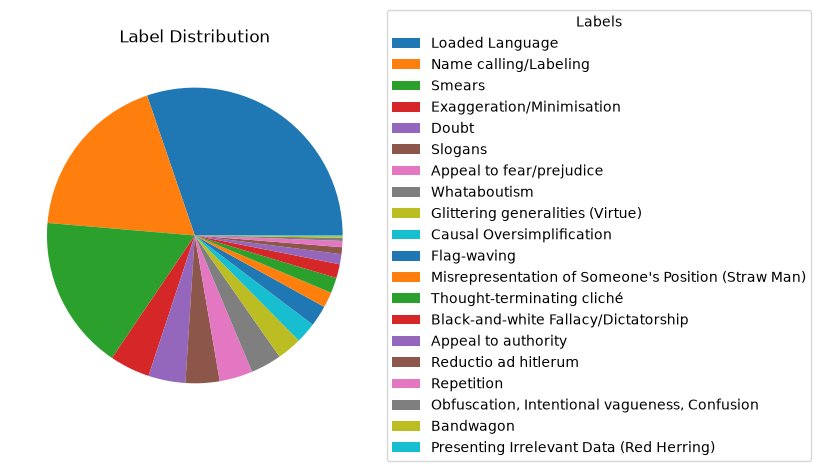

In [5]:
# Generate a Pie Chart to view label distribution.
label_counts = Counter(
    label
    for labels in train_set_task1["labels"]
    for label in labels
)

label_counts_df = pd.DataFrame(label_counts.items(), columns = ["Label", "Count"]).sort_values(by = "Count", ascending = False)

wedges, _ = plt.pie(label_counts_df["Count"].values)

plt.legend(wedges,
           label_counts_df["Label"].values,
           title="Labels",
           bbox_to_anchor=(1, 0.5),
           loc="center left")

plt.title("Label Distribution")

In [6]:
# View the actual counts for each label
label_counts.most_common()

[('Loaded Language', 358),
 ('Name calling/Labeling', 218),
 ('Smears', 200),
 ('Exaggeration/Minimisation', 52),
 ('Doubt', 48),
 ('Slogans', 44),
 ('Appeal to fear/prejudice', 43),
 ('Whataboutism', 40),
 ('Glittering generalities (Virtue)', 32),
 ('Causal Oversimplification', 27),
 ('Flag-waving', 27),
 ("Misrepresentation of Someone's Position (Straw Man)", 20),
 ('Thought-terminating cliché', 20),
 ('Black-and-white Fallacy/Dictatorship', 18),
 ('Appeal to authority', 13),
 ('Reductio ad hitlerum', 9),
 ('Repetition', 8),
 ('Obfuscation, Intentional vagueness, Confusion', 4),
 ('Bandwagon', 2),
 ('Presenting Irrelevant Data (Red Herring)', 1)]

### Label Encoding

I need to transform my labels from a string into a one hot encoded vector representation. The following code allows me to do that.

In [7]:
# Encode the labels as a One Hot Encoded vector representation
label_to_idx = {label : i for i, label in enumerate(LABELS)}

def encode_labels(labels):
    encoded = [0] * len(LABELS)
    for label in labels:
        encoded[label_to_idx[label]] = 1

    return torch.tensor(encoded, dtype=torch.float32)

train_set_task1["label_encoded"] = train_set_task1["labels"].apply(encode_labels)
test_set_task1["label_encoded"] = test_set_task1["labels"].apply(encode_labels)
dev_set_task1["label_encoded"] = dev_set_task1["labels"].apply(encode_labels)

train_set_task1.head()

,id,labels,text,label_encoded
0,128,[Black-and-white Fallacy/Dictatorship],THERE ARE ONLY TWO GENDERS\n\nFEMALE \n\nMALE\n,"[tensor(0.), tensor(0.), tensor(1.), tensor(0...."
1,189,[],This is not an accident!,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
2,96,"[Loaded Language, Name calling/Labeling, Sloga...",SO BERNIE BROS HAVEN'T COMMITTED VIOLENCE EH?\...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
3,154,"[Causal Oversimplification, Loaded Language, N...",PATHETIC\n\nThe Cowardly Asshole\nWeak Failure...,"[tensor(0.), tensor(0.), tensor(0.), tensor(1...."
4,15,[],WHO TRUMP REPRESENTS\n\nWHO DEMOCRATS REPRESENT\n,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."


## Utilities

Here I create some general utility functions which will be used across my tasks. 

#### Generating Label Weights

I create a label weight map such that I can use it later in my loss calculations in order to solve the problem of label inequality. For my baseline, I use inverse frequency class weighting, it gives values with low label counts higher weights, such that the model should prioritize labelling minority labels correctly. 

Viewing the generated label weights for task 1, I notice several potential issues, which I will explain and improve on further on in model experiments.

In [8]:
# Generating Label Weights
task1_label_counts = Counter(label
                             for labels in train_set_task1["labels"]
                             for label in labels)

total = len(train_set_task1)
total_labels = len(LABELS)

task1_label_weights = torch.tensor(
    [
    (total - task1_label_counts[label]) / (task1_label_counts[label])
    if task1_label_counts[label] > 0 else 1
    for label in LABELS
    ]
).to(device)

print('Label weights for Task 1:')
for i, label in enumerate(LABELS):
    print(
        f"{label:<55} "
        f"count={task1_label_counts[label]:>3} "
        f"weight={task1_label_weights[i].item():.2f}"
    )

Label weights for Task 1:
Appeal to authority                                     count= 13 weight=51.92
Appeal to fear/prejudice                                count= 43 weight=15.00
Black-and-white Fallacy/Dictatorship                    count= 18 weight=37.22
Causal Oversimplification                               count= 27 weight=24.48
Doubt                                                   count= 48 weight=13.33
Exaggeration/Minimisation                               count= 52 weight=12.23
Flag-waving                                             count= 27 weight=24.48
Glittering generalities (Virtue)                        count= 32 weight=20.50
Loaded Language                                         count=358 weight=0.92
Misrepresentation of Someone's Position (Straw Man)     count= 20 weight=33.40
Name calling/Labeling                                   count=218 weight=2.16
Obfuscation, Intentional vagueness, Confusion           count=  4 weight=171.00
Presenting Irrelevant Data 

#### Training Utilities (Adapted from Labs)

Here I adapt some utility functions straight from the labs so that they will fit the multi-label classification problem that we have. 

In [9]:
def train_one_epoch(model, loader, optimizer, criterion, tokenizer_mode=False):
    # Function adapted from Week 8 Labs.
    """
    Trains one epoch of the model using data from the dataloader.
    Calculates loss as according to the criterion and does backpropogation.
    Returns the mean loss for this epoch
    """
    
    model.train()
    total_loss, total = 0.0, 0
    for batch in loader:
        if tokenizer_mode:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            y = batch['labels'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=y)
            logits = outputs.logits
            loss = criterion(logits, y).to(device)
        else:
            x, y, lengths = batch
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y).to(device)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * y.numel()
        total += y.numel()
    return total_loss / total


def evaluate_model(model, loader, criterion, tokenizer_mode=False):
    # Function adapted from Week 8 labs
    """
    Evaluation function used to calculate validation loss during training.
    """
    
    model.eval()
    total_loss, total = 0.0, 0
    with torch.inference_mode():
        for batch in loader:
            if tokenizer_mode:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                y = batch['labels'].to(device)
                outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=y)
                logits = outputs.logits
                loss = criterion(logits, y).to(device)
            else:
                x, y, lengths = batch
                x, y = x.to(device), y.to(device)
                logits = model(x)
                loss = criterion(logits, y).to(device)
            
            total_loss += loss.item() * y.numel()
            total += y.numel()
    return total_loss / total


def run_experiment(model, optimizer, criterion, train_loader, val_loader,
                   epochs=10, name='Model', tokenizer_mode=False, load_best_model=True):
    # Function adapted from Week 8 labs.
    """
    Main training loop.
    Trains a model across 'epochs' epochs.
    If we want to, we can save the best performing model as according to the validation loss (helps with overfitting).
    Returns a dictionary which contains our training and validation loss across epochs.
    """
    
    history = {'train_loss': [], 'val_loss': []}
    best_model = None
    best_loss = 999999
    
    for epoch in range(epochs):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, tokenizer_mode)
        val_loss = evaluate_model(model, val_loader, criterion, tokenizer_mode)
        
        if val_loss < best_loss:
            best_loss = val_loss
            best_model = copy.deepcopy(model.state_dict())
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        if (epoch + 1) % max(1, epochs // 5) == 0 or epoch == 0:
            print(f'  [{name}] Epoch {epoch+1}/{epochs} — '
                  f'Train: {train_loss:.4f} | Val: {val_loss:.4f}')
    
    if load_best_model and best_model is not None:
        model.load_state_dict(best_model)
    
    return history


def plot_experiments(results, models = ["all"], show_train=True, show_val=True):
    # Function adapted from Week 8 labs.
    """
    Plots the loss curve of all models in results.
    """
    fig, ax = plt.subplots()
    
    if "all" in models:
        for name, hist in results.items():
            epochs = range(1, len(hist['train_loss']) + 1)
            if show_train:
                ax.plot(epochs, hist['train_loss'], label=f'{name} (Train)', marker='o', markersize=3)
            if show_val:
                ax.plot(epochs, hist['val_loss'], label=f'{name} (Val)', linestyle='--', marker='x', markersize=3)
    else:
        for name in models:
            hist = results[name]
            epochs = range(1, len(hist['train_loss']) + 1)
            if show_train:
                ax.plot(epochs, hist['train_loss'], label=f'{name} (Train)', marker='o', markersize=3)
            if show_val:
                ax.plot(epochs, hist['val_loss'], label=f'{name} (Val)', linestyle='--', marker='x', markersize=3)
    ax.set_xlabel('Epoch'); ax.set_ylabel("Loss"); ax.set_title("Loss")
    ax.legend(fontsize=8); ax.grid(True, linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()

I also create a custom evaluation function get_evaluation() which I will be using to evaluate my task 1 models. It uses creates a classification report of the model's predictions vs ground truth giving per-class precision, recall, f1-score and accuracy counts, as well as overall micro and macro averaged values for those values. Then it creates a multi-label confusion matrix and returns both of them as a tuple. This will help get better insight at how the model is predicting on each label.

In [10]:
def get_evaluation(model, val_loader, name, tokenizer_mode = False, prob_thresholds = None):
    """
    Custom model-specific evaluation method for Task 1 models.
    Calculates the model's evaluation metrics across per-label evaluation, micro, macro and weighted.
    Creates n confusion matrices where n corresponds to the number of labels.
    """
    model.eval()
    val_predictions = []
    val_true = []
    total_tp, total_tn, total_fp, total_fn = 0, 0, 0, 0
    
    # Use custom probability thresholds for each label if we pass it in.
    # Otherwise use a default value of 0.5 as a prob threshold for every label.
    if prob_thresholds != None:
        prob_thresholds = torch.tensor(prob_thresholds).to(device)
    else:
        prob_thresholds = torch.full((20,), 0.5).to(device)
    
    with torch.inference_mode():
        # Generates the YTrue and YPred for our model.
        for batch in val_loader:
            if tokenizer_mode:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                y = batch['labels'].to(device)
                outputs = model(input_ids=input_ids, 
                                attention_mask=attention_mask, 
                                labels=y)
                logits = outputs.logits
            else:
                x, y, lengths = batch
                x, y = x.to(device), y.to(device)
                logits = model(x)
            
            probabilities = torch.sigmoid(logits)
            prediction = (probabilities >= prob_thresholds).float()
            
            val_predictions.append(prediction)
            val_true.append(y)
    
    val_predictions = torch.cat(val_predictions, dim=0).cpu().numpy()
    val_true = torch.cat(val_true, dim=0).cpu().numpy()
    
    # Generate the confusion matrix
    matrix = multilabel_confusion_matrix(val_true, 
                                         val_predictions)
    
    # Generate the classification report
    report = classification_report(val_true, 
                                    val_predictions, 
                                    target_names=LABELS, 
                                    output_dict = True)

    # Modify the current matrix and report to plot each matrix as a seperate plot on a 5x5 grid.
    # And add accuracy as a metric for the report.    
    fig, ax = plt.subplots(4, 5, figsize = (10,10))

    for i, label in enumerate(LABELS):
        current_ax = ax[i//5][i%5]
        current_row = report[label]
        
        cf = ConfusionMatrixDisplay(matrix[i])
        cf.plot(ax = current_ax,cmap='Blues', colorbar = False)
        current_ax.set_title(label[:20], fontsize=10)
        
        tn, fp, fn, tp = matrix[i].ravel()
        
        total_tp += tp
        total_fp += fp
        total_fn += fn
        total_tn += tn
        
        accuracy = (tp + tn) / (tp + tn + fn + fp) if (tp + tn + fn + fp) > 0 else 0
        current_row["accuracy"] = accuracy

    fig.suptitle(name)
    fig.subplots_adjust(wspace = 0.5, hspace = 1)
    
    # Calculate model overall accuracy on the data.    
    total_accuracy = (total_tp + total_tn) / (total_fp + total_fn + total_tp + total_tn)
    
    return fig, report, total_accuracy 


def view_report(report):
    """
    Helper function to view the report in a user-friendly manner.
    """
    print(f"{'':>23}{'precision':>12}{'recall':>12}{'f1-score':>12}{'support':>12}{'accuracy':>12}")

    for label, values in report.items():
        if isinstance(values, dict):
            print(
                f"{label[:20]:<23}"
                f"{values.get('precision', 0):>12.4f}"
                f"{values.get('recall', 0):>12.4f}"
                f"{values.get('f1-score', 0):>12.4f}"
                f"{values.get('support', 0):>12.0f}"
                f"{values.get('accuracy', 0):>12.4f}"
            )

#### Positional Encoder (Taken from Labs)

For transformer models, we need a way to encode the position of a token into the actual input. Sinusoidal encoding is a proven-to-work method of doing this from Google's "Attention Is All You Need" paper. I adapt this same encoder from Week 8 labs.

In [11]:
class PositionalEncoding(nn.Module):
    # Adapted from Week 8 Labs.
    """Sinusoidal positional encoding from 'Attention Is All You Need'."""
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)  # (1, max_len, d_model)
        self.register_buffer('pe', pe)
    
    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

#### Tokenizer

I also create a very basic tokenizer which I will use to split the text data. 

In [12]:
def simple_tokenize(text : str):
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', '', text)
    return text.split()

print(simple_tokenize("THOSE LIBERALS HATE ME\n\nIT'S BECAUSE I'M BLACK ISN'T IT ?\n"))

['those', 'liberals', 'hate', 'me', 'its', 'because', 'im', 'black', 'isnt', 'it']


In [13]:
generator = torch.Generator()
generator.manual_seed(67)

# Task 1

## Evaluation Metric:

For Task 1 we need to create a model that can take a meme and determine its employed techniques, such that a user is able to take the returned labels and can justify why that meme uses said techniques. What is important to note is that a meme's used techniques is not a measured variable, but labelled by a team of analysts, who use their own judgements to decide which memes get which technique labels. Because it is not an exact science, there is a lot of interpretability in the air for why a meme might be labelled using one technique and not another. 

If a meme was not labelled to use a specific technique which the model flags as it using, the user might be able to make their own justifications on why the model believes the meme uses that technique. However, if a meme was labelled to use a specific technique, but the model did not flag it correctly, it is a missed opportunity for the presenter to explain why the meme uses that technique. Hence, the costs of incurring False Positives should not be as costly as making False Negatives. Which is why I want to prioritze Recall as one of our evaluation metrics. F1-Score will be used as a secondary evaluation metric in order to ensure good recall scores are not taken at the expense of abysmal precision scores.

However, our model is also highly imbalanced, with many labels having very few positive samples. This might give the regular macro scores a bit of ambiguity when interpreting it, as it gives each label equal importance when getting mean scores, and does not lend itself to class imbalance. Weighted average, which can be taken from classification_report might give us better insight into model performance as it prioritizes majority classes. I will use both the macro and weighted scores to evaluate each model, as the weighted scores will give me a better understanding of overall performance, but may obscure the model's performances in minority labels.

Additionally, I have added accuracy as a measured metric for classification report. I will be using accuracy as an additional metric to evaluate each model, however, since it by itself can be misleading and not give us the full picture that precision, recall and f1-score can, it will only be used as a secondary evaluation metric.

As a naive estimate, I want to aim for a weighted recall score of ~0.65 or macro recall score of ~0.5 with an weighted/macro F1 score of ~0.5. A weighted recall score of 0.5 means that the model is able to correctly label 50% of the positive labels as being correctly positive. Trying to go past 0.5 might negatively effect our precision, with a goal of 0.5 for F1 score, it means I'd need a minimum precision of 0.5 which means that roughly half of the positive labelled samples are truly positive. Weighted recall is higher because I want the recall for my majority labels to perform a lot better then the minority labels.

## Building the Detector:

For Task 1, I will need to simply create a model that can predict the employed techniques of a single meme. I will first create a baseline model using LSTM, try to improve it via a sleugh of experiments, such as modifying class weights, using pretrained dense embeddings, etc. Then I will create several other models, such as using a self-trained or pre-trained transformer and compare all of the model's performances.  


## Preparing the Dataset

### Building Vocabulary

For the basic vocabulary building, we do a very simple mapping of mapping each unique token in the corpus to a new integer in order of their rarity within the corpus. I decide to use a max length of 64, as seeing the distribution of meme lengths in the data, >75% of memes are quite short and are well below this threshold, with only a few memes being cut off. 

Vocabulary: 407, Max length: 64


Text(0.5, 1.0, 'Length of Memes')

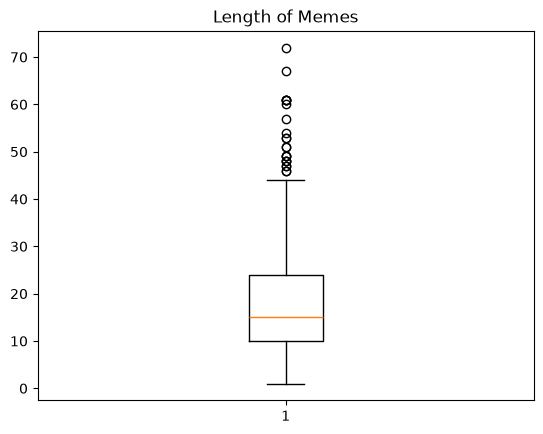

In [14]:
# Build vocabulary
all_train_tokens = [simple_tokenize(t) for t in train_set_task1["text"]]
word_counts = Counter()
for tokens in all_train_tokens:
    word_counts.update(tokens)

# Create two special tokens <PAD> and <UNK> to represent text-padding and unknown tokens respectively.
PAD_IDX, UNK_IDX = 0, 1
word_to_idx = {'<PAD>': PAD_IDX, '<UNK>': UNK_IDX}
idx = 2
for word, count in word_counts.most_common():
    # Ignore extremely niche tokens.
    if count >= 5:
        word_to_idx[word] = idx
        idx += 1
    else:
        break

VOCAB_SIZE = len(word_to_idx)
MAX_LEN = 64
print(f'Vocabulary: {VOCAB_SIZE}, Max length: {MAX_LEN}')

# View the distribution of meme lengths according to our tokenizer.
plt.boxplot([len(train_token) for train_token in all_train_tokens])
plt.title("Length of Memes")

In [15]:
# Dataset class (same as Week 7)
class TextDataset(Dataset):
    def __init__(self, texts, labels, word_to_idx, tokenizer = simple_tokenize, max_len=MAX_LEN):
        self.labels = labels
        self.sequences, self.lengths = [], []
        for text in texts:
            tokens = tokenizer(text)
            indices = [word_to_idx.get(t, UNK_IDX) for t in tokens[:max_len]]
            self.lengths.append(len(indices))
            indices += [PAD_IDX] * (max_len - len(indices))
            self.sequences.append(indices)
    
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        return (
            torch.tensor(self.sequences[idx], dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.float32),
            self.lengths[idx],
        )

train_ds = TextDataset(train_set_task1["text"], train_set_task1["label_encoded"], word_to_idx)
val_ds = TextDataset(dev_set_task1["text"], dev_set_task1["label_encoded"], word_to_idx)
test_ds = TextDataset(test_set_task1["text"], test_set_task1["label_encoded"], word_to_idx)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, generator=generator)
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, generator=generator)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, generator=generator)

## Models

### BASELINE MODEL (LSTM)

For my baseline model, I will be using a simple RNN, specifically LSTM. RNNs typically have many drawbacks relating to vanishing gradients due to the influence of earlier tokens being overwritten as time goes on. LSTM does aim to solve this problem by using several gates, however, they will still eventually fall to the same drawback. For this task specifically, however, the lengths of a meme should intuitively, not be too long. This is backed up by the boxplot of lengths of our memes below, which backs up that the median length of a meme is only ~15 tokens, which should theoretically be short enough to not fall to the vanishing gradient problem. It will most likely struggle on the longer memes, especially the high outliers of lengths >50. However, we can fix that in the later experiments.

In [16]:
# Baseline RNN model using LSTM.
class LSTMModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        
        self.rnn = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        
        self.fc = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, num_classes),
        )
    
    def forward(self, x):
        x = self.embedding(x)
        output, hidden = self.rnn(x)
        
        hidden = hidden[0]
        
        return self.fc(hidden[-1])

### Training the Model:

The model seems to steadily learn in both the Training data as well as on the validation data. It seems to perform best at around epoch ~35. However, the model begins exhibiting signs of overfitting past epoch ~40 as training loss continues to decrease while validation loss spikes and trends upwards as epochs increases.

Parameters: 127,956


C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),


  [RNN] Epoch 1/50 — Train: 1.2683 | Val: 1.6655
  [RNN] Epoch 10/50 — Train: 1.2646 | Val: 1.6709
  [RNN] Epoch 20/50 — Train: 1.2554 | Val: 1.6864
  [RNN] Epoch 30/50 — Train: 1.2544 | Val: 1.6656
  [RNN] Epoch 40/50 — Train: 1.2354 | Val: 1.6487
  [RNN] Epoch 50/50 — Train: 1.1836 | Val: 1.6526


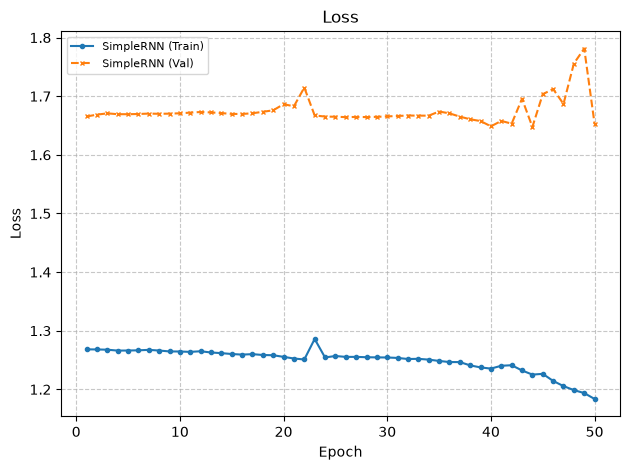

In [17]:
torch.manual_seed(67)
rnn_model = LSTMModel(
    VOCAB_SIZE, 64, 128, len(LABELS)
).to(device)

optimizer = optim.Adam(rnn_model.parameters(), lr=5e-4)
criterion = nn.BCEWithLogitsLoss(pos_weight=task1_label_weights)

print(f'Parameters: {sum(p.numel() for p in rnn_model.parameters()):,}')

SimpleRNN_results = {} 
SimpleRNN_results["SimpleRNN"] = run_experiment(
    rnn_model, optimizer, criterion, train_loader, val_loader,
    epochs=50, name='RNN'
)

plot_experiments(SimpleRNN_results)

### Evaluating the Model:

A low macro precision heavily implies that the model is currently making many False Positives. Looking at the per label precisions we see that most of the labels have precisions < 0.1. Severe minority labels such as Obfuscation and Red Herring exhibit near zero precisions or completely 0 precision as the model is completely unable to correctly label a positive sample. Although macro recall gets close to our naive benchmark. The low F1-scores for macro and weighted respectively shows that it comes at the cost of horrible precision. 

The model has a problem with predicting too many samples as positive for many labels, resulting in a spike of False Positives. 

C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", resu

                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.0312      0.1429      0.0513           7      0.8150
Appeal to fear/preju         0.0789      0.3000      0.1250          10      0.7900
Black-and-white Fall         0.0400      1.0000      0.0769           7      0.1600
Causal Oversimplific         0.0500      0.6667      0.0930           3      0.8050
Doubt                        0.1707      0.2500      0.2029          28      0.7250
Exaggeration/Minimis         0.1176      0.2105      0.1509          19      0.7750
Flag-waving                  0.0306      1.0000      0.0594           6      0.0500
Glittering generalit         0.1515      0.4545      0.2273          11      0.8300
Loaded Language              0.7000      0.2800      0.4000         100      0.5800
Misrepresentation of         0.0000      0.0000      0.0000           1      0.7900
Name calling/Labelin         0.3824      0.2453      0.2989          53     

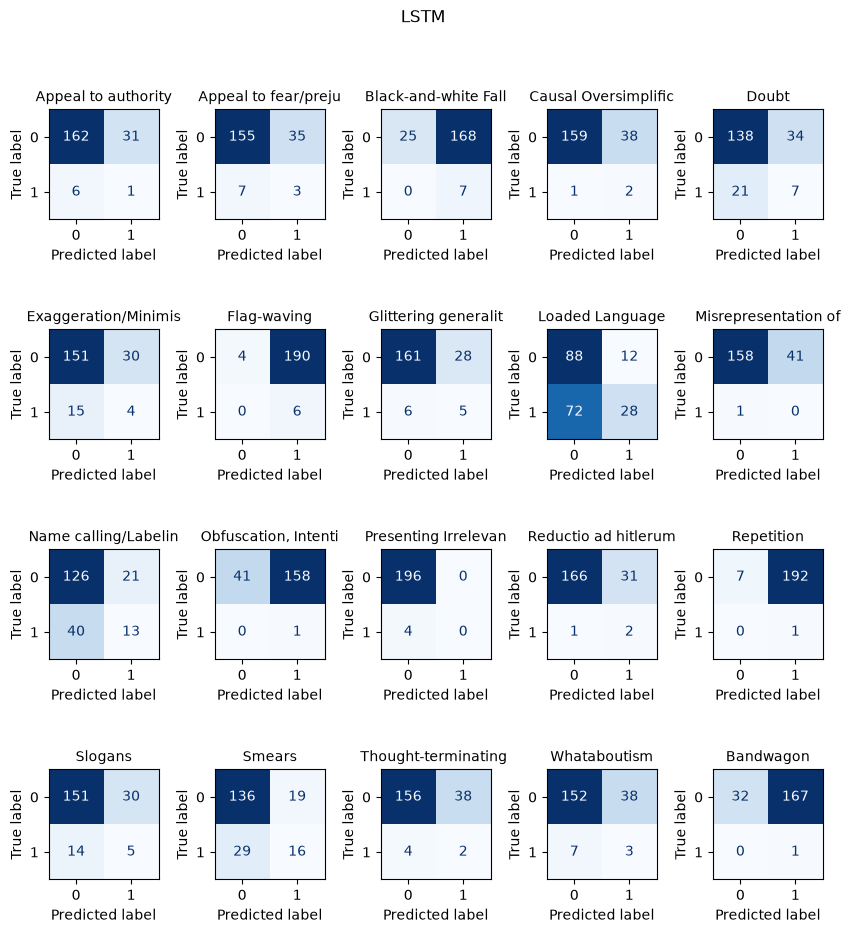

In [18]:
fig, report, accuracy = get_evaluation(rnn_model, test_loader, "LSTM")

view_report(report)
print(f"Total Accuracy: {accuracy}")

### Experiment 1: Pre-trained Dense Embeddings

For my first experiment, I would like to try to introduce pretrained Dense embeddings into our model rather than create these embeddings ourselves. By using a pretrained embedding space, each token's semantic meaning can be represented in the vector space as deemed fit by some large training data. This should make the model "understand" the meaning of each meme better so that it can make better decisions.

### GloVe:

I decide to choose GloVe as my pretrained embedder of choice. Specifically the 6B version which has an embedding dimension of 50 and is pretrained on a corpus of wikipedia articles, I decide to use this version rather than the others which have higher embedding dimensions simply because it is the smallest model which should fit our needs for this small experiment. If we decide later to use this model, with the GloVe embeddings, I might use the one with the bigger embedding dimension to improve performance. Because the corpus is very general it should be able to capture almost all tokens that we throw at it. 

In [19]:
# Taken from Week 7 Labs.

# Download GloVe 6B (50d — smallest version, ~66MB)
import urllib.request
import zipfile

GLOVE_DIM = 50
GLOVE_FILE = f'glove.6B.{GLOVE_DIM}d.txt'

if not os.path.exists(GLOVE_FILE):
    print('Downloading GloVe embeddings...')
    urllib.request.urlretrieve(
        'https://nlp.stanford.edu/data/glove.6B.zip', 'glove.6B.zip'
    )
    with zipfile.ZipFile('glove.6B.zip', 'r') as z:
        z.extract(GLOVE_FILE)
    print('Done.') 
else:
    print(f'{GLOVE_FILE} already exists.')

glove.6B.50d.txt already exists.


In [20]:
# Taken from Week 7 Labs.

# Load GloVe into a dictionary
def load_glove(filepath, dim):
    embeddings = {}
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            word = parts[0]
            vector = np.array(parts[1:], dtype=np.float32)
            if len(vector) == dim:
                embeddings[word] = vector
    return embeddings

glove = load_glove(GLOVE_FILE, GLOVE_DIM)
print(f'Loaded {len(glove):,} GloVe vectors ({GLOVE_DIM}d)')

# Check coverage
covered = sum(1 for w in word_to_idx if w in glove)
print(f'Vocabulary coverage: {covered}/{len(word_to_idx)} ({covered/len(word_to_idx)*100:.1f}%)')

Loaded 400,000 GloVe vectors (50d)
Vocabulary coverage: 402/407 (98.8%)


In [21]:
# Taken from Week 7 Labs.

def create_embedding_matrix(word_to_idx, glove, embed_dim):
    """Create an embedding matrix with GloVe vectors for known words."""
    matrix = np.zeros((len(word_to_idx), embed_dim))
    found, missing = 0, 0

    for word, idx in word_to_idx.items():
        if word in glove:
            matrix[idx] = glove[word]
            found += 1
        else:
            # Random initialisation for unknown words
            if word == "<PAD>":
                continue

            matrix[idx] = np.random.normal(scale=0.6, size=embed_dim)
            missing += 1

    print(f'Embedding matrix: {matrix.shape}')
    print(f'  Found in GloVe: {found}, Missing: {missing}')
    return torch.tensor(matrix, dtype=torch.float32)

embedding_matrix = create_embedding_matrix(word_to_idx, glove, GLOVE_DIM)

Embedding matrix: (407, 50)
  Found in GloVe: 402, Missing: 4


In [22]:
class DenseLSTM(nn.Module):
    def __init__(self, embedding_matrix, num_classes, hidden_dim, freeze_embeddings=True):
        super().__init__()
        
        vocab_size, embed_dim = embedding_matrix.shape
        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix, freeze=freeze_embeddings, padding_idx=PAD_IDX
        )

        self.rnn = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        
        self.fc = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, num_classes)
        )
    
    def forward(self, x):
        x = self.embedding(x)
        output, hidden = self.rnn(x)
        
        hidden = hidden[0]
        
        return self.fc(hidden[-1])

### Training the Model:

Not much of note has changed while training this new model. The model still has steady training progress until around > epoch 40 where it begins to overfit to the training data. Training loss values has not decreased by much compared to the previous model.

Parameters: 115,090
  [DenseLSTM] Epoch 1/50 — Train: 1.2677 | Val: 1.6896


C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),


  [DenseLSTM] Epoch 10/50 — Train: 1.2678 | Val: 1.6939
  [DenseLSTM] Epoch 20/50 — Train: 1.2491 | Val: 1.6744
  [DenseLSTM] Epoch 30/50 — Train: 1.2343 | Val: 1.6165
  [DenseLSTM] Epoch 40/50 — Train: 1.1942 | Val: 1.6294
  [DenseLSTM] Epoch 50/50 — Train: 1.2650 | Val: 1.7285


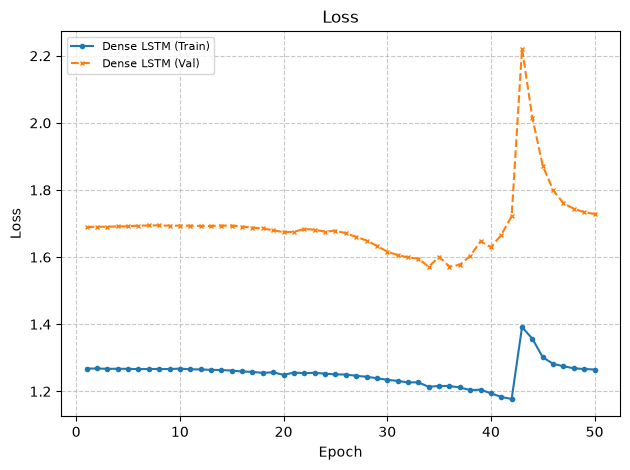

In [23]:
torch.manual_seed(67)
dense_lstm = DenseLSTM(
    embedding_matrix=embedding_matrix,
    num_classes=len(LABELS),
    hidden_dim=128,
    freeze_embeddings=True
).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight = task1_label_weights)
optimizer = optim.Adam(dense_lstm.parameters(), lr=5e-4)

print(f'Parameters: {sum(p.numel() for p in dense_lstm.parameters()):,}')

DenseLSTM_Results = {}
DenseLSTM_Results['Dense LSTM'] = run_experiment(
    dense_lstm, optimizer, criterion, train_loader, val_loader,
    epochs=50, name='DenseLSTM'
)

plot_experiments(DenseLSTM_Results)

### Evaluating the Model

The model seems to show minor improvements over the baseline model. Although our macro recall has dropped, our weighted recall actually stays exactly the same. Whereas recall seems to minorly improve, which is best seen by comparing the two's micro avg precision. Although macro and weighted precisions maintain around the same level as the previous model. Furthermore, accuracy seems to improve between models which is the largest improvement over the previous model. While macro f1-scores have slightly decreased, weighted f1 increases. 

What these might imply is that the model has improved its recall abilities on the majority labels, but at a cost of decreasing recall on some of the minority labels, hence why macro recall would drop, as it treats every label as equally weighted, but weighted recall increases due to the significance of majority labels. Looking at the per label evaluation scores, we do see a decrease in recall in several minority labels, however, two notable increases in recall in the majority labels Loaded Language and Name Calling, which could explain our behaviour. 

Furthermore, looking at the confusion matrices, we see that this model is producing far less false positives than the previous, which leads to an increase in the count of True Negatives. This would explain both the slightly increased precision, as the model, which may have better learnt how to better distinguish positive and negative samples, is able to decrease the number of false positives. However, as this would also result in a slight decrease in true positives and a slight increase in false negatives, the positive effect on precision is counteracted. Although accuracy overall would increase.

C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.0377      0.2857      0.0667           7      0.7200
Appeal to fear/preju         0.0952      0.8000      0.1702          10      0.6100
Black-and-white Fall         0.0444      0.8571      0.0845           7      0.3500
Causal Oversimplific         0.0267      0.6667      0.0513           3      0.6300
Doubt                        0.1605      0.4643      0.2385          28      0.5850
Exaggeration/Minimis         0.1333      0.5263      0.2128          19      0.6300
Flag-waving                  0.0311      1.0000      0.0603           6      0.0650
Glittering generalit         0.1067      0.7273      0.1860          11      0.6500
Loaded Language              0.6543      0.5300      0.5856         100      0.6250
Misrepresentation of         0.0000      0.0000      0.0000           1      0.5900
Name calling/Labelin         0.3289      0.4717      0.3876          53     

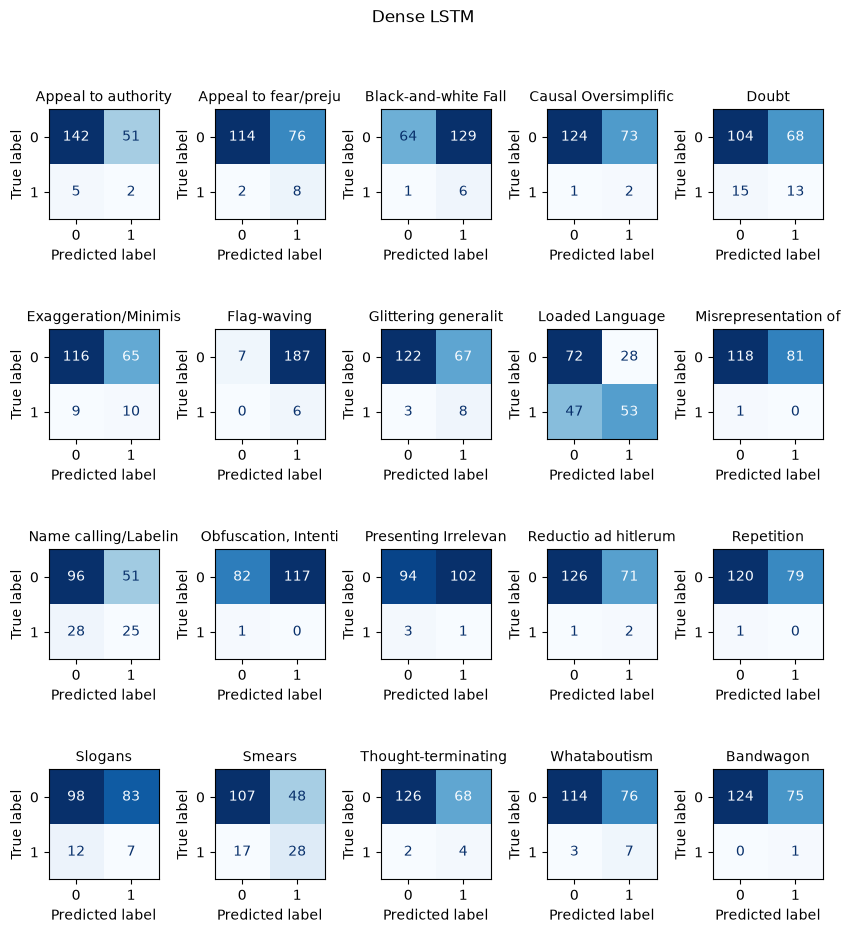

In [24]:
fig, report, accuracy = get_evaluation(dense_lstm, test_loader, "Dense LSTM")

view_report(report)
print(f"Total Accuracy: {accuracy}")

Our problems of having too many False Positives from the previous model, although decreased, still exists within the model. Meaning that there is something else which I will have to address. One observation I have made is that a majority of False Positives comes from minority labels, most obviously seen in Black and White Fallacy, Flag Waving, Obfuscation, etc. The label weights that I have created might be causing this problem. Viewing the generated label weights here, we see that a majority of minority labels have had their weights blown up, the most extreme ones being in the mid hundreds and Red Herring which has one positive sample has a weight of 687. These blown up weights means that creating a False Negative will be much more costly on these minority labels, and as such the model may be inclined to more likely label these classes as positive to try to avoid incurring these costs. 

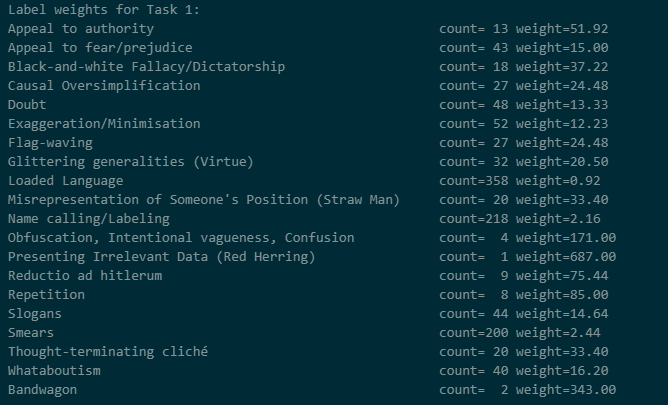

### Experiment 2: Fine Tuning Dense Embeddings (REJECTED)

Before addressing that issue, I would first also like to take time to see whether fine tuning the pretrained embeddings might also be worthwhile to do. The idea is that although we have a very general corpus for the trained embeddings, fine tuning the general embeddings of each token for our specific problem might make the model perform better.

### Training the Model:

The model's training is very similar to that of Experiment 1, not much of note is changed from those said in Experiment 1. 

Parameters: 115,090
  [DenseLSTM (Finetuned)] Epoch 1/50 — Train: 1.2682 | Val: 1.6897


C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),


  [DenseLSTM (Finetuned)] Epoch 10/50 — Train: 1.2660 | Val: 1.6869
  [DenseLSTM (Finetuned)] Epoch 20/50 — Train: 1.2480 | Val: 1.6676
  [DenseLSTM (Finetuned)] Epoch 30/50 — Train: 1.2565 | Val: 1.6957
  [DenseLSTM (Finetuned)] Epoch 40/50 — Train: 1.2233 | Val: 1.5984
  [DenseLSTM (Finetuned)] Epoch 50/50 — Train: 1.1740 | Val: 1.6906


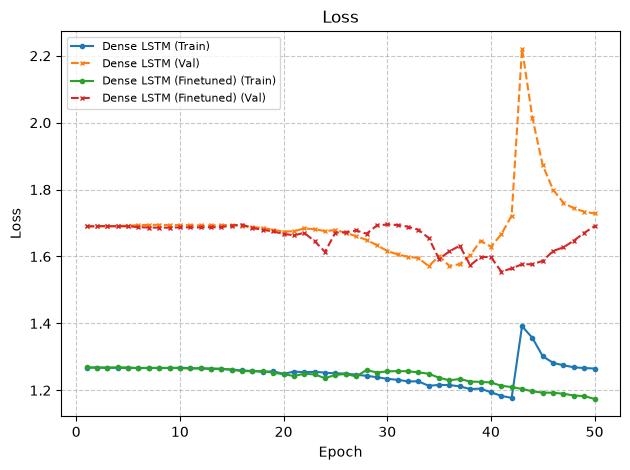

In [25]:
# Turn off freeze embeddings, to allow fine tuning on the embedding layer. 
torch.manual_seed(67)
dense_lstm_fine_tune = DenseLSTM(
    embedding_matrix=embedding_matrix,
    num_classes=len(LABELS),
    hidden_dim=128,
    freeze_embeddings=False
).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=task1_label_weights)
optimizer = optim.Adam(dense_lstm_fine_tune.parameters(), lr=5e-4)

print(f'Parameters: {sum(p.numel() for p in dense_lstm_fine_tune.parameters()):,}')

DenseLSTM_Results['Dense LSTM (Finetuned)'] = run_experiment(
    dense_lstm_fine_tune, optimizer, criterion, train_loader, val_loader,
    epochs=50, name='DenseLSTM (Finetuned)'
)

plot_experiments(DenseLSTM_Results)

### Evaluating the Model:

Overall trying to fine tune the model did not change much about its performance over the pretrained embeddings. All of precision, recall, f1 and accuracy all have very minor changes, none of which are substantially better or worse than without fine tuning. Nor did the model fix any of the underlying issues that we had with the previous model. Furthermore, due to the additional computational cost that we will have to incur by training all of the weights in the embedding layer, I do not believe that the results reflected in the fine tuned LSTM are substantial enough to warrant that cost which is why I decide to reject it.

C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.0597      0.5714      0.1081           7      0.6700
Appeal to fear/preju         0.0899      0.8000      0.1616          10      0.5850
Black-and-white Fall         0.0377      0.5714      0.0708           7      0.4750
Causal Oversimplific         0.0241      0.6667      0.0465           3      0.5900
Doubt                        0.1728      0.5000      0.2569          28      0.5950
Exaggeration/Minimis         0.1299      0.5263      0.2083          19      0.6200
Flag-waving                  0.0465      0.6667      0.0870           6      0.5800
Glittering generalit         0.0959      0.6364      0.1667          11      0.6500
Loaded Language              0.6353      0.5400      0.5838         100      0.6150
Misrepresentation of         0.0000      0.0000      0.0000           1      0.5950
Name calling/Labelin         0.3049      0.4717      0.3704          53     

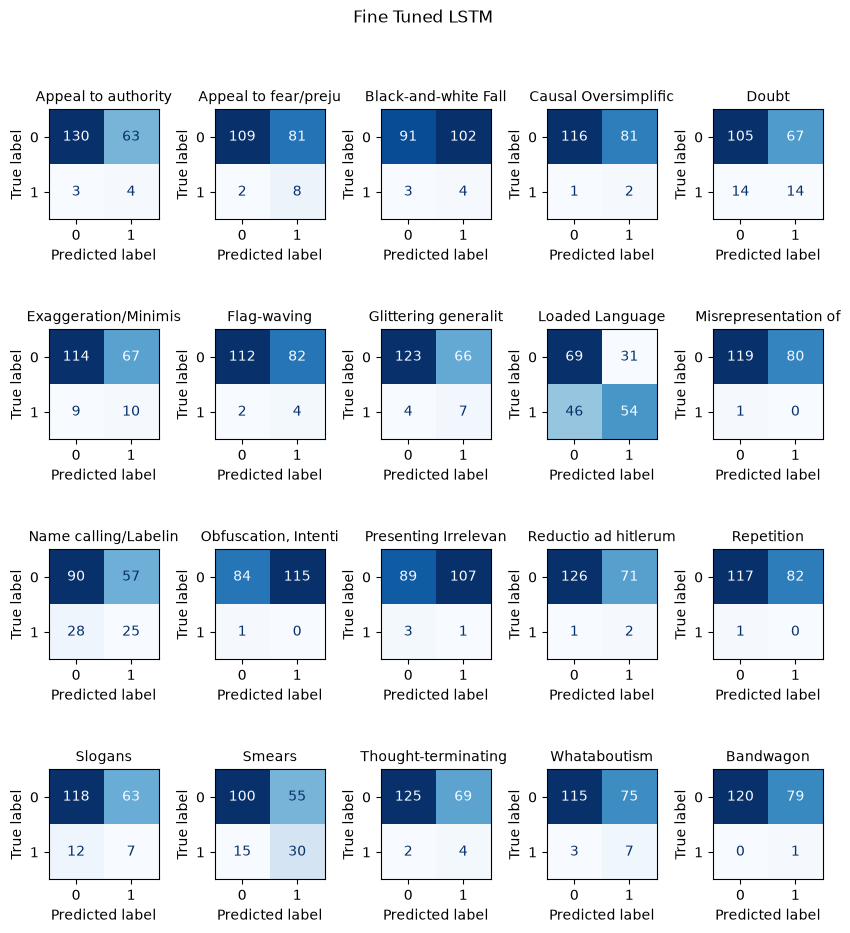

In [26]:
fig, report, accuracy = get_evaluation(dense_lstm_fine_tune, test_loader, "Fine Tuned LSTM")

view_report(report)
print(f"Total Accuracy: {accuracy}")

### Experiment 3: Modify Class Weight

To address the problems brought up in Experiment 1, I decide to modify my label weights by testing different weight calculations. These include: square root transformation, log transformation and simple clamping. 

In [27]:
# Do a square root transformation. Should reduce the effects of exploded weights while maintaining the balance.
task1_sqrt_weights = torch.sqrt(task1_label_weights)

# Do log transformation. Much more aggressive reduction for the exploded weights.
task1_log_weights = torch.tensor(
    [
        math.log1p(total / task1_label_counts[label])
        if task1_label_counts[label] > 0 else 1
        for label in LABELS
    ]
).to(device)

# Clamping. Does not change the reduction technique but just clamps it so weights don't explode. 
MAX_WEIGHT = 80
MIN_WEIGHT = 0
task1_clamped_weights = torch.clamp(task1_label_weights, min = MIN_WEIGHT, max = MAX_WEIGHT)

print('Sqrt Label weights for Task 1:')
for i, label in enumerate(LABELS):
    print(
        f"{label:<55} "
        f"count={task1_label_counts[label]:>3} "
        f"weight={task1_sqrt_weights[i].item():.2f}"
    )
    
print('Log Label weights for Task 1:')
for i, label in enumerate(LABELS):
    print(
        f"{label:<55} "
        f"count={task1_label_counts[label]:>3} "
        f"weight={task1_log_weights[i].item():.2f}"
    )

print('Clamped Label weights for Task 1:')
for i, label in enumerate(LABELS):
    print(
        f"{label:<55} "
        f"count={task1_label_counts[label]:>3} "
        f"weight={task1_clamped_weights[i].item():.2f}"
    )

Sqrt Label weights for Task 1:
Appeal to authority                                     count= 13 weight=7.21
Appeal to fear/prejudice                                count= 43 weight=3.87
Black-and-white Fallacy/Dictatorship                    count= 18 weight=6.10
Causal Oversimplification                               count= 27 weight=4.95
Doubt                                                   count= 48 weight=3.65
Exaggeration/Minimisation                               count= 52 weight=3.50
Flag-waving                                             count= 27 weight=4.95
Glittering generalities (Virtue)                        count= 32 weight=4.53
Loaded Language                                         count=358 weight=0.96
Misrepresentation of Someone's Position (Straw Man)     count= 20 weight=5.78
Name calling/Labeling                                   count=218 weight=1.47
Obfuscation, Intentional vagueness, Confusion           count=  4 weight=13.08
Presenting Irrelevant Data (Red 

In [28]:
torch.manual_seed(67)
dense_lstm_sqrt_weight = DenseLSTM(
    embedding_matrix=embedding_matrix,
    num_classes=len(LABELS),
    hidden_dim=128,
    freeze_embeddings=True
).to(device)

optimizer = optim.Adam(dense_lstm_sqrt_weight.parameters(), lr=5e-4)
criterion = nn.BCEWithLogitsLoss(pos_weight=task1_sqrt_weights)

print(f'Parameters: {sum(p.numel() for p in dense_lstm_sqrt_weight.parameters()):,}')

ModifiedWeights_Results = {}
ModifiedWeights_Results['RNN Sqrt Weights'] = run_experiment(
    dense_lstm_sqrt_weight, optimizer, criterion, train_loader, val_loader,
    epochs=50, name='RNN Sqrt Weights'
)

Parameters: 115,090
  [RNN Sqrt Weights] Epoch 1/50 — Train: 0.7703 | Val: 0.7989


C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),


  [RNN Sqrt Weights] Epoch 10/50 — Train: 0.5087 | Val: 0.6224
  [RNN Sqrt Weights] Epoch 20/50 — Train: 0.5084 | Val: 0.6280
  [RNN Sqrt Weights] Epoch 30/50 — Train: 0.5087 | Val: 0.6275
  [RNN Sqrt Weights] Epoch 40/50 — Train: 0.5067 | Val: 0.6301
  [RNN Sqrt Weights] Epoch 50/50 — Train: 0.5061 | Val: 0.6273


In [29]:
torch.manual_seed(67)
dense_lstm_log_weight = DenseLSTM(
    embedding_matrix=embedding_matrix,
    num_classes=len(LABELS),
    hidden_dim=128,
    freeze_embeddings=True
).to(device)

optimizer = optim.Adam(dense_lstm_log_weight.parameters(), lr=5e-4)
criterion = nn.BCEWithLogitsLoss(pos_weight=task1_log_weights)

print(f'Parameters: {sum(p.numel() for p in dense_lstm_log_weight.parameters()):,}')

ModifiedWeights_Results['RNN log Weights'] = run_experiment(
    dense_lstm_log_weight, optimizer, criterion, train_loader, val_loader,
    epochs=50, name='RNN Sqrt Weights'
)

Parameters: 115,090
  [RNN Sqrt Weights] Epoch 1/50 — Train: 0.7357 | Val: 0.7445


C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),


  [RNN Sqrt Weights] Epoch 10/50 — Train: 0.4067 | Val: 0.4637
  [RNN Sqrt Weights] Epoch 20/50 — Train: 0.4028 | Val: 0.4668
  [RNN Sqrt Weights] Epoch 30/50 — Train: 0.3988 | Val: 0.4665
  [RNN Sqrt Weights] Epoch 40/50 — Train: 0.4013 | Val: 0.4661
  [RNN Sqrt Weights] Epoch 50/50 — Train: 0.4004 | Val: 0.4648


Parameters: 115,090
  [RNN Clamped Weights] Epoch 1/50 — Train: 1.1880 | Val: 1.3885


C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),


  [RNN Clamped Weights] Epoch 10/50 — Train: 1.1538 | Val: 1.4544
  [RNN Clamped Weights] Epoch 20/50 — Train: 1.1497 | Val: 1.4254
  [RNN Clamped Weights] Epoch 30/50 — Train: 1.1389 | Val: 1.4345
  [RNN Clamped Weights] Epoch 40/50 — Train: 1.0921 | Val: 1.3787
  [RNN Clamped Weights] Epoch 50/50 — Train: 1.0582 | Val: 1.4449


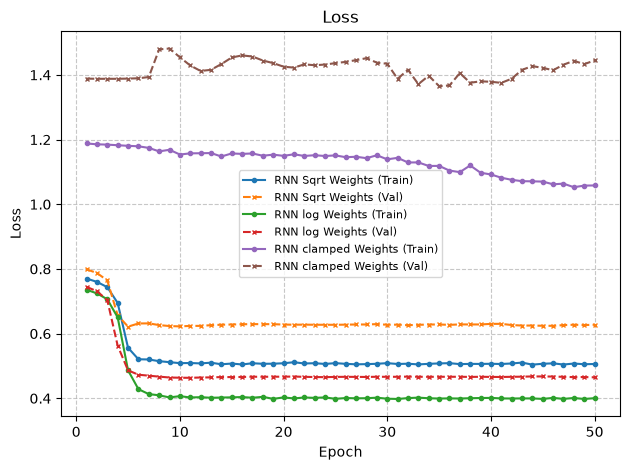

In [30]:
torch.manual_seed(67)
dense_lstm_clamped_weight = DenseLSTM(
    embedding_matrix=embedding_matrix,
    num_classes=len(LABELS),
    hidden_dim=128,
    freeze_embeddings=True
).to(device)

optimizer = optim.Adam(dense_lstm_clamped_weight.parameters(), lr=5e-4)
criterion = nn.BCEWithLogitsLoss(pos_weight=task1_clamped_weights)

print(f'Parameters: {sum(p.numel() for p in dense_lstm_clamped_weight.parameters()):,}')

ModifiedWeights_Results['RNN clamped Weights'] = run_experiment(
    dense_lstm_clamped_weight, optimizer, criterion, train_loader, val_loader,
    epochs=50, name='RNN Clamped Weights'
)

plot_experiments(ModifiedWeights_Results)

C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", resu

                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.0000      0.0000      0.0000           7      0.9650
Appeal to fear/preju         0.0000      0.0000      0.0000          10      0.9500
Black-and-white Fall         0.0000      0.0000      0.0000           7      0.9650
Causal Oversimplific         0.0000      0.0000      0.0000           3      0.9850
Doubt                        0.0000      0.0000      0.0000          28      0.8600
Exaggeration/Minimis         0.0000      0.0000      0.0000          19      0.9050
Flag-waving                  0.0000      0.0000      0.0000           6      0.9700
Glittering generalit         0.0000      0.0000      0.0000          11      0.9450
Loaded Language              0.0000      0.0000      0.0000         100      0.5000
Misrepresentation of         0.0000      0.0000      0.0000           1      0.9950
Name calling/Labelin         0.0000      0.0000      0.0000          53     

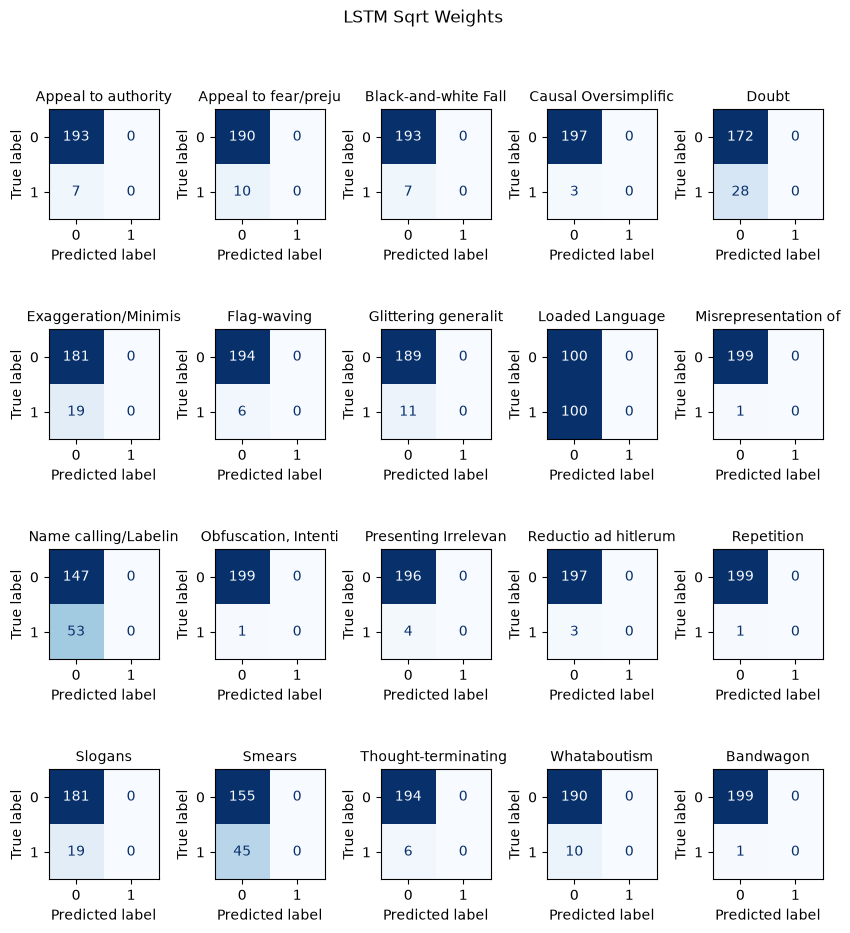

In [31]:
fig, report, accuracy = get_evaluation(dense_lstm_sqrt_weight, test_loader, "LSTM Sqrt Weights")

view_report(report)
print(f"Total Accuracy: {accuracy}")

C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", resu

                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.0000      0.0000      0.0000           7      0.9650
Appeal to fear/preju         0.0000      0.0000      0.0000          10      0.9500
Black-and-white Fall         0.0000      0.0000      0.0000           7      0.9650
Causal Oversimplific         0.0000      0.0000      0.0000           3      0.9850
Doubt                        0.0000      0.0000      0.0000          28      0.8600
Exaggeration/Minimis         0.0000      0.0000      0.0000          19      0.9050
Flag-waving                  0.0000      0.0000      0.0000           6      0.9700
Glittering generalit         0.0000      0.0000      0.0000          11      0.9450
Loaded Language              0.5000      1.0000      0.6667         100      0.5000
Misrepresentation of         0.0000      0.0000      0.0000           1      0.9950
Name calling/Labelin         0.0000      0.0000      0.0000          53     

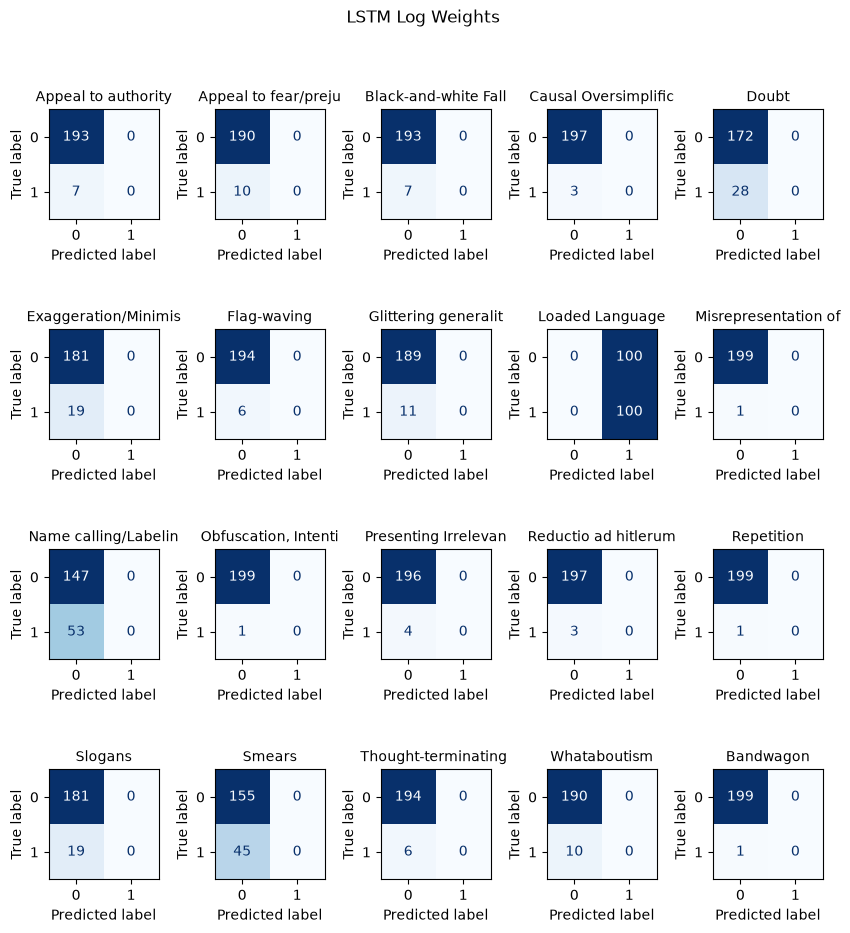

In [32]:
fig, report, accuracy = get_evaluation(dense_lstm_log_weight, test_loader, "LSTM Log Weights")

view_report(report)
print(f"Total Accuracy: {accuracy}")

C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", resu

                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.0693      1.0000      0.1296           7      0.5300
Appeal to fear/preju         0.0737      0.7000      0.1333          10      0.5450
Black-and-white Fall         0.0441      0.4286      0.0800           7      0.6550
Causal Oversimplific         0.0280      1.0000      0.0545           3      0.4800
Doubt                        0.1759      0.6786      0.2794          28      0.5100
Exaggeration/Minimis         0.1207      0.7368      0.2074          19      0.4650
Flag-waving                  0.0238      0.3333      0.0444           6      0.5700
Glittering generalit         0.0776      0.8182      0.1417          11      0.4550
Loaded Language              0.5752      0.6500      0.6103         100      0.5850
Misrepresentation of         0.0093      1.0000      0.0183           1      0.4650
Name calling/Labelin         0.2500      0.5472      0.3432          53     

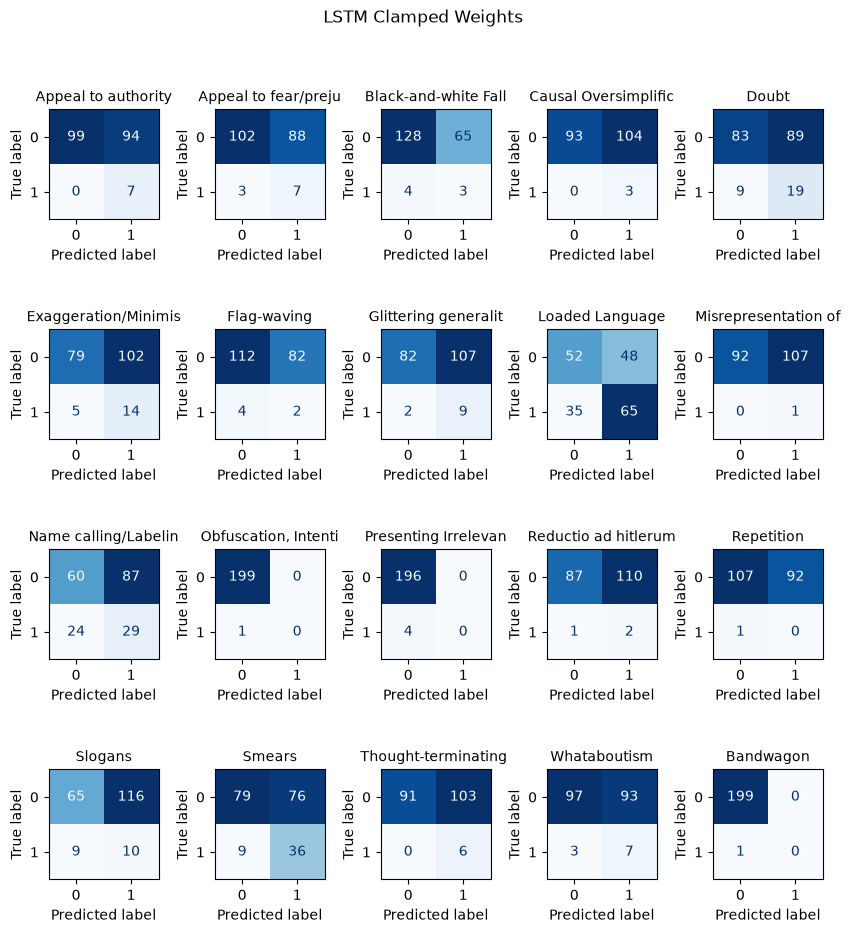

In [33]:
fig, report, accuracy = get_evaluation(dense_lstm_clamped_weight, test_loader, "LSTM Clamped Weights")

view_report(report)
print(f"Total Accuracy: {accuracy}")

### Evaluating the Model(s):

I will disregard the Sqrt and Log weights, as even just from a quick look at their confusion matrices, it is clear that there is an extreme case of overfitting and no generalization to be had. For every label within those models, they are labelled always positive or always negative. They are completely unfit. I believe that this is due to the fact that the log and square root transformations, although reducing the blown up class weights have at the same time also lost the magnitude of the class weights that we needed for good prediction behaviour. Clamped weights on the other hand seems to be somewhat fit for further evaluation.

Notable changes in the prediction behaviour when using the clamped weights can be summarized as a major increase in macro and weighted recall, a slight increase in macro and weighted f1-scores, at a cost of slightly reduced precision and overall model accuracy. Although it should be noted that while macro and weighted precisions decreased, micro precision actually increased. 

Comparing their confusion matrices, three labels stand out. The three severe minority labels: Obfuscation, Red Herring and Bandwagon have almost completely stopped predicting positive samples for their data. With the knowledge that these three labels are the ones most effected by the clamped weights, my hypothesis is that because of their previously blown up weight values, the model could not learn properly for these samples and so explained their erratic behaviours in the previous models. However, with a clamped weights, the cost of errors calms down for these models and the model can learn to classify these models as being negative. 

Although this seems to be a step forward in the right direction, it does not seem that exploded weights are the sole reason for our model's False Positive problem.

### The Severe Label Imbalance Problem:

One of the issues that we have had for the past few models is a precision, recall and f1-score of 0 on some of the severe minority labels, namely Red Herring, Obfuscation and Bandwagon. These are the labels with the fewest number of positive samples in the entire dataset, especially because there is only ~1-4 positive samples in the testing dataset, we will continue to have extremely unstable values of precision, recall and f1 score for these labels, making them unreliable metrics for those labels. As such these labels will be poor indicators for the model's overall performance. In the clamped weighting experiment, these labels underwent prediction collapse with the model predicting every sample as negative for those labels, however, I take this as a good news for the model as it removes all the false positives from those labels which the model previously made. As I would rather the model to very rarely or almost never flag a technique as being used than for it to flag a meme for a technique it very explicitly does not use.

Going back to my justification for recall over precision, while it is true that it is possible that the samples not marked for having a technique, may simply have it but not be labelled by the analysts, looking at a small list of the texts the model predicts as "Obfuscation" compared to the list of positives in the training data, there does not seem to be a common overlap that shows that both uses the same technique. To which I don't think the argument can stand anymore. 

In [34]:
obfuscation_data = train_set_task1[
    train_set_task1["labels"].apply(lambda x: "Obfuscation, Intentional vagueness, Confusion" in x)
]

for i in range(4):
    print(obfuscation_data["text"].iloc[i])

THE PEOPLE WHO ONCE CALLED OUR SOLDIERS BABY KILLERS

NOW MARCH FOR THE RIGHT TO KILL BABIES

21 people running for President and only 1 stands against killing babies

SORRY, BUT I DON'T LISTEN TO ANTI-GUN LECTURES FROM PEOPLE WHO THINK IT'S OK TO KILL A BABY.
"Spreading the chemtrails is actually quite easy."

"Getting them right to the edge of the Earth without flying off into space is the difficult part."




### Experiment 4: Adjusting Confidence Threshold

Another experiment I am thinking to solve the false-positive issues is by increasing the confidence threshold. Currently, by default we use probabilities above 0.5 to be a true label. However, the logic is that if we increase the minimum threshold, only samples where the model is extremely confident about its label will be flagged positive, lowering the number of positive labels, lowering the number of false positives. Additionally, we can configure the threshold for each label so that certain labels will need to be more confident and others can be less. This should allow us to finetune each label's flagging distribution, we can exhibit that behaviour on one label here.

In [35]:
# Check the evaluation metrics for each label when using different thresholds within the range (0.4 to 0.6)
thresholds = torch.arange(0.4, 0.61, 0.01)

precisions = []
recalls = []
f1_scores = []
accuracies = []

for threshold in thresholds:
    fig, report, acc = get_evaluation(
        dense_lstm_clamped_weight,
        val_loader,
        f"LSTM Threshold {threshold:.2f}",
        prob_thresholds=[threshold for i in range(len(LABELS))]
    )

    precisions.append(report["Loaded Language"]["precision"])
    recalls.append(report["Loaded Language"]["recall"])
    f1_scores.append(report["Loaded Language"]["f1-score"])
    accuracies.append(acc)
    
    plt.close(fig)

C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", resu

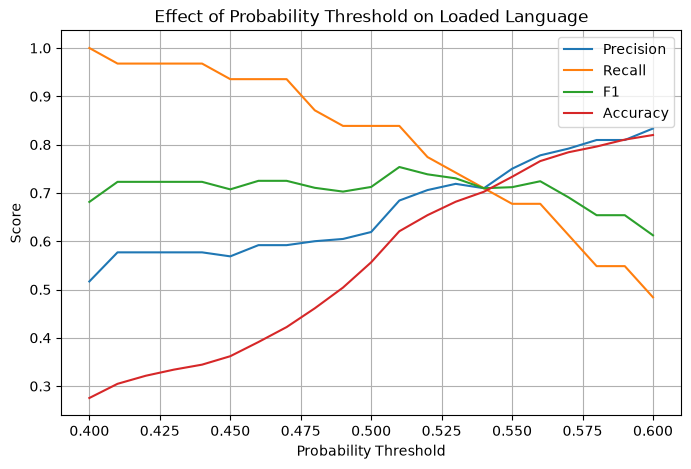

In [36]:
# View the effect of prob threshold on one Label, to prove that this will improve our model.
plt.figure(figsize=(8, 5))

plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")
plt.plot(thresholds, f1_scores, label="F1")
plt.plot(thresholds, accuracies, label="Accuracy")

plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Effect of Probability Threshold on Loaded Language")
plt.legend()
plt.grid()
plt.show()

In [37]:
def threshold_testing(label, model, loader = val_loader, tokenizer_mode=False):
    # Do the threshold testing before but per label and increase range to (0.3, 0.7)
    thresholds = torch.arange(0.3, 0.71, 0.01)

    precisions = []
    recalls = []
    f1_scores = []
    accuracies = []

    for threshold in thresholds:
        fig, report, acc = get_evaluation(
            model,
            loader,
            "",
            tokenizer_mode=tokenizer_mode,
            prob_thresholds=[threshold for i in range(len(LABELS))]
        )
        
        clear_output(True)

        precisions.append(report[label]["precision"])
        recalls.append(report[label]["recall"])
        f1_scores.append(report[label]["f1-score"])
        accuracies.append(acc)
        
        plt.close(fig)
    
    return thresholds, precisions, recalls, f1_scores, accuracies

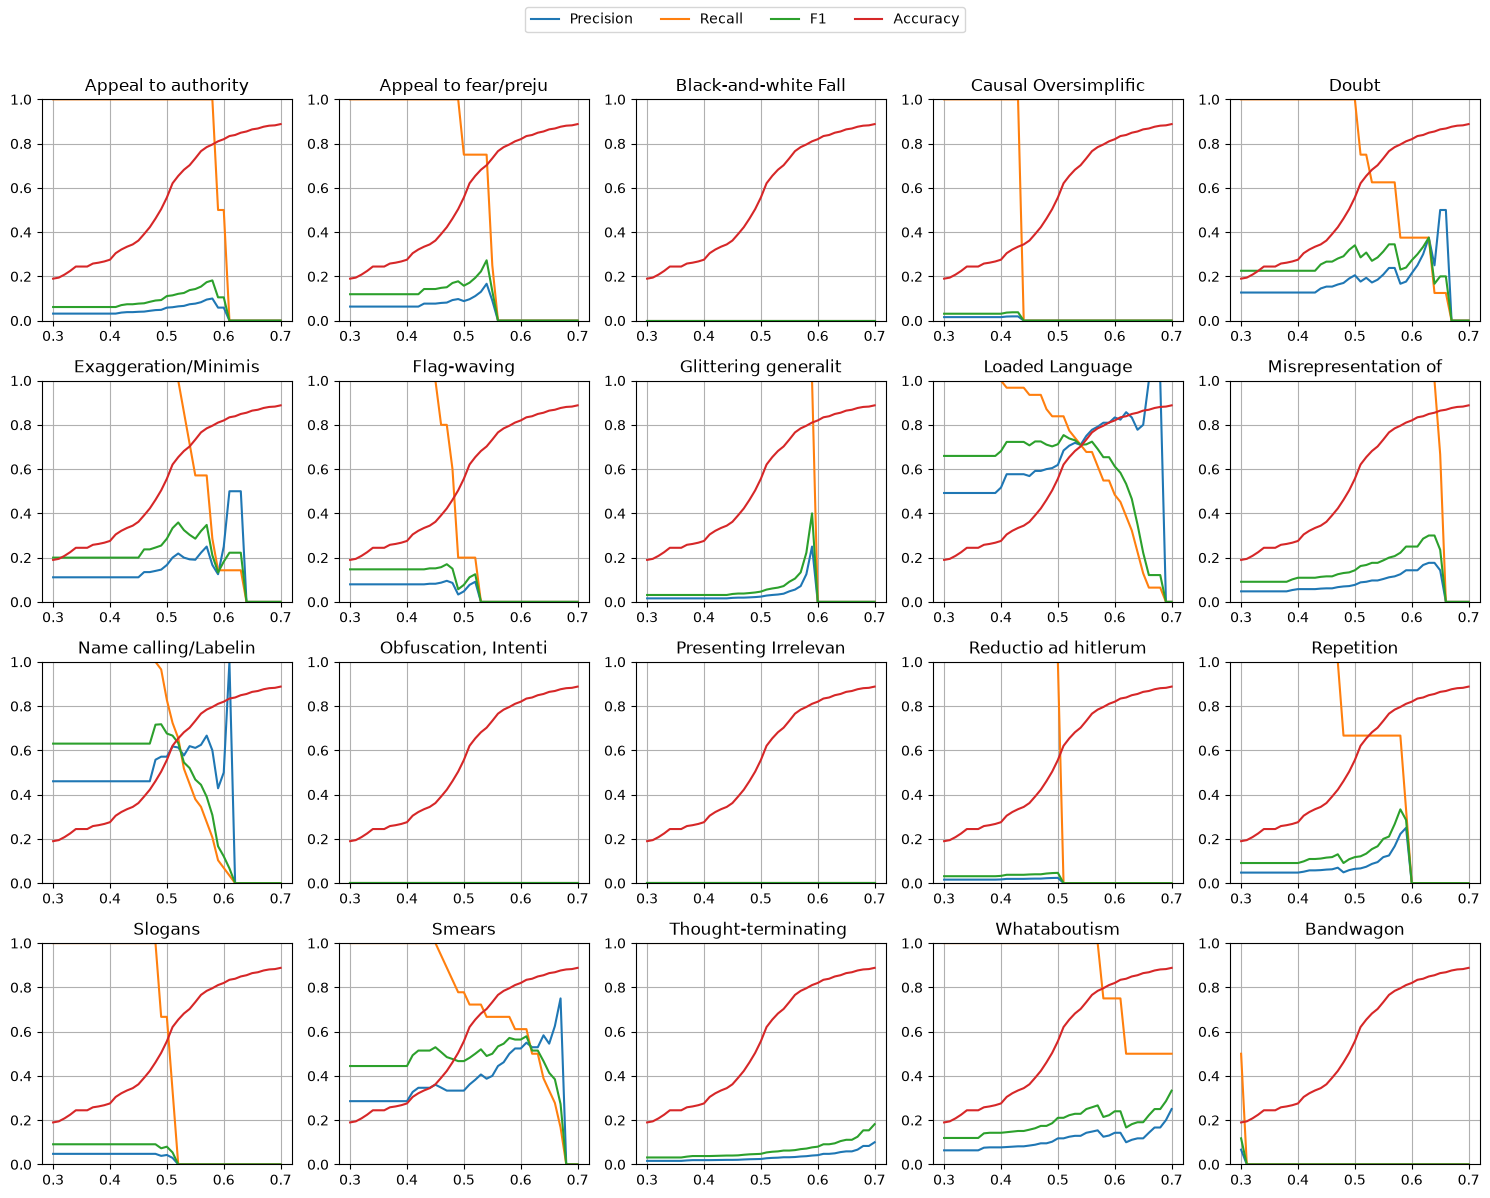

In [38]:
from IPython.display import clear_output

fig, ax = plt.subplots(4, 5, figsize=(15, 12))

# Do threshold testing on every model and plot their graphs. 
for i, label in enumerate(LABELS):
    thresholds, precisions, recalls, f1_scores, accuracies = threshold_testing(label, dense_lstm_clamped_weight)
    clear_output(True)

    current_ax = ax[i // 5, i % 5]

    current_ax.plot(thresholds, precisions, label="Precision")
    current_ax.plot(thresholds, recalls, label="Recall")
    current_ax.plot(thresholds, f1_scores, label="F1")
    current_ax.plot(thresholds, accuracies, label="Accuracy")

    current_ax.set_title(label[:20])
    current_ax.set_ylim(0, 1)
    current_ax.grid()
    
# Legends
handles, labels = ax[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [39]:
# Set the thresholds to what I deem to be appropriate threshold levels for each label.
# For labels where performance does not change too much from 0.5, we skip.
# For labels where the performance graph is too abnormal to interpret, we skip.
THRESHOLDS = torch.tensor([0.5 for i in range(len(LABELS))]).to(device)

THRESHOLDS[LABELS.index("Appeal to fear/prejudice")] = 0.65
THRESHOLDS[LABELS.index("Exaggeration/Minimisation")] = 0.45
THRESHOLDS[LABELS.index("Glittering generalities (Virtue)")] = 0.6
THRESHOLDS[LABELS.index("Loaded Language")] = 0.45
THRESHOLDS[LABELS.index("Misrepresentation of Someone's Position (Straw Man)")] = 0.55
THRESHOLDS[LABELS.index("Name calling/Labeling")] = 0.45
THRESHOLDS[LABELS.index("Repetition")] = 0.6

### Evaluation:

By simply adjusting the probability thresholds of several labels we are able to marginally increase some of our evaluation metrics. With the current set up of thresholds that I have made, I was able to substantially increase all micro metrics, weighted recall and model accuracies with only a slight tradeoff of slightly lower precision, which is made up for as can be seen with the slight uptick in f1-scores.

However, for the remaining experiments, I will not use these thresholds. Because the output of logits and probabilities for each model will vary wildly with different implementations, we cannot have one concrete set of thresholds which will work with every model. Threshold tuning will be a good tool to use for the final model, however, for experimentation I will leave them out. 

C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\794306680.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  prob_thresholds = torch.tensor(prob_thresholds).to(device)
C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\

                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.0693      1.0000      0.1296           7      0.5300
Appeal to fear/preju         0.0000      0.0000      0.0000          10      0.9500
Black-and-white Fall         0.0441      0.4286      0.0800           7      0.6550
Causal Oversimplific         0.0280      1.0000      0.0545           3      0.4800
Doubt                        0.1759      0.6786      0.2794          28      0.5100
Exaggeration/Minimis         0.0950      1.0000      0.1735          19      0.0950
Flag-waving                  0.0238      0.3333      0.0444           6      0.5700
Glittering generalit         0.1667      0.1818      0.1739          11      0.9050
Loaded Language              0.5676      0.8400      0.6774         100      0.6000
Misrepresentation of         0.0000      0.0000      0.0000           1      0.5850
Name calling/Labelin         0.2650      1.0000      0.4190          53     

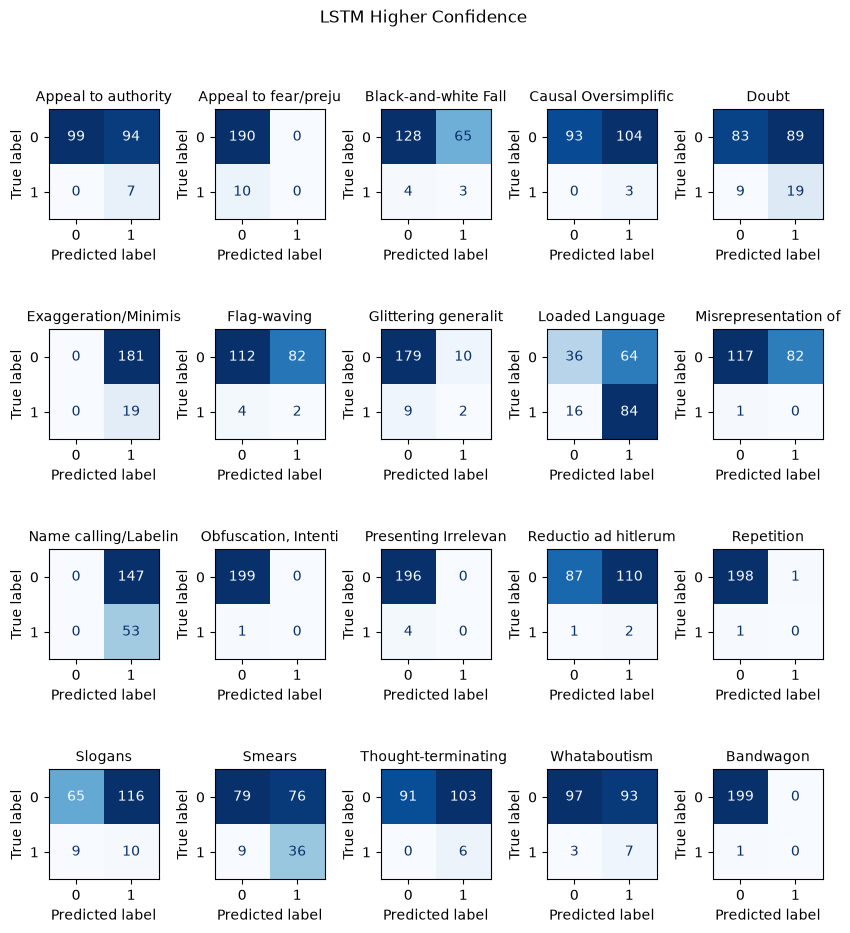

In [40]:
fig, report, accuracy = get_evaluation(dense_lstm_clamped_weight, test_loader, "LSTM Higher Confidence", prob_thresholds=THRESHOLDS)

view_report(report)
print(f"Total Accuracy: {accuracy}")

### Experiment 5: Transformers

Finally, I try to improve the model by switching to using a Transformer Encoder architecture. To do this, I modify the existing LSTM architecture to introduce a positional encoding layer using sinusoidal encoding, as well as a TransformerEncoder layer. The idea is that we are encountering a vanishing gradient problem as a result of LSTM's inherent drawbacks. Transformers aim to fix that problem by using multi-headed attention layers such that all tokens are able to view each other all at once and update themselves all at once, resulting in no information loss. 

In [41]:
class DenseTransformer(nn.Module):
    def __init__(self, embedding_matrix, num_heads, num_layers, num_classes, max_len=MAX_LEN, freeze_embeddings=True):
        super().__init__()
        
        vocab_size, embed_dim = embedding_matrix.shape
        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix, freeze=freeze_embeddings, padding_idx=PAD_IDX
        )

        self.pos_encoding = PositionalEncoding(embed_dim, max_len)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=0.1,
            batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        self.fc = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(embed_dim, num_classes)
        )
    
    def forward(self, x, lengths=None):
        # Create padding mask: True where padded
        pad_mask = (x == PAD_IDX)  # (batch, seq_len)
                
        x = self.embedding(x)
        x = self.pos_encoding(x)
        x = self.transformer(x, src_key_padding_mask=pad_mask)
        
        # Mean pooling (mask out padding)
        mask = (~pad_mask).unsqueeze(-1).float()  # (batch, seq_len, 1)
        x = (x * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        
        return self.fc(x)

### Training the Model:

Training the model was much more steady and loss decreases faster compared to the LSTM models. However, it began overfitting much earlier at around epoch ~23. 

Parameters: 82,670


C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\nn\modules\transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\NestedTensorImpl.cpp:181.)
  output = torch._nested_tensor_from_mask(


  [DenseTransformer] Epoch 1/50 — Train: 1.2488 | Val: 1.3808
  [DenseTransformer] Epoch 10/50 — Train: 1.0806 | Val: 1.3215
  [DenseTransformer] Epoch 20/50 — Train: 1.0201 | Val: 1.3091
  [DenseTransformer] Epoch 30/50 — Train: 0.9292 | Val: 1.3691
  [DenseTransformer] Epoch 40/50 — Train: 0.8492 | Val: 1.5057
  [DenseTransformer] Epoch 50/50 — Train: 0.7726 | Val: 1.6853


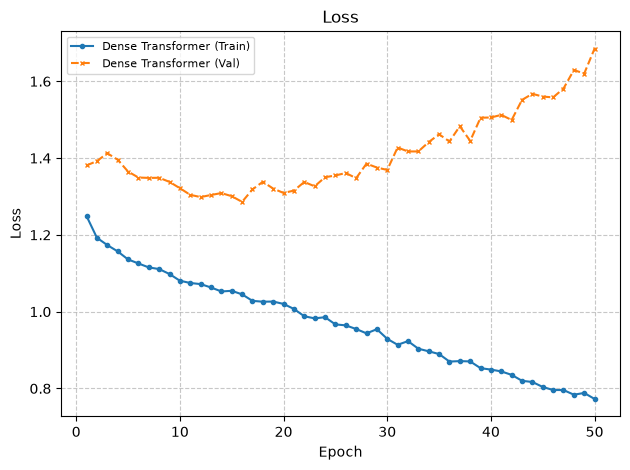

In [42]:
torch.manual_seed(67)
dense_tf = DenseTransformer(
    embedding_matrix=embedding_matrix,
    num_heads=2,
    num_layers=2,
    num_classes=len(LABELS),
    freeze_embeddings=True
).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=task1_clamped_weights)
optimizer = optim.Adam(dense_tf.parameters(), lr=5e-4)

print(f'Parameters: {sum(p.numel() for p in dense_tf.parameters()):,}')

DenseTransformer_Results = {}
DenseTransformer_Results['Dense Transformer'] = run_experiment(
    dense_tf, optimizer, criterion, train_loader, val_loader,
    epochs=50, name='DenseTransformer'
)

plot_experiments(DenseTransformer_Results)

### Evaluating the Model:

Comparing this to the dense lstm with clamped weights (but not with confidence thresholds to make a fair comparison), the model seems to substantially increase precision at a slight cost to recall, although f1-Scores stay roughly the same. Accuracy also increases drastically with this model. I notice an over the board substantial decrease in the number of false positives, which is reflected in the higher accuracy, higher precision, but lower recall. It appears that this model can better generalize to the task over the LSTM, which might be a result of LSTM's vanishing gradients issue which harm it specifically in this task. 

C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\2240541016.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.labels[idx], dtype=torch.float32),
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} i

                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.0619      1.0000      0.1167           7      0.4700
Appeal to fear/preju         0.1311      0.8000      0.2254          10      0.7250
Black-and-white Fall         0.0588      0.5714      0.1067           7      0.6650
Causal Oversimplific         0.0317      0.6667      0.0606           3      0.6900
Doubt                        0.1978      0.6429      0.3025          28      0.5850
Exaggeration/Minimis         0.1400      0.3684      0.2029          19      0.7250
Flag-waving                  0.0667      0.5000      0.1176           6      0.7750
Glittering generalit         0.0946      0.6364      0.1647          11      0.6450
Loaded Language              0.6458      0.6200      0.6327         100      0.6400
Misrepresentation of         0.0000      0.0000      0.0000           1      0.6200
Name calling/Labelin         0.2727      0.5094      0.3553          53     

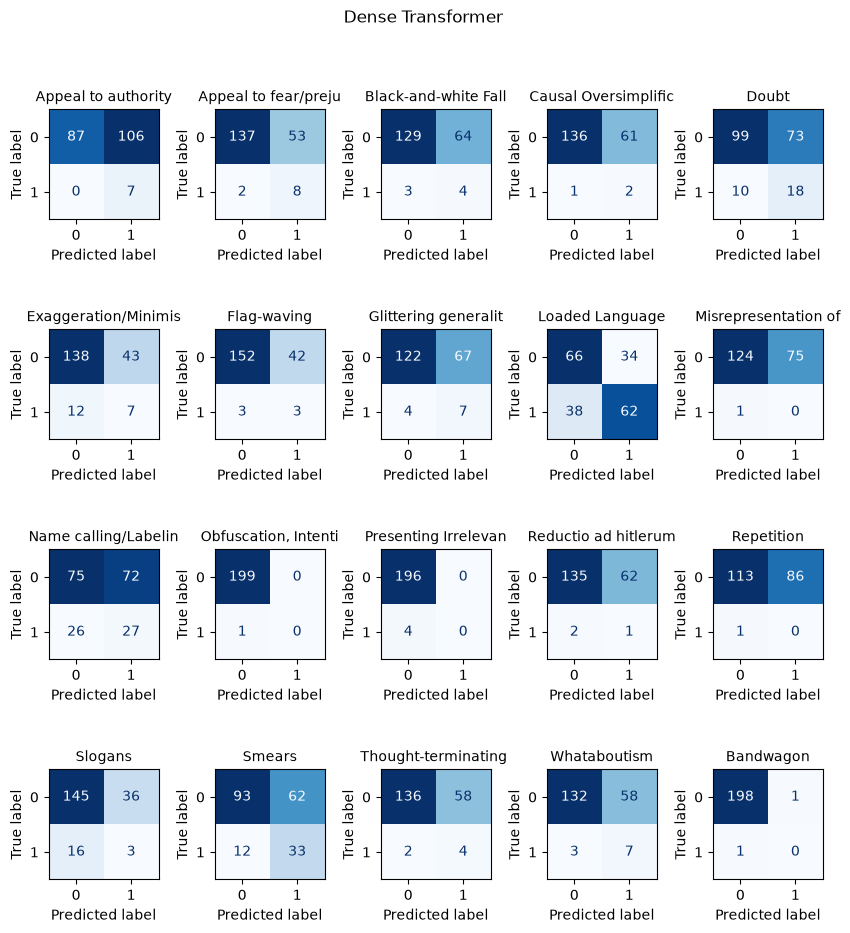

In [43]:
fig, report, accuracy = get_evaluation(dense_tf, test_loader, "Dense Transformer")

view_report(report)
print(f"Total Accuracy: {accuracy}")

### Pre-trained Transformer

Rather than train a new transformer from scratch, pretrained transformers which are trained on a general corpus and will already have "good" weights for general use might be better for our task. I decide to use distilbert-base-uncased as my pretrained transformer of choice due to its generalization abilities, being trained on Wikipedia data and its performance-cost ratio due to having comparable results to BERT while having a fraction of the size. 

In [44]:
# Taken from Lab Week 8
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')

test_sentences = [
    "I am unbelievably happy today!",
    "My son's first steps were amazing.",
    "I can't believe I won $100!",
]

for sent in test_sentences:
    simple_tokens = str(sent).lower().split()
    tf_tokens = tokenizer.tokenize(sent)
    print(f'Original:    "{sent}"')
    print(f'Simple:      {simple_tokens}')
    print(f'Transformer: {tf_tokens}')
    print()

Original:    "I am unbelievably happy today!"
Simple:      ['i', 'am', 'unbelievably', 'happy', 'today!']
Transformer: ['i', 'am', 'un', '##bel', '##ie', '##va', '##bly', 'happy', 'today', '!']

Original:    "My son's first steps were amazing."
Simple:      ['my', "son's", 'first', 'steps', 'were', 'amazing.']
Transformer: ['my', 'son', "'", 's', 'first', 'steps', 'were', 'amazing', '.']

Original:    "I can't believe I won $100!"
Simple:      ['i', "can't", 'believe', 'i', 'won', '$100!']
Transformer: ['i', 'can', "'", 't', 'believe', 'i', 'won', '$', '100', '!']



I also check that max_len of 64 would still be suitable using this new tokenizer. Although overall token length has increased, because a majority of memes are already below 64, as well as the high potential cost of increasing the max length to 128 tokens, I decide max length of 64 is still suitable.

['there', 'are', 'only', 'two', 'gender', '##s', 'female', 'male']


Text(0.5, 1.0, 'Length of Memes')

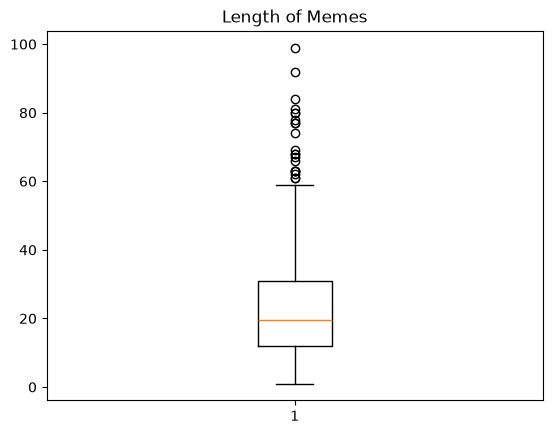

In [45]:
# Build vocabulary
all_train_tokens = [tokenizer.tokenize(t) for t in train_set_task1["text"]]
print(all_train_tokens[0])

# View the distribution of meme lengths according to our tokenizer.
plt.boxplot([len(train_token) for train_token in all_train_tokens])
plt.title("Length of Memes")

In [46]:
# Taken from Lab Week 8
encoded = tokenizer(
    "I am unbelievably happy",
    padding='max_length',
    truncation=True,
    max_length=12,
    return_tensors='pt'
)

print('Token IDs:      ', encoded['input_ids'][0].tolist())
print('Attention mask:  ', encoded['attention_mask'][0].tolist())
print('Decoded tokens:  ', tokenizer.convert_ids_to_tokens(encoded['input_ids'][0]))
print()
print('Notice:')
print('  - [CLS] at the start, [SEP] at the end')
print('  - "unbelievably" is split into subwords: un, ##believab, ##ly')
print('  - attention_mask is 1 for real tokens, 0 for padding')

Token IDs:       [101, 1045, 2572, 4895, 8671, 2666, 3567, 6321, 3407, 102, 0, 0]
Attention mask:   [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0]
Decoded tokens:   ['[CLS]', 'i', 'am', 'un', '##bel', '##ie', '##va', '##bly', 'happy', '[SEP]', '[PAD]', '[PAD]']

Notice:
  - [CLS] at the start, [SEP] at the end
  - "unbelievably" is split into subwords: un, ##believab, ##ly
  - attention_mask is 1 for real tokens, 0 for padding


In [47]:
# Taken from Lab Week 8
class HFDataset(Dataset):
    """Dataset compatible with Hugging Face transformer models."""
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.labels = labels
        self.encodings = tokenizer(
            texts,
            padding='max_length',
            truncation=True,
            max_length=max_length,
            return_tensors='pt',
        )
    
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        return {
            'input_ids': self.encodings['input_ids'][idx],
            'attention_mask': self.encodings['attention_mask'][idx],
            'labels': torch.tensor(self.labels[idx], dtype=torch.float).to(device),
        }


task1_hf_train = HFDataset(train_set_task1["text"].to_list(), 
                           train_set_task1["label_encoded"], 
                           tokenizer,
                           MAX_LEN)
task1_hf_val = HFDataset(dev_set_task1["text"].to_list(), 
                           dev_set_task1["label_encoded"], 
                           tokenizer,
                           MAX_LEN)
task1_hf_test = HFDataset(test_set_task1["text"].to_list(), 
                           test_set_task1["label_encoded"], 
                           tokenizer,
                           MAX_LEN)

task1_hf_train_loader = DataLoader(task1_hf_train, batch_size=32, shuffle=True, generator=generator)
task1_hf_test_loader = DataLoader(task1_hf_test, batch_size=64, shuffle=False, generator=generator)
task1_hf_val_loader = DataLoader(task1_hf_val, batch_size=64, shuffle=False, generator=generator)

### Training the Model:

For training the model, we use AutoModelForSequenceClassification from the transformers library which allows us to take a pretrained transformer model and attach a classification head to the end so we can easily fit it for our task. I don't want to update the weights of the already good pretrained model so I freeze those layers and only let the classifier layer be trainable so we can fine tune it to predict labels for us. Due to the size and complexity of this model, training takes far longer than usual, and since we are only fine tuning the classifier head, we only need fewer epochs for training.

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 929.52it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\4058164983.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.d

Step 1: Linear Probing
  Trainable: 605,972 / 66,968,852 (0.90%)
  [DistilBERT Uncased] Epoch 1/10 — Train: 1.1736 | Val: 1.4002
  [DistilBERT Uncased] Epoch 2/10 — Train: 1.1110 | Val: 1.3980
  [DistilBERT Uncased] Epoch 4/10 — Train: 1.0000 | Val: 1.3838
  [DistilBERT Uncased] Epoch 6/10 — Train: 0.9060 | Val: 1.3659
  [DistilBERT Uncased] Epoch 8/10 — Train: 0.8348 | Val: 1.3504
  [DistilBERT Uncased] Epoch 10/10 — Train: 0.7595 | Val: 1.4623


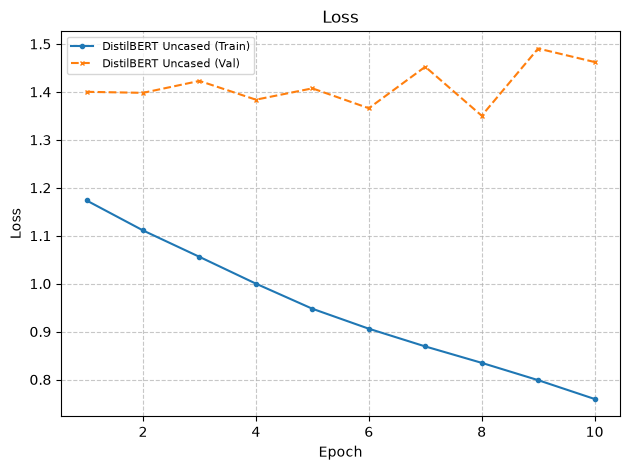

In [48]:
from transformers import AutoModelForSequenceClassification

# Use the pretrained DistilBERT uncased model.
torch.manual_seed(67)
distilbert = AutoModelForSequenceClassification.from_pretrained(
    'distilbert-base-uncased',
    num_labels=len(LABELS),
    problem_type="multi_label_classification",
    token=False
).to(device)

for param in distilbert.distilbert.parameters():
    param.requires_grad = False

trainable = sum(p.numel() for p in distilbert.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in distilbert.parameters())
print(f'Step 1: Linear Probing')
print(f'  Trainable: {trainable:,} / {total_params:,} ({trainable/total_params*100:.2f}%)')

optimizer = optim.Adam(filter(lambda p: p.requires_grad, distilbert.parameters()), lr=5e-4)
criterion = nn.BCEWithLogitsLoss(pos_weight=task1_clamped_weights)

DistilBERT_Results = {}
DistilBERT_Results['DistilBERT Uncased'] = run_experiment(
    distilbert, optimizer, criterion, task1_hf_train_loader, task1_hf_val_loader,
    epochs=10, name='DistilBERT Uncased', tokenizer_mode=True, load_best_model=False
)

plot_experiments(DistilBERT_Results)

### Evaluating the Model:

This model easily outperforms the previous models. It has a much higher accuracy score over all previous models, an substantial increase in macro and weighted precisions while maintaining almost equal recall scores, resulting in higher macro and weighted f1 scores. The confusion matrices also show a much lower count of false positives, while maintaining a good number of true positives. 

C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\4058164983.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  'labels': torch.tensor(self.labels[idx], dtype=torch.float).to(device),
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{met

                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.2000      0.5714      0.2963           7      0.9050
Appeal to fear/preju         0.0909      0.5000      0.1538          10      0.7250
Black-and-white Fall         0.1064      0.7143      0.1852           7      0.7800
Causal Oversimplific         0.0385      0.3333      0.0690           3      0.8650
Doubt                        0.5000      0.3929      0.4400          28      0.8600
Exaggeration/Minimis         0.2045      0.4737      0.2857          19      0.7750
Flag-waving                  0.1389      0.8333      0.2381           6      0.8400
Glittering generalit         0.1064      0.4545      0.1724          11      0.7600
Loaded Language              0.7051      0.5500      0.6180         100      0.6600
Misrepresentation of         0.0270      1.0000      0.0526           1      0.8200
Name calling/Labelin         0.3585      0.3585      0.3585          53     

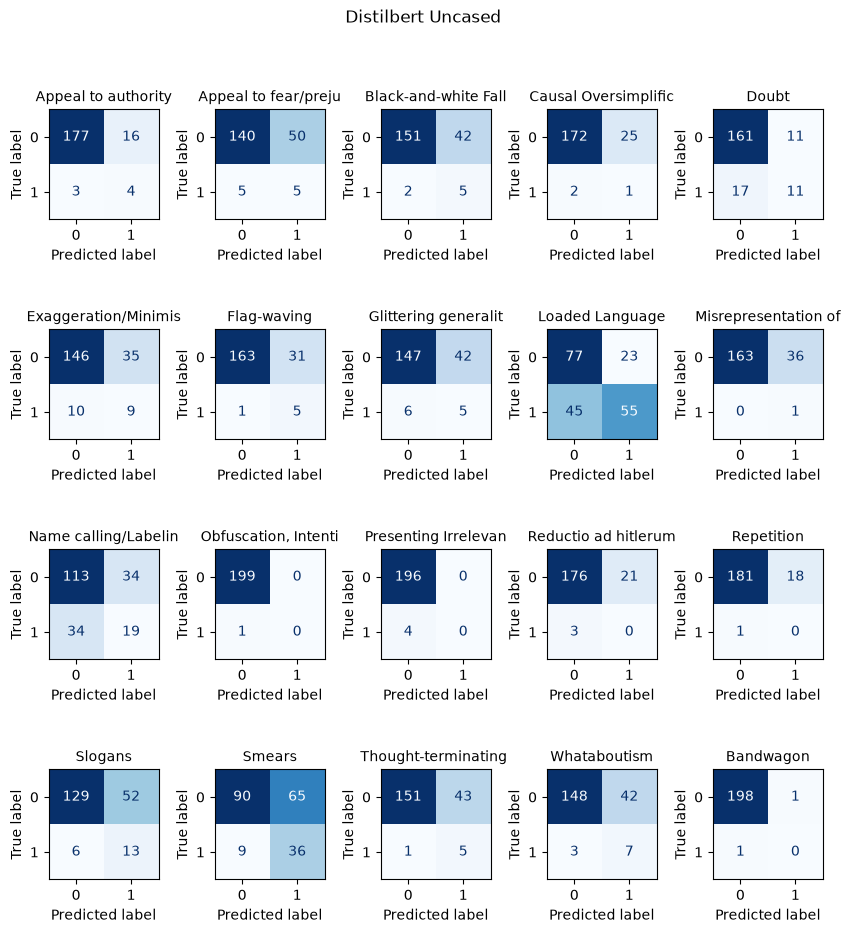

In [49]:
fig, report, accuracy = get_evaluation(distilbert, task1_hf_test_loader, "Distilbert Uncased", True)

view_report(report)
print(f"Total Accuracy: {accuracy}")

### Experiment 6: Distilbert Cased (REJECTED)

One of the things I noticed within the data is the major use of capitalization in order to vent frustration. "THERE ARE ONLY TWO GENDERS" for example is different to "there are only two genders" as the capitalization enhances the emotion of the text. Since we've only used the uncased tokenizer and transformer so far, I thought using a cased model might allow the model to learn based on these patterns. 

In [50]:
# Create a new tokenizer and dataset using the cased tokenizer.
cased_tokenizer = AutoTokenizer.from_pretrained('distilbert-base-cased')

task1_hf_cased_train = HFDataset(train_set_task1["text"].to_list(), 
                           train_set_task1["label_encoded"], 
                           cased_tokenizer,
                           MAX_LEN)
task1_hf_cased_val = HFDataset(dev_set_task1["text"].to_list(), 
                           dev_set_task1["label_encoded"], 
                           cased_tokenizer,
                           MAX_LEN)
task1_hf_cased_test = HFDataset(test_set_task1["text"].to_list(), 
                           test_set_task1["label_encoded"], 
                           cased_tokenizer,
                           MAX_LEN)

task1_hf_cased_train_loader = DataLoader(task1_hf_cased_train, batch_size=32, shuffle=True, generator=generator)
task1_hf_cased_test_loader = DataLoader(task1_hf_cased_test, batch_size=64, shuffle=False, generator=generator)
task1_hf_cased_val_loader = DataLoader(task1_hf_cased_val, batch_size=64, shuffle=False, generator=generator)

### Training the Model:

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1807.48it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\4058164983.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.de

Step 1: Linear Probing
  Trainable: 605,972 / 65,796,884 (0.92%)
  [DistilBERT CASED] Epoch 1/10 — Train: 1.1978 | Val: 1.4434
  [DistilBERT CASED] Epoch 2/10 — Train: 1.1546 | Val: 1.4092
  [DistilBERT CASED] Epoch 4/10 — Train: 1.1299 | Val: 1.4130
  [DistilBERT CASED] Epoch 6/10 — Train: 1.1083 | Val: 1.3969
  [DistilBERT CASED] Epoch 8/10 — Train: 1.0740 | Val: 1.4706
  [DistilBERT CASED] Epoch 10/10 — Train: 1.0394 | Val: 1.4417


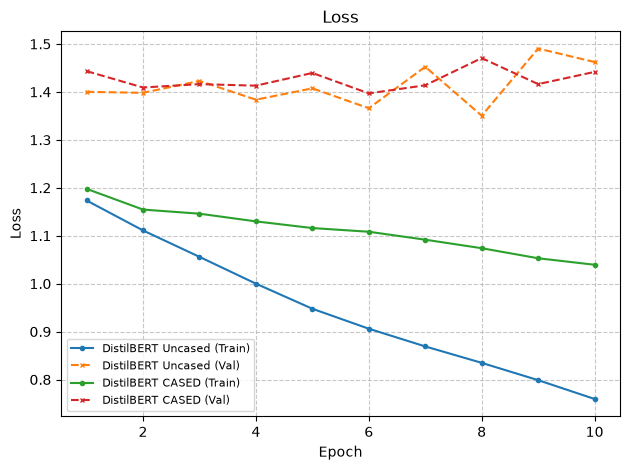

In [51]:
from transformers import AutoModelForSequenceClassification

torch.manual_seed(67)
distilbert_cased = AutoModelForSequenceClassification.from_pretrained(
    'distilbert-base-cased',
    num_labels=len(LABELS),
    problem_type="multi_label_classification",
    token=False
).to(device)

for param in distilbert_cased.distilbert.parameters():
    param.requires_grad = False

trainable = sum(p.numel() for p in distilbert_cased.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in distilbert_cased.parameters())
print(f'Step 1: Linear Probing')
print(f'  Trainable: {trainable:,} / {total_params:,} ({trainable/total_params*100:.2f}%)')

optimizer = optim.Adam(filter(lambda p: p.requires_grad, distilbert_cased.parameters()), lr=5e-4)
criterion = nn.BCEWithLogitsLoss(pos_weight=task1_clamped_weights)

DistilBERT_Results['DistilBERT CASED'] = run_experiment(
    distilbert_cased, optimizer, criterion, task1_hf_cased_train_loader, task1_hf_cased_val_loader,
    epochs=10, name='DistilBERT CASED', tokenizer_mode=True, load_best_model=False
)

plot_experiments(DistilBERT_Results)

### Evaluating the Model:

The model's overall evaluation metrics all underperform when compared to DistilBERT Uncased, with much lower precision, recall, f1-scores as well as overall accuracy. The only metric which somewhat improved is weighted recall. Looking at the confusion matrices, however, we can see that this is a result of an increase in Loaded Language's per label metrics. It has a drastic increase in recall but a lower precision, which raises its f1-score. This may be attributed to the fact that Loaded Language would be the most common technique that utilizes capitalized data, and having that distinction would help specifically it the most. However, at a cost of all other labels suffering, I decide to reject this proposition.

C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\4058164983.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  'labels': torch.tensor(self.labels[idx], dtype=torch.float).to(device),
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{met

                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.0484      0.4286      0.0870           7      0.6850
Appeal to fear/preju         0.0538      0.5000      0.0971          10      0.5350
Black-and-white Fall         0.0588      1.0000      0.1111           7      0.4400
Causal Oversimplific         0.0194      1.0000      0.0380           3      0.2400
Doubt                        0.2432      0.6429      0.3529          28      0.6700
Exaggeration/Minimis         0.1284      0.7368      0.2188          19      0.5000
Flag-waving                  0.0312      0.5000      0.0588           6      0.5200
Glittering generalit         0.0758      0.9091      0.1399          11      0.3850
Loaded Language              0.5714      0.8400      0.6802         100      0.6050
Misrepresentation of         0.0120      1.0000      0.0238           1      0.5900
Name calling/Labelin         0.2866      0.8868      0.4332          53     

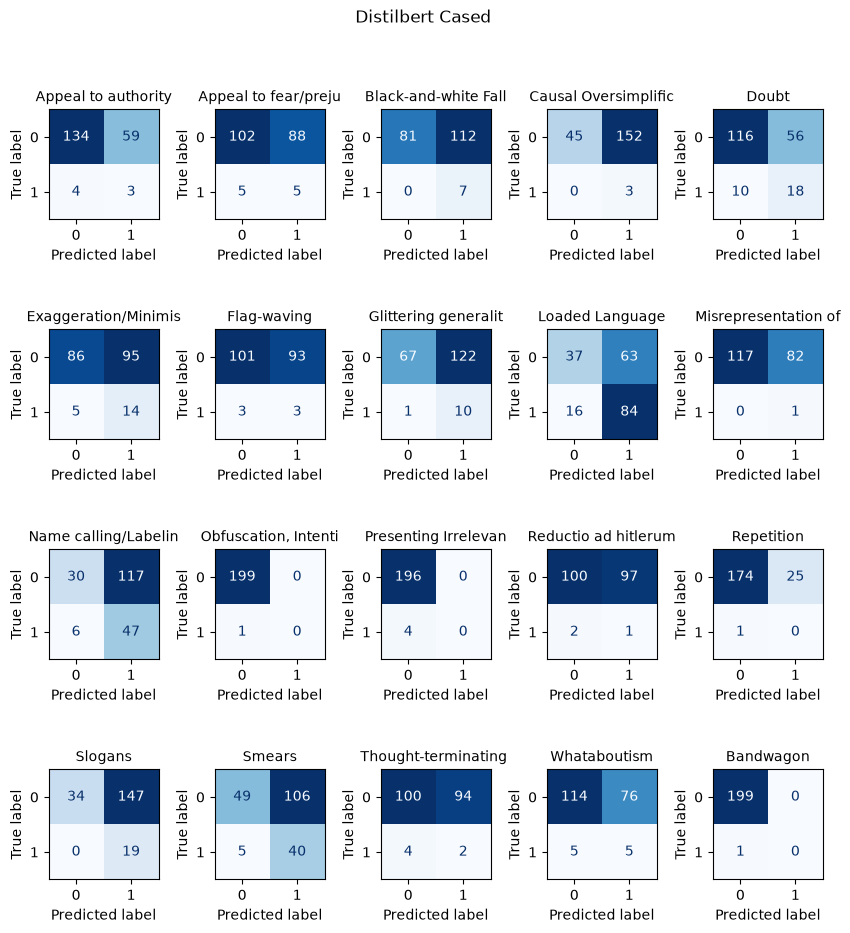

In [52]:
fig, report, accuracy = get_evaluation(distilbert_cased, task1_hf_cased_test_loader, "Distilbert Cased", True)

view_report(report)
print(f"Total Accuracy: {accuracy}")

### Experiment 7: LoRA

For my next experiment, I want to experiment with fine tuning the model using LoRA. LoRA is an adapter which we can add to our model to add a learned low rank update which is added to the model's existing frozen weights. The capacity of this low rank update is determined by the rank hyperparameter, where the higher r results in higher capacity. By updating the weights this way rather than updating all of the model's weights, it allows for model fine tuning without touching any of its initial weights, allowing us to save lots of computing costs while retaining most of fine-tuning's benefits.

I first run a test using the previous distilbert-uncased example to see which value for r will perform best for our task.

### Evaluating the Models:

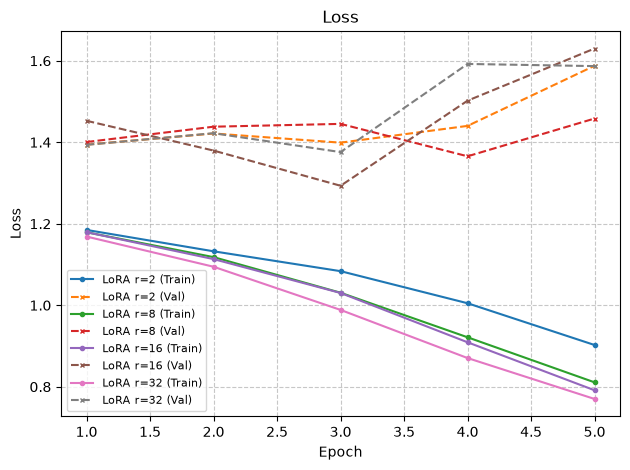

In [53]:

# How does the rank (r) affect performance?
lora_rank_results = {}
lora_rank_metrics = {}

for r in [2, 8, 16, 32]:
    print(f'\n--- LoRA r={r} ---')
    torch.manual_seed(67)
    base = AutoModelForSequenceClassification.from_pretrained(
        'distilbert-base-uncased', num_labels=len(LABELS), token=False
    ).to(device)
    
    config = LoraConfig(
        task_type=TaskType.SEQ_CLS, r=r, lora_alpha=r*2,
        lora_dropout=0.1, target_modules=['q_lin', 'v_lin'],
    )
    peft_model = get_peft_model(base, config)
    peft_model.print_trainable_parameters()
    
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, peft_model.parameters()),
                            lr=5e-4, weight_decay=0.01)
    criterion = nn.BCEWithLogitsLoss(pos_weight=task1_clamped_weights)
    
    lora_rank_results[f'LoRA r={r}'] = run_experiment(
        peft_model, optimizer, criterion, task1_hf_train_loader, task1_hf_val_loader,
        epochs=5, name=f'LoRA r={r}', tokenizer_mode=True, load_best_model=False
    )
    
    fig, report, accuracy = get_evaluation(peft_model, task1_hf_val_loader, f"Lora Model (r={r})", tokenizer_mode=True)
    lora_rank_metrics[f'LoRA r={r}'] = {"fig" : fig, "report" : report, "accuracy" : accuracy}
    plt.close(fig)
    clear_output(True)
    
plot_experiments(lora_rank_results)

                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.2000      1.0000      0.3333           2      0.8730
Appeal to fear/preju         0.3333      0.5000      0.4000           4      0.9048
Black-and-white Fall         0.0000      0.0000      0.0000           0      0.9048
Causal Oversimplific         0.0000      0.0000      0.0000           1      0.5714
Doubt                        0.1739      1.0000      0.2963           8      0.3968
Exaggeration/Minimis         0.1176      0.2857      0.1667           7      0.6825
Flag-waving                  0.2500      0.2000      0.2222           5      0.8889
Glittering generalit         0.1000      1.0000      0.1818           1      0.8571
Loaded Language              0.8889      0.2581      0.4000          31      0.6190
Misrepresentation of         0.1250      0.6667      0.2105           3      0.7619
Name calling/Labelin         0.5556      0.1724      0.2632          29     

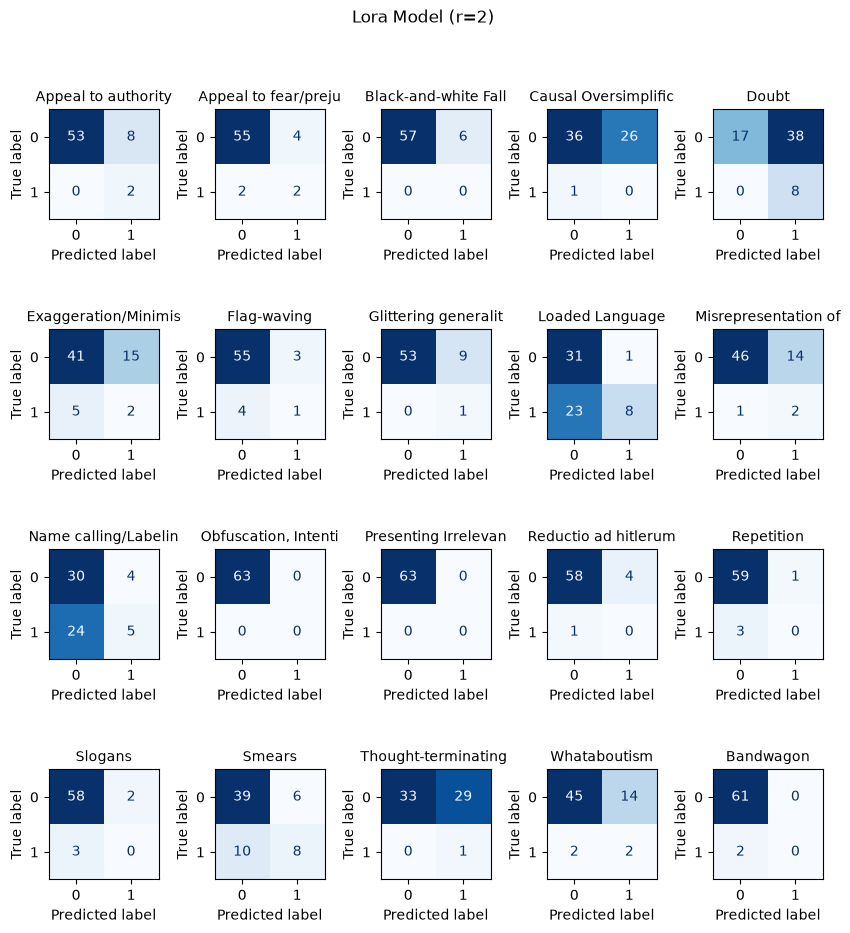

In [54]:
fig = lora_rank_metrics["LoRA r=2"]["fig"]
report = lora_rank_metrics["LoRA r=2"]["report"]
acc = lora_rank_metrics["LoRA r=2"]["accuracy"]

view_report(report)
print(f"Total Accuracy: {acc}")

display(fig)

                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.1000      1.0000      0.1818           2      0.7143
Appeal to fear/preju         0.1579      0.7500      0.2609           4      0.7302
Black-and-white Fall         0.0000      0.0000      0.0000           0      0.7460
Causal Oversimplific         0.0000      0.0000      0.0000           1      0.6032
Doubt                        0.1250      0.5000      0.2000           8      0.4921
Exaggeration/Minimis         0.1176      0.2857      0.1667           7      0.6825
Flag-waving                  0.2500      0.8000      0.3810           5      0.7937
Glittering generalit         0.0500      1.0000      0.0952           1      0.6984
Loaded Language              0.7222      0.8387      0.7761          31      0.7619
Misrepresentation of         0.1364      1.0000      0.2400           3      0.6984
Name calling/Labelin         0.5952      0.8621      0.7042          29     

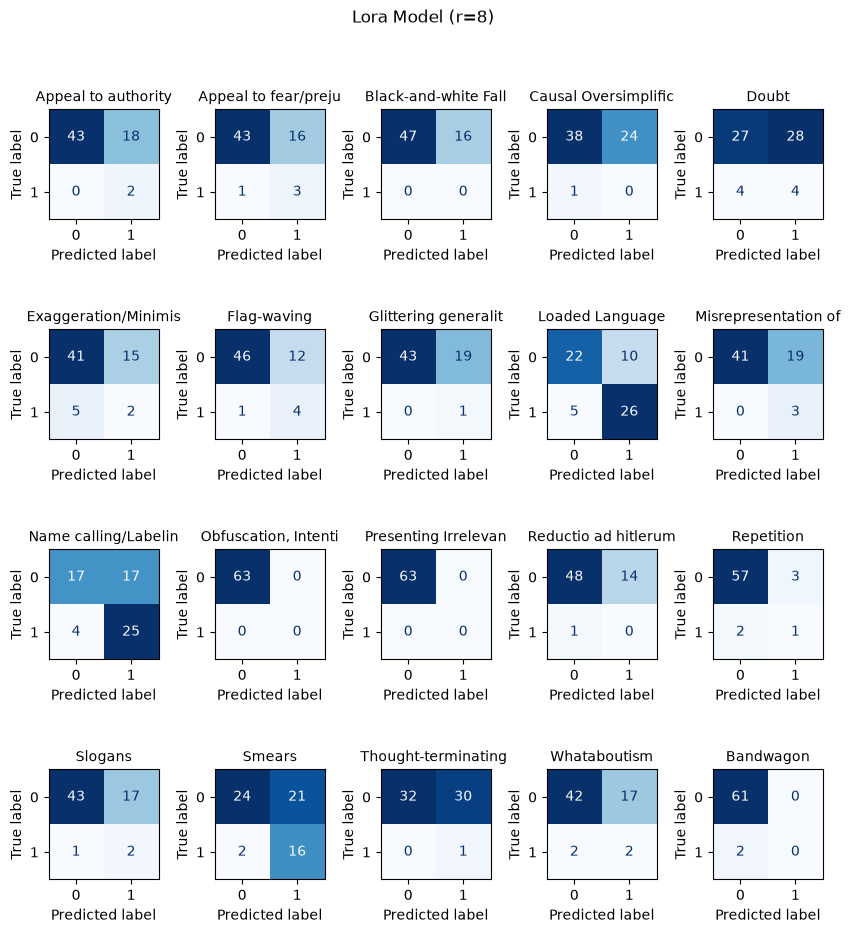

In [55]:
fig = lora_rank_metrics["LoRA r=8"]["fig"]
report = lora_rank_metrics["LoRA r=8"]["report"]
acc = lora_rank_metrics["LoRA r=8"]["accuracy"]

view_report(report)
print(f"Total Accuracy: {acc}")

display(fig)

                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.1250      1.0000      0.2222           2      0.7778
Appeal to fear/preju         0.1364      0.7500      0.2308           4      0.6825
Black-and-white Fall         0.0000      0.0000      0.0000           0      0.8413
Causal Oversimplific         0.0000      0.0000      0.0000           1      0.8095
Doubt                        0.0870      0.2500      0.1290           8      0.5714
Exaggeration/Minimis         0.1379      0.5714      0.2222           7      0.5556
Flag-waving                  0.2353      0.8000      0.3636           5      0.7778
Glittering generalit         0.0526      1.0000      0.1000           1      0.7143
Loaded Language              0.7353      0.8065      0.7692          31      0.7619
Misrepresentation of         0.1818      0.6667      0.2857           3      0.8413
Name calling/Labelin         0.6190      0.8966      0.7324          29     

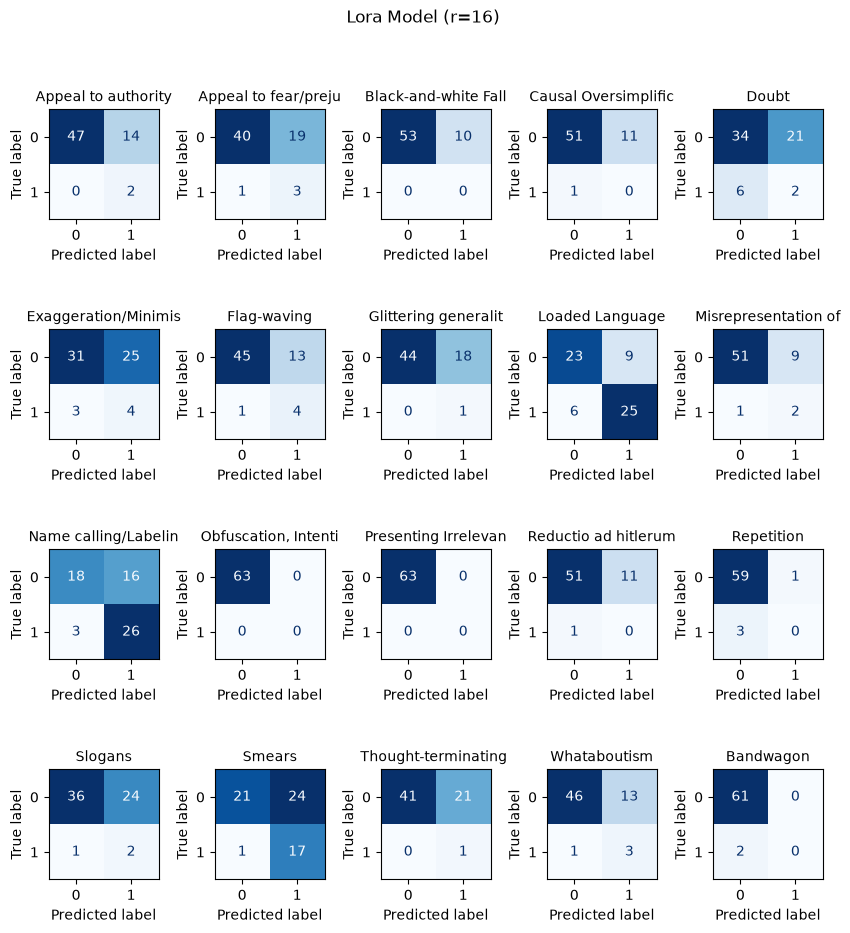

In [56]:
fig = lora_rank_metrics["LoRA r=16"]["fig"]
report = lora_rank_metrics["LoRA r=16"]["report"]
acc = lora_rank_metrics["LoRA r=16"]["accuracy"]

view_report(report)
print(f"Total Accuracy: {acc}")

display(fig)

                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.2000      0.5000      0.2857           2      0.9206
Appeal to fear/preju         0.2500      0.7500      0.3750           4      0.8413
Black-and-white Fall         0.0000      0.0000      0.0000           0      0.8730
Causal Oversimplific         0.0000      0.0000      0.0000           1      0.6508
Doubt                        0.0909      0.2500      0.1333           8      0.5873
Exaggeration/Minimis         0.1667      0.2857      0.2105           7      0.7619
Flag-waving                  0.2727      0.6000      0.3750           5      0.8413
Glittering generalit         0.0667      1.0000      0.1250           1      0.7778
Loaded Language              0.7568      0.9032      0.8235          31      0.8095
Misrepresentation of         0.1538      0.6667      0.2500           3      0.8095
Name calling/Labelin         0.5833      0.7241      0.6462          29     

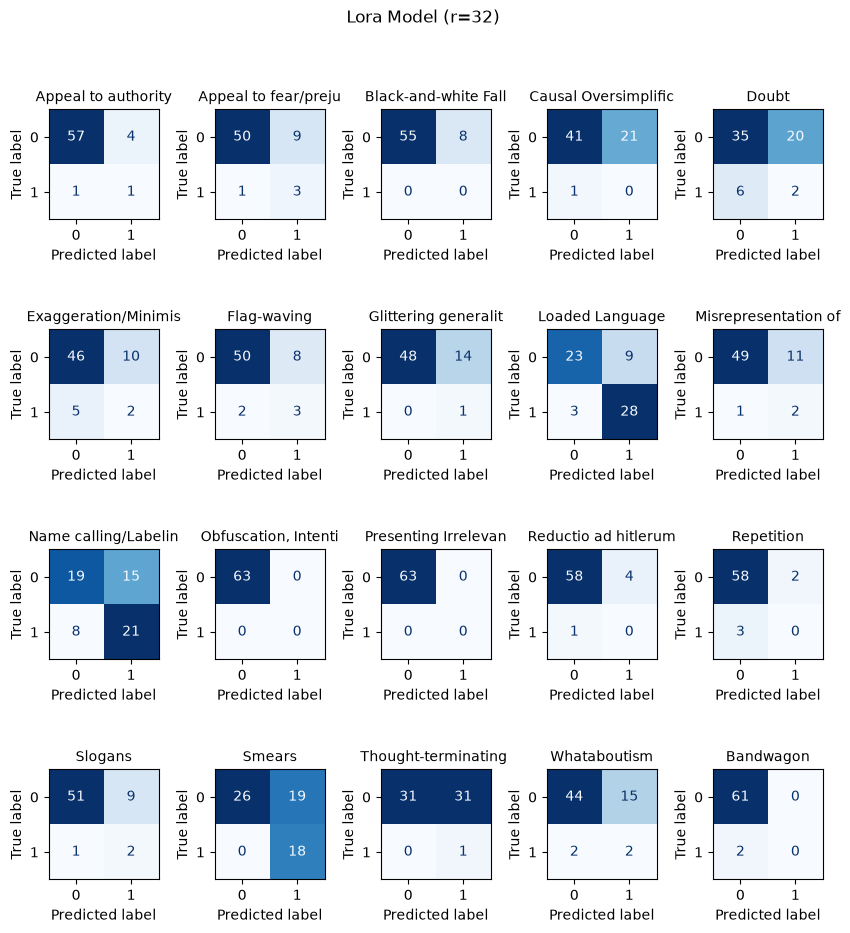

In [57]:
fig = lora_rank_metrics["LoRA r=32"]["fig"]
report = lora_rank_metrics["LoRA r=32"]["report"]
acc = lora_rank_metrics["LoRA r=32"]["accuracy"]

view_report(report)
print(f"Total Accuracy: {acc}")

display(fig)

### Evaluating R:

For ranks r=2 and r=8 there is not much difference between their evaluation metrics. Rank 8 has slightly better macro precision but slightly worse macro recall but their overall macro and weighted f1 scores, as well as total model accuracy are around the same level. Nothing too much of interest appears when looking at their confusion matrices, there seems to be significantly better results within the labels Name Calling, Smears, Exaggeration for rank 8 over rank 2 for per label accuracy and precision. But Rank 2 seems to have better results for the labels Causal Oversimplifcation and Doubt, with better accuracies and precision.

At r=16 we see that the model performs worse than the r=8 model in every metric, except for total model accuracy which has increased from 0.748 to 0.808. Looking at the confusion matrices we can attribute this to the fact that the model seems to predict negative samples much more often than it did in r=8, leading to overall much worse recall which has decreased from macro 0.526 to 0.467 and weighted 0.691 to 0.634. In every single label, the number of true positives (or even positive labelled) have all decreased, this is somewhat similar to maintaining the same model but increasing the probability threshold, although one performance metric has increased, it does not indicate that there is actual learning.

At r=32 the model improves from the r=16 model and has somewhat similar performance to r=8 which was our previous best model. It only has minor decreases from precision, recall, f1 and total accuracy, but are still within a very reasonable margin. Interestingly, weighted recall has actually increased from 0.691 to 0.756. Three labels have notable increases in recall from r=8: Smears and Name Calling (which has the biggest increase of 0.586 to 0.828). Within other labels, recall seems to be at an equal level, with some slight increases or slight decreases. I also notice that unlike r=16's performance, r=32 seems to show evidence of actual learning to the problem, as there are signs within the confusion matrices that the tradeoff between labelling positive / negative happen because of the way the model actually encodes / interprets the text. For example, one of the things I mentioned for r=16 is that the increase in accuracy only happens because the model seems to JUST predict negative samples more often, similar to increasing the probability thresholds of the same model which does not seem to be the case in r=32.

Overall, I decide to choose r=32 as my final rank parameter. Despite r=8's marginal better overall metrics, r=32 seems to be better for our task overall, with an increased weighted recall which is what I wanted to prioritize for the model.

## Final Model

I will be using the Distilbert-uncased model with a LoRA adapter with rank = 32 for my final model for this task. I will also tune the probability thresholds to further improve its capabilities.

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 2268.04it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\4058164983.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.

  [LoRA r=32] Epoch 1/5 — Train: 1.1840 | Val: 1.4140
  [LoRA r=32] Epoch 2/5 — Train: 1.1072 | Val: 1.3843
  [LoRA r=32] Epoch 3/5 — Train: 1.0034 | Val: 1.3734
  [LoRA r=32] Epoch 4/5 — Train: 0.8720 | Val: 1.3451
  [LoRA r=32] Epoch 5/5 — Train: 0.7615 | Val: 1.7588


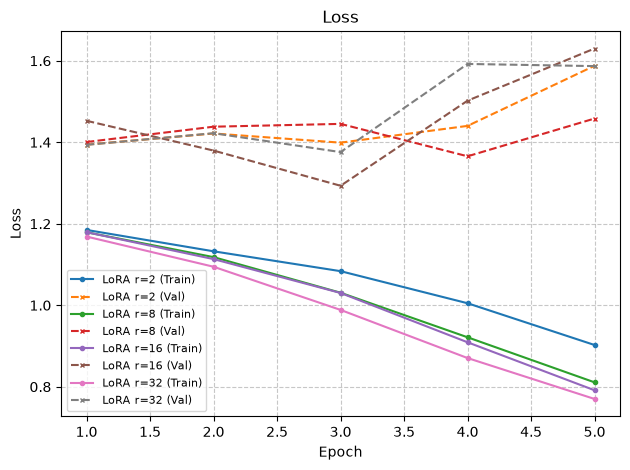

In [58]:
torch.manual_seed(67)
base = AutoModelForSequenceClassification.from_pretrained(
    'distilbert-base-uncased', num_labels=len(LABELS), token=False
).to(device)

config = LoraConfig(
    task_type=TaskType.SEQ_CLS, r=32, lora_alpha=r*2,
    lora_dropout=0.1, target_modules=['q_lin', 'v_lin'],
)
final_task1_model = get_peft_model(base, config)

optimizer = optim.Adam(filter(lambda p: p.requires_grad, final_task1_model.parameters()),
                        lr=5e-4, weight_decay=0.01)
criterion = nn.BCEWithLogitsLoss(pos_weight=task1_clamped_weights)

run_experiment(
    final_task1_model, optimizer, criterion, task1_hf_train_loader, task1_hf_val_loader,
    epochs=5, name=f'LoRA r={r}', tokenizer_mode=True, load_best_model=False
)

plot_experiments(lora_rank_results)

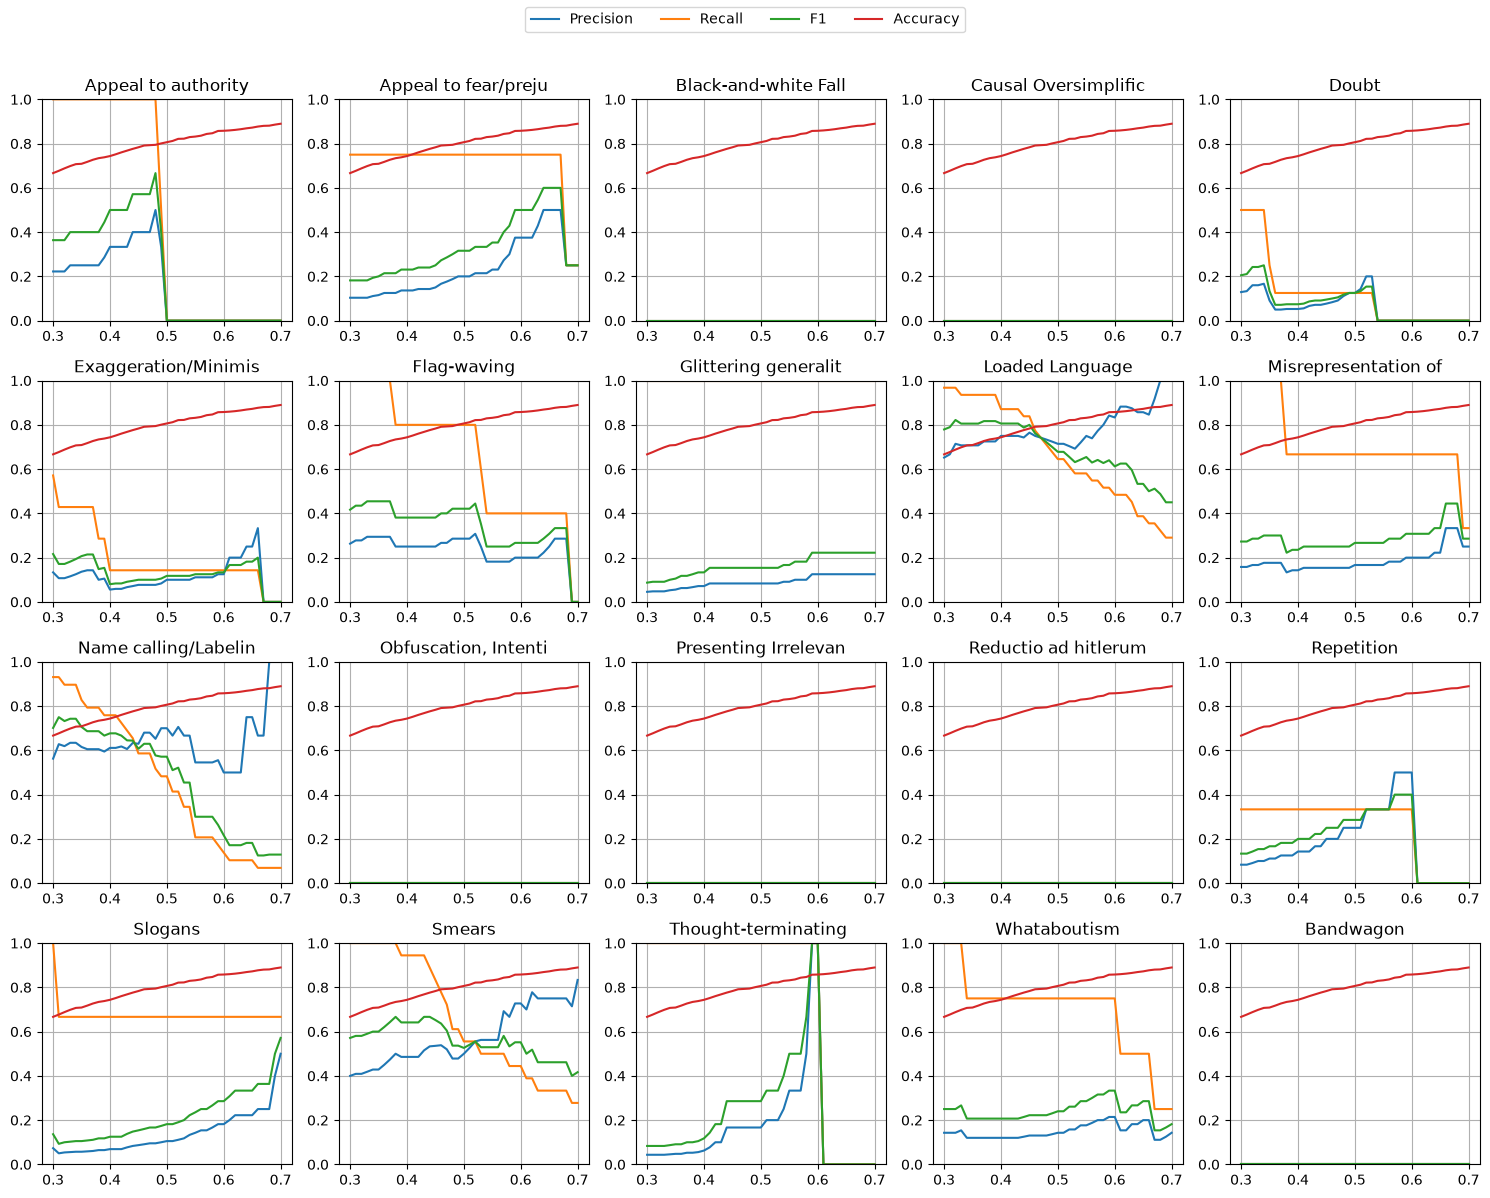

In [59]:
fig, ax = plt.subplots(4, 5, figsize=(15, 12))

for i, label in enumerate(LABELS):
    thresholds, precisions, recalls, f1_scores, accuracies = threshold_testing(label, final_task1_model, task1_hf_val_loader, True)
    clear_output(True)

    current_ax = ax[i // 5, i % 5]

    current_ax.plot(thresholds, precisions, label="Precision")
    current_ax.plot(thresholds, recalls, label="Recall")
    current_ax.plot(thresholds, f1_scores, label="F1")
    current_ax.plot(thresholds, accuracies, label="Accuracy")

    current_ax.set_title(label[:20])
    current_ax.set_ylim(0, 1)
    current_ax.grid()
    
# Legends
handles, labels = ax[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [60]:
THRESHOLDS = [0.5 for i in range(len(LABELS))]

THRESHOLDS[LABELS.index("Appeal to fear/prejudice")] = 0.6
THRESHOLDS[LABELS.index("Exaggeration/Minimisation")] = 0.4
THRESHOLDS[LABELS.index("Loaded Language")] = 0.4
THRESHOLDS[LABELS.index("Smears")] = 0.4

TRESHOLDS = torch.tensor(THRESHOLDS).to(device) 

### Evaluating Final Model:

As a naive estimate from creating the evaluation metric, I had set estimated goals for:
1. Macro Recall: ~0.5
2. Weighted Recall: ~0.65
3. Macro F1: ~0.5
4. Weighted F1: ~0.5

For our final model we have:
1. Macro Recall: ~0.45
2. Weighted Recall: ~0.56
3. Macro F1: ~0.23
4. Weighted F1: ~0.45

We have slightly undershot on most of our metrics, particularly macro recall, weighted recall and weighted f1. Macro Recall and Weighted F1 is close enough to our naive benchmark that it is not too much of a concer, however, a low weighted recall of 0.564 vs the weighted recall of ~0.65, a near 10% difference is a point of concern. The biggest concern, however, is the macro f1 of 0.225, which is 25% point difference from our target macro F1. 

However, given our exact task, I believe that these are fine. Because our dataset has a much larger amount of values for negative samples over negative samples, creating a model which can adequately seperate positive samples for a technique from negative samples for a technique will always be difficult because a model, given that it knows most of the data will be negative samples, will always try to overfit to labelling all samples as negative. This is why I put a focus on recall as the primary evaluation metric. Because a "good" model for us will be one that can correctly label most positive samples as being true positive. Precision was always bound to severely lack in this case, because in an effort to try to increase recall, we end up having many false positives. 

But a false positive in this task, where techniques are just arbitrary labels that are up to the interpretation of a reader, is different from a false positive in a task where the labels are measured and true. For example, an example of a false positive for this sample will be for a meme "This text contains technique X", we predict that it uses technique Y. Although it may not be part of the ground truth, the validity of the claim that "this meme uses technique Y" is up to interpretation of the users and may or may not be true. This is different from a task such as for example, detection of a dog in an image. Where there is a real ground truth of "the dog is either in the image or not". 

My naive benchmarks for the model did not truly understand both of these concepts. Although I tried accounting for it by setting a decently low F1 (0.5 which given our target recall, could be achievable with a macro precision of 0.4). The extremities of both the data, and the task makes both of those tasks extremely difficult to achieve in practice. 

The final model that we do have, is a model that we have determined to have adequately learned the patterns which classify a meme as using some technique, correctly predicts ~half of the true positive samples as being positive for that sample, while still maintaining that about 1 in every 5 positive prediction, is truly positive, which we could interpret as the other 4/5 being up to interpretation. As the end goal for this model is to create a teaching aid, rather than a strict "This meme uses this specific technique", I would say that these metrics are an acceptable final model for this task.  

C:\Users\Bop\AppData\Local\Temp\ipykernel_34108\4058164983.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  'labels': torch.tensor(self.labels[idx], dtype=torch.float).to(device),
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{met

                          precision      recall    f1-score     support    accuracy
Appeal to authority          0.4286      0.4286      0.4286           7      0.9600
Appeal to fear/preju         0.1481      0.4000      0.2162          10      0.8550
Black-and-white Fall         0.0805      1.0000      0.1489           7      0.6000
Causal Oversimplific         0.0250      0.3333      0.0465           3      0.7950
Doubt                        0.4412      0.5357      0.4839          28      0.8400
Exaggeration/Minimis         0.2083      0.5263      0.2985          19      0.7650
Flag-waving                  0.1333      0.6667      0.2222           6      0.8600
Glittering generalit         0.1481      0.3636      0.2105          11      0.8500
Loaded Language              0.6939      0.6800      0.6869         100      0.6900
Misrepresentation of         0.0345      1.0000      0.0667           1      0.8600
Name calling/Labelin         0.4167      0.3774      0.3960          53     

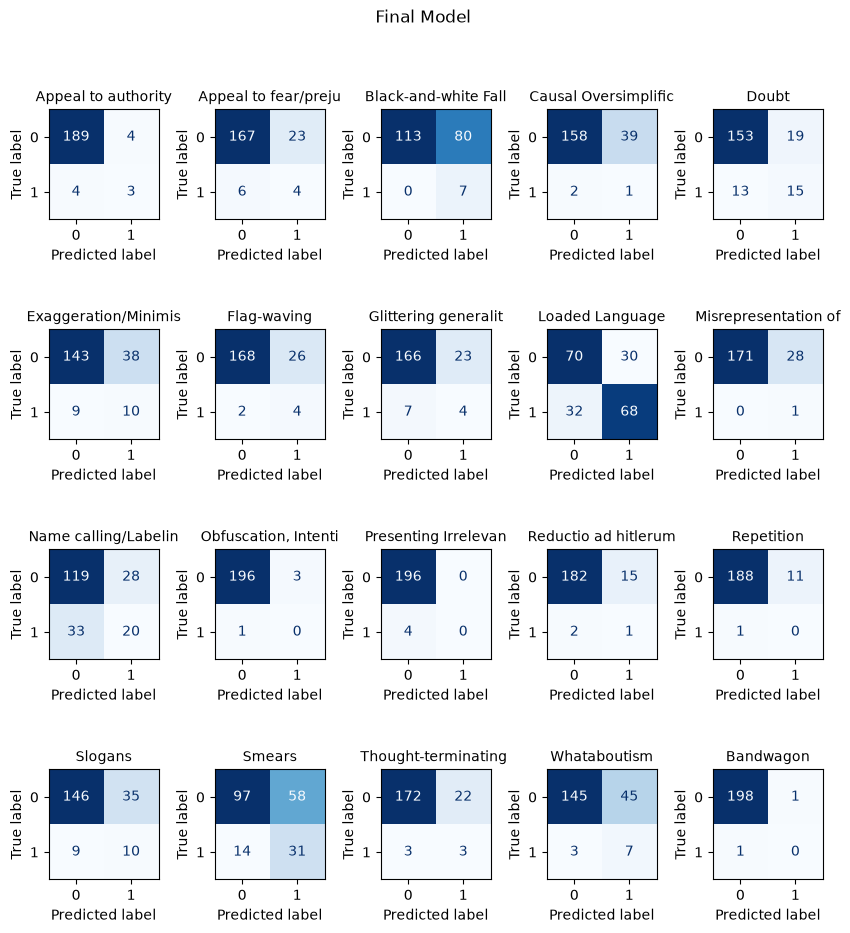

In [61]:
fig, report, accuracy = get_evaluation(final_task1_model, task1_hf_test_loader, "Final Model", tokenizer_mode=True, prob_thresholds=THRESHOLDS)
view_report(report)
print(f"Total Accuracy: {accuracy}")

# Task 2

For Task 2, we would like to go one step further by classifying the span of text which is responsible for the flagged technique. I plan to accomplish this by creating a new classifier model which will take in inputs: technique used and text. Then output the span labels. The technique labelling will come using the model that I have made from Task 1.  

## Plan:

I intend to solve this task by creating a new "span classification" model for Task 2 which will act as a classifier head that takes an input from Task 1 in order to do its calculations.

## The Data:

We can view the way that our dataset handles the data. For each meme it stores a list of dictionaries instead of a simple label from Task 1. Within each dictionary it contains the technique that was used, the starting character position in the string and a ending character position which indicates the span of text that flagged the technique. 

What's important to see is that one meme can contain duplicate techniques. In the meme: 

"SO BERNIE BROS HAVEN'T COMMITTED VIOLENCE EH?
POWER COMES FROM THE BARREL OF A GUN, COMRADES.
WHAT ABOUT THE ONE WHO SHOT CONGRESSMAN SCALISE OR THE DAYTON OHIO MASS SHOOTER?"

Three seperate spans of texts all pointed to Loaded Language, with "Violence", "MASS SHOOTER" and "COMRADES".

In [62]:
# Check a sample of how the data structures a span
train_set_task2["labels"].iloc[0]

[{'start': 0,
  'end': 41,
  'technique': 'Black-and-white Fallacy/Dictatorship',
  'text_fragment': 'THERE ARE ONLY TWO GENDERS\n\nFEMALE \n\nMALE'}]

In [63]:
# Check to see if within one meme, there can be multiple spans that point to the same technique. 
duplicates = []
duplicate_text = []
for text, annotation in zip(train_set_task2["text"], train_set_task2["labels"]):
    techniques_used = [label["technique"] for label in annotation]
    if len(techniques_used) != len(set(techniques_used)):
        duplicates.append(annotation)
        duplicate_text.append(text)

print(duplicates[0])
print(duplicate_text[0])

[{'end': 83, 'start': 47, 'technique': 'Slogans', 'text_fragment': 'POWER COMES FROM THE BARREL OF A GUN'}, {'end': 14, 'start': 3, 'technique': 'Name calling/Labeling', 'text_fragment': 'BERNIE BROS'}, {'end': 41, 'start': 33, 'technique': 'Loaded Language', 'text_fragment': 'VIOLENCE'}, {'end': 175, 'start': 163, 'technique': 'Loaded Language', 'text_fragment': 'MASS SHOOTER'}, {'end': 93, 'start': 85, 'technique': 'Loaded Language', 'text_fragment': 'COMRADES'}, {'end': 176, 'start': 0, 'technique': 'Smears', 'text_fragment': "SO BERNIE BROS HAVEN'T COMMITTED VIOLENCE EH?\n\nPOWER COMES FROM THE BARREL OF A GUN, COMRADES.\n\nWHAT ABOUT THE ONE WHO SHOT CONGRESSMAN SCALISE OR THE DAYTON OHIO MASS SHOOTER?"}]
SO BERNIE BROS HAVEN'T COMMITTED VIOLENCE EH?

POWER COMES FROM THE BARREL OF A GUN, COMRADES.

WHAT ABOUT THE ONE WHO SHOT CONGRESSMAN SCALISE OR THE DAYTON OHIO MASS SHOOTER?



## Preparations

To prepare for Task 2, I need to modify some training / evaluation fucntions and create the dataset object.

In [64]:
class Task2Dataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.span_labels = [] # Contains a tensor of shape (max_len, 20) which represents the technique used present in each token.
        self.technique_labels = [] # Acts as self.labels from Task 1. Contains all techniques used in the meme
        self.offset_mappings = [] # Used to keep offset mapping from tokenizer so we can map the indices to tokens for classification later.
        self.texts = texts
        self.text_fragments = [] # Contains the span of text that flags a technique
        self.encodings = []
        self.lengths = []

        for text, annotations in zip(texts, labels):
            encodings = tokenizer(
                        text,
                        padding='max_length',
                        truncation=True,
                        max_length=max_len,
                        return_offsets_mapping=True
                    )
            
            offsets = encodings["offset_mapping"]
            span_targets = torch.zeros((max_len, len(LABELS)), dtype=torch.float)
            
            technique_targets = torch.zeros(len(LABELS), dtype=torch.float)
            
            fragments = []
            
            for annotation in annotations:
                label_idx = LABELS.index(annotation["technique"])
                char_start = annotation["start"]
                char_end = annotation["end"]
                
                technique_targets[label_idx] = 1.0
                fragments.append(annotation["text_fragment"])
                
                # Using the start and end keys in each span, set the value of 
                # meme[start:end][technique] = 1 in its span vector.
                for token_idx, (token_start, token_end) in enumerate(offsets):
                    if token_end > char_start and token_start < char_end:
                        span_targets[token_idx, label_idx] = 1.0
            
            # Span labels are of shape (max_len, num_labels)
            self.span_labels.append(span_targets)
            self.technique_labels.append(technique_targets)
            self.offset_mappings.append(offsets)
            self.text_fragments.append(fragments)
            self.encodings.append(encodings)
            self.lengths.append(sum(encodings["attention_mask"]) - 2)
            
    def __len__(self):
        return len(self.encodings)
    
    def __getitem__(self, idx):
        return {
            'input_ids': torch.tensor(self.encodings[idx]['input_ids'], dtype=torch.long),
            'attention_mask': torch.tensor(self.encodings[idx]['attention_mask'], dtype=torch.long),
            'spans': self.span_labels[idx],
            'labels': self.technique_labels[idx],
            'text': self.texts[idx],
            'index':idx,
            'lengths': self.lengths[idx]
        }

In [65]:
task2_train_ds = Task2Dataset(train_set_task2["text"], train_set_task2["labels"], tokenizer)
task2_val_ds = Task2Dataset(dev_set_task2["text"], dev_set_task2["labels"], tokenizer)
task2_test_ds = Task2Dataset(test_set_task2["text"], test_set_task2["labels"], tokenizer)

task2_train_loader = DataLoader(task2_train_ds, batch_size=128, shuffle=True, generator=generator)
task2_val_loader = DataLoader(task2_val_ds, batch_size=256, shuffle=False, generator=generator)
task2_test_loader = DataLoader(task2_test_ds, batch_size=256, shuffle=False, generator=generator)

I also want to study the distribution of span lengths in the data. It seems that most of the data has quite short spans for each label. With most having ~5 tokens in length. However, there are many outliers with span lengths up to ~80. Inspecting the training data itself, it seems like some of the spans just cover the entire meme, which is where these long spans come from. 

This might be a problem given our task 1 model uses a max length of 64. What might happen is that if a meme has a span beyond the 64th position, e.g starts from 70-82. Then our model just can't see it at all. I could get around this by redoing Task 1 with a higher max length value, but I think another way to get around this is by keeping the task 1 max length, but using a higher max length for task 2. When training Task 1, a higher max length will substantially increase computation time, for very little benefit since most memes are already below 64 tokens in length. By keeping the Task 1 model to be trained on length 64, we can retain the training computation cost, at a cost of slightly increasing computational cost when using Task 2 by using length 128. This will be something I have to implement when building my whole model.

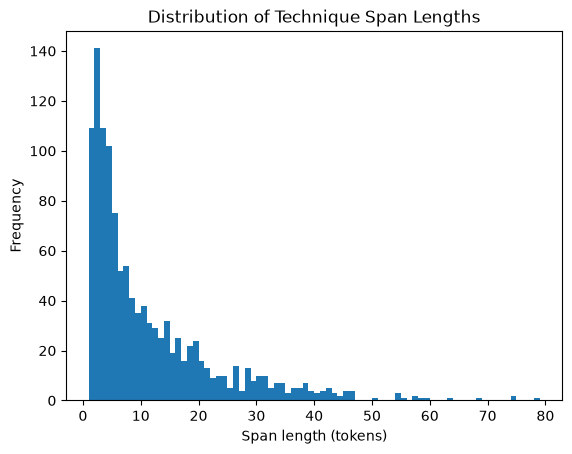

In [66]:
span_lengths = []
for i in range(len(task2_train_ds)):
    spans = task2_train_ds[i]["spans"]
    
    for label_idx in range(spans.shape[1]):
        length = spans[:, label_idx].sum().item()
        
        if length > 0:
            span_lengths.append(int(length))

plt.hist(span_lengths, bins=range(1, max(span_lengths) + 2))
plt.xlabel("Span length (tokens)")
plt.ylabel("Frequency")
plt.title("Distribution of Technique Span Lengths")
plt.show()

## Training Strategy:

To train the model I think it would be apt to train our Task 2 model using the ground truths from the training set, rather than directly using Task 1 model's outputs as an input for the Task 2 model in training. I do this because the latter option heavily relies on the performance of Task 1's model. Even if Task 1's model has an 80% recall per label, thats still ~20% of training data that is lost. 

## Evaluation Metric:

For this specific task, simple model-agnostic evaluation metrics such as simple accuracy, precision and recall will not be enough for this task. Although these metrics can help, the best method of evaluating the model is to view its outputted spans, which I will use as a primary method of evaluating the model.

A good naive benchmark that I would like to set is that:
1. The classifier, when told that "X Technique is being used" WILL span a text as being the flagger.

2. The classifier will not span texts for techniques which we do not say are being part of its used techniques. E.g if the model flags a span of text as using technique Y when we tell it that Y is not being used in this meme, it is incorrect.

3. The classifier, given that it was inputted the correct techniques, should span at least one subsection contained within the actual span. E.g if a meme has spanned "This spans Loaded Language", the model should ideally create a span which contains at least some part of this span, like "spans Loaded Language". 

EXTRA NOTE: For markers, one of my evaluation metrics that I use, write_examples(), actually writes out its results into a seperate text file, rather than print it out onto the console. I found this to be preferable because of the sheer size of the print message, which would be difficult to read directly in the console. Although this MAY be an infridgement of the technical requirement: "All decision-supporting figures must be embedded in the notebook". I found this to be the easiest method of using this custom function. I have embedded screenshots of relevant excerpts from each file into the document, however, if you wish to view the actual text file, you may either run the code block to generate that file, or print it out in the notebook. I shall create code blocks for either option.

In [67]:
task2_example_set = {}

for example in task2_test_ds:
    for label_index, val in enumerate(example["labels"]):
        if not val:
            continue
        
        technique = LABELS[label_index]
        
        task2_example_set.setdefault(technique, []).append(example)

In [68]:

def evaluate_task2(model, loader, num_examples=1):
    """
    Task 2 equivalent of evaluate_model() in task 1.
    """
    model.eval()

    total_tp = torch.zeros(len(LABELS)).to(device)
    total_fp = torch.zeros(len(LABELS)).to(device)
    total_fn = torch.zeros(len(LABELS)).to(device)
    total_tn = torch.zeros(len(LABELS)).to(device)
    
    total_loss, total = 0.0, 0
    examples = []

    with torch.inference_mode():
        for batch in loader:

            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            spans = batch['spans'].to(device)
            techniques = batch['labels'].to(device)

            logits = model(input_ids, attention_mask, techniques)

            # Get rid of the positions for [CLS] and [SEP] 
            spans = spans[:, 1:-1, :]
            attention_mask = attention_mask[:, 1:-1]
            
            loss = criterion(logits, spans)

            mask = attention_mask.unsqueeze(-1)
            
            # Get the mean loss
            loss = (loss * mask).sum() / mask.expand_as(loss).sum()

            total_loss += loss.item() * input_ids.size(0)
            total += input_ids.size(0)

            # Creates probabilities and converts them to boolean signals
            probabilities = torch.sigmoid(logits)
            predicted_spans = probabilities >= 0.5

            # Calculate metrics
            metric_mask = mask.bool()

            tp = predicted_spans & (spans == 1) & metric_mask
            fp = predicted_spans & (spans == 0) & metric_mask
            fn = (~predicted_spans) & (spans == 1) & metric_mask
            tn = (~predicted_spans) & (spans == 0) & metric_mask
            
            # Sum over batch
            total_tp += tp.sum(dim=(0, 1))
            total_fp += fp.sum(dim=(0, 1))
            total_fn += fn.sum(dim=(0, 1))
            total_tn += tn.sum(dim=(0, 1))
            
        # Save examples
        for technique in LABELS:
            # Looks through our set of examples and saves model outputs to a dictionary
            example_set = task2_example_set[technique]
            for i in range(min(num_examples, len(example_set))):
                example = example_set[i]
                
                input_ids = example['input_ids'].unsqueeze(0).to(device)
                attention_mask = example['attention_mask'].unsqueeze(0).to(device)
                spans = example['spans'].unsqueeze(0).to(device)
                techniques = example['labels'].unsqueeze(0).to(device)

                logits = model(input_ids, attention_mask, techniques)

                spans = spans[:, 1:-1, :]
                attention_mask = attention_mask[:, 1:-1]
                
                probabilities = torch.sigmoid(logits)
                predicted_spans = probabilities >= 0.5

                # Convert to lists for easier handling
                predicted_spans_list = predicted_spans.squeeze(0).cpu().numpy().tolist()
                true_spans_list = spans.squeeze(0).cpu().numpy().tolist()

                examples.append({
                    "text": example["text"],
                    "predicted_spans": predicted_spans_list,
                    "true_spans": true_spans_list,
                    "labels": techniques
                })

    # Calculate macro metrics for the model.
    tp = total_tp.cpu().numpy()
    fp = total_fp.cpu().numpy()
    fn = total_fn.cpu().numpy()
    tn = total_tn.cpu().numpy()
    
    precision = np.divide(
        tp, tp + fp,
        out=np.zeros(len(LABELS), dtype=float),
        where=(tp + fp)>0
    )
    
    recall = np.divide(
        tp, tp + fn,
        out=np.zeros(len(LABELS), dtype=float),
        where=(tp + fn)>0
    )
    
    f1 = np.divide(
        2 * precision * recall, precision + recall,
        out=np.zeros(len(LABELS), dtype=float),
        where=(precision + recall)>0
    )
    
    accuracy = np.divide(
        tp + tn, tp + fp + fn + tn,
        out=np.zeros(len(LABELS), dtype=float),
        where=(tp+tn+fp+fn)>0
    )
    
    # Take the mean of all metrics to get the macro metrics
    precision = precision.mean()
    recall = recall.mean()
    f1 = f1.mean()
    accuracy = accuracy.mean()
    
    metrics = {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "loss": total_loss / total
    }

    return metrics, examples

In [69]:
def train_one_epoch_task2(model, loader, optimizer, criterion):
    """
    Task 2 equivalent of train_one_epoch in Task 1.
    """
    
    model.train()
    
    total_loss, total = 0.0, 0
    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        spans = batch['spans'].to(device)
        techniques = batch['labels'].to(device)
        
        optimizer.zero_grad()
        
        logits = model(input_ids, attention_mask, techniques)
        
        # Get rid of positions for [CLS] and [SEP]
        spans = spans[:, 1:-1, :]
        attention_mask = attention_mask[:, 1:-1]
        
        loss = criterion(logits, spans)
        
        mask = attention_mask.unsqueeze(-1)
        
        # Get the mean loss
        loss = (loss * mask).sum() / mask.expand_as(loss).sum()
        
        loss.backward()
        
        optimizer.step()
        
        total_loss += loss.item() * input_ids.size(0)
        total += input_ids.size(0)
    
    return total_loss / total

def run_experiment_task2(model, optimizer, criterion, train_loader, val_loader, 
                         epochs=10, name='Model', load_best_model=True):
    """
    Task 2 equivalent of run_experiment in Task 1
    """
    
    history = {'train_loss': [], 'val_loss': []}
    best_model = None
    best_loss = float('inf')
    
    for epoch in range(epochs):
        train_loss = train_one_epoch_task2(model, train_loader, optimizer, criterion)
        val_loss = evaluate_task2(model, val_loader)[0]['loss']
        
        if val_loss < best_loss:
            best_loss = val_loss
            best_model = copy.deepcopy(model.state_dict())
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        
        if (epoch + 1) % max(1, epochs // 5) == 0 or epoch == 0:
            print(f'  [{name}] Epoch {epoch+1}/{epochs} — '
                    f'Train: {train_loss:.4f} | Val: {val_loss:.4f}')
        
    
    if best_model is not None and load_best_model:
        model.load_state_dict(best_model)
    
    return history

In [70]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def write_examples(examples, write_path="test.txt", to_console = False, skip_unflagged_labels=True):
    """
    Custom Evaluation function. Takes a set of examples and writes our model's predicted spans and their true spans to a seperate file.
    skip_unflagged_labels controls whether we print out the evaluation metrics for the unflagged labels.
    E.g if the true labels for a meme is X and Y, we can choose whether to see the metrics for Z.
    Might be useful for the final model, when we can make mistakes in choosing which techniques are being used.
    """
    
    with open(write_path, "w") as f:
        for id, example in enumerate(examples):
            f.write("--------------------------------------------------\n")
            f.write("--------------------------------------------------\n")
            f.write(f"Example ID: {id}\n")
            
            tokens = tokenizer(
                        example["text"],
                        padding='max_length',
                        truncation=True,
                        max_length=128,
                        return_offsets_mapping=True
                    )
            
            tokens = tokenizer.convert_ids_to_tokens(tokens["input_ids"])
            tokens = tokens[1:-1]
            
            true_spans = np.array(example["true_spans"])
            predicted_spans = np.array(example["predicted_spans"])
            
            f.write(f"Text:\n{example['text']}\n")
            f.write("\n")
            
            f.write("--------------------------------------------------\n")
            f.write("True Techniques:\n")
            for technique_index, value in enumerate(example["labels"][0]):
                if value:
                    f.write(f"- {LABELS[technique_index]}\n")
            f.write("\n")
            f.write("--------------------------------------------------\n")
            f.write("Spanned Techniques:\n")
            for technique_index, value in enumerate(LABELS):
                if True in predicted_spans[:, technique_index]:
                    f.write(f"- {value}\n")
            
            f.write("--------------------------------------------------\n")
            f.write("Predicted Spans:\n")
            
            # Writes out the Predicted Spans
            start_idx = [-1 for i in range(20)]
            for token_index, row in enumerate(predicted_spans):
                for technique_index, value in enumerate(row):
                    # For each token index, check if the value in the span is 0 or 1.
                    # If its 1:
                    #   - Check if we've opened a span already.
                    #   - If a span is already opened:
                    #       - Ignore it
                    #   - Else:
                    #       - Open a span and remember this index as the "start"
                    # If its 0:
                    #   - Check if we have an open span
                    #   - If we do:
                    #       - Close the span and set the index before this as the end_index, then writes it out.
                    #   - Else:
                    #       - Ignore it
                    if value:
                        if start_idx[technique_index] == -1:
                            start_idx[technique_index] = token_index
                    else:
                        if start_idx[technique_index] != -1:
                            technique_start_index = start_idx[technique_index]
                            technique_end_index = token_index
                            
                            f.write(" ".join(tokens[technique_start_index:technique_end_index]))
                            f.write("\n")
                            
                            f.write(f"Technique: {LABELS[technique_index]}\nStart: {technique_start_index}\nEnd: {technique_end_index}\n")
                            start_idx[technique_index] = -1
            
            # Closes out unclosed spans (not unclosed by the model, but unclosed by our detection loop).
            for technique_index in range(len(LABELS)):
                if start_idx[technique_index] != -1:
                    technique_start_index = start_idx[technique_index]
                    technique_end_index = len(predicted_spans) - 1
                    
                    f.write(" ".join(example["text"].split()[technique_start_index:technique_end_index]))
                    f.write("\n")
                                                
                    f.write(f"Technique: {LABELS[technique_index]}\nStart: {technique_start_index}\nEnd: {technique_end_index}\n")
            
            f.write("--------------------------------------------------\n")
            f.write("\n")
            f.write("True Spans:\n")
            
            # Writes out the True Spans
            start_idx = [-1 for i in range(20)]
            for token_index, row in enumerate(true_spans):
                for technique_index, value in enumerate(row):
                    # For each token index, check if the value in the span is 0 or 1.
                    # If its 1:
                    #   - Check if we've opened a span already.
                    #   - If a span is already opened:
                    #       - Ignore it
                    #   - Else:
                    #       - Open a span and remember this index as the "start"
                    # If its 0:
                    #   - Check if we have an open span
                    #   - If we do:
                    #       - Close the span and set the index before this as the end_index, then writes it out.
                    #   - Else:
                    #       - Ignore it
                    if value:
                        if start_idx[technique_index] == -1:
                            start_idx[technique_index] = token_index
                    else:
                        if start_idx[technique_index] != -1:
                            technique_start_index = start_idx[technique_index]
                            technique_end_index = token_index
                            
                            f.write(" ".join(tokens[technique_start_index:technique_end_index]))
                            f.write("\n")
                            
                            f.write(f"Technique: {LABELS[technique_index]}\nStart: {technique_start_index}\nEnd: {technique_end_index}\n")
                            start_idx[technique_index] = -1
            
            # Closes out unclosed spans (not unclosed by the model, but unclosed by our detection loop).
            for technique_index in range(len(LABELS)):
                if start_idx[technique_index] != -1:
                    technique_start_index = start_idx[technique_index]
                    technique_end_index = len(true_spans) - 1
                    
                    f.write(" ".join(example["text"].split()[technique_start_index:technique_end_index]))
                    f.write("\n")
                    
                    f.write(f"Technique: {LABELS[technique_index]}\nStart: {technique_start_index}\nEnd: {technique_end_index}\n")

            f.write("--------------------------------------------------\n")
            f.write("\n")

            true_spans = np.array(true_spans)
            predicted_spans = np.array(predicted_spans)
            
            # Writes out the per-label evaluation metrics.
            for technique_index, technique in enumerate(LABELS):
                if skip_unflagged_labels and not example["labels"][0][technique_index].sum():
                    continue
                
                true_label = true_spans[:, technique_index]
                predicted_label = predicted_spans[:, technique_index]
                
                f.write(f"LABEL: {technique}\n")
                f.write(f"Accuracy: {accuracy_score(true_label, predicted_label) :.3f}\n")
                f.write(f"Precision: {precision_score(true_label, predicted_label, zero_division=0) :.3f}\n")
                f.write(f"Recall: {recall_score(true_label, predicted_label, zero_division=0) :.3f}\n")
                f.write(f"F1: {f1_score(true_label, predicted_label, zero_division=0) :.3f}\n")
                f.write("\n")
            
            # Writes out the overall macro metrics. 
            f.write("--------------------------------------------------\n")
            f.write(f"Macro Metrics:\n")
            f.write(f"Accuracy: {accuracy_score(true_spans, predicted_spans) :.3f}\n")
            f.write(f"Macro Precision: {precision_score(true_spans, predicted_spans, zero_division=0, average='macro') :.3f}\n")
            f.write(f"Macro Recall: {recall_score(true_spans, predicted_spans, zero_division=0, average='macro') :.3f}\n")
            f.write(f"Macro F1: {f1_score(true_spans, predicted_spans, zero_division=0, average='macro') :.3f}\n")
            f.write("\n")
    
    if to_console:
        with open(write_path, "r") as f:
            print(f.read())

## Building the Model

### Baseline Model:

For my baseline model, I decide to just use one incredibly basic classifier head which takes the hidden states from our task 1 model's encoding of the input string and concatenates a tensor of shape 20 which represents which techniques we predict to be in the meme. One important point that I would like to make in my architecture is the removal of the [CLS] and [SEP] tokens. [SEP] means nothing on its own and can simply be removed, as it is just used to seperate different documents. [CLS] is used as somewhat of a "document summarizer" and does not actually represent a token within our meme, we don't need a summarizer, as we want to flag specific instances, which is why I cut it out. 

In [71]:
class Task2BaselineHead(nn.Module):
    def __init__(self, num_labels, task1_model, hidden_dim=768):
        super().__init__()
        
        self.distilbert = task1_model.distilbert
        
        for param in self.distilbert.parameters():
            param.requires_grad = False
        
        self.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(hidden_dim + len(LABELS), 256),
            nn.ReLU(),
            nn.Linear(256, num_labels)
        )
    
    def forward(self, input_ids, attention_mask, techniques):
        outputs = self.distilbert(input_ids=input_ids, attention_mask=attention_mask)
        
        hidden_states = outputs.last_hidden_state
        hidden_states = hidden_states[:, 1:-1, :]
        
        # Concatenate the hidden states with the technique embeddings
        technique_embeddings = techniques.unsqueeze(1).repeat(1, hidden_states.size(1), 1)
        
        combined = torch.cat([hidden_states, technique_embeddings], dim=-1)
        
        return self.classifier(combined)

### Training the Model:

Because of the simplicity of this task over Task 1, I am able to use a larger learning rate and lower the number of epochs for sufficient training. The model seems to learn well with a smooth curve good learning and convergence and no signs of overfitting. 

  [Task2Baseline] Epoch 1/20 — Train: 0.5519 | Val: 0.2914
  [Task2Baseline] Epoch 4/20 — Train: 0.1565 | Val: 0.1744
  [Task2Baseline] Epoch 8/20 — Train: 0.1237 | Val: 0.1463
  [Task2Baseline] Epoch 12/20 — Train: 0.1113 | Val: 0.1358
  [Task2Baseline] Epoch 16/20 — Train: 0.1024 | Val: 0.1317
  [Task2Baseline] Epoch 20/20 — Train: 0.0948 | Val: 0.1303


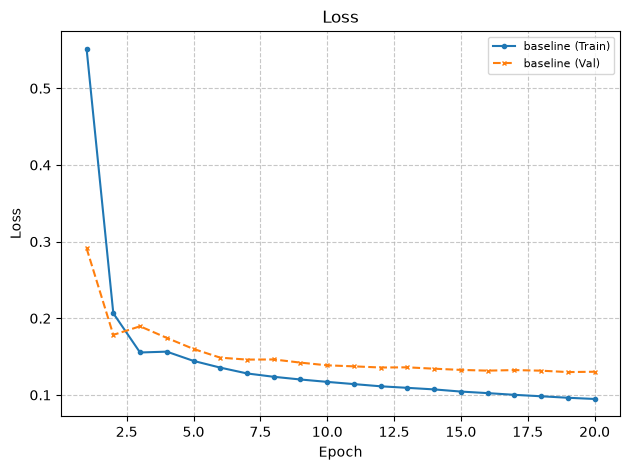

In [72]:
torch.manual_seed(67)
test_model = Task2BaselineHead(num_labels=len(LABELS), task1_model=final_task1_model).to(device)

optimizer = optim.Adam(test_model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss(reduction='none')

baseline_result = {}
baseline_result['baseline'] = run_experiment_task2(test_model, optimizer, criterion, 
                                     task2_train_loader, task2_val_loader, 
                                         epochs=20, name='Task2Baseline', load_best_model=False)

plot_experiments(baseline_result)

### Evaluating the Model:

Viewing the direct examples, I can see many large issues with the current model. 

1. The model rarely spans sequences of text. Instead most of its spans are one-token long. In these examples below, it creates one token length spans rather than the long span of text that the ground truth shows.

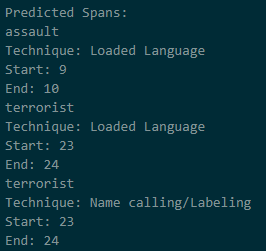

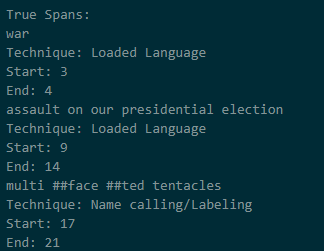

2. The model sometimes spans [PAD] tokens, even though these are usually out of the context of the meme and should not be happening.

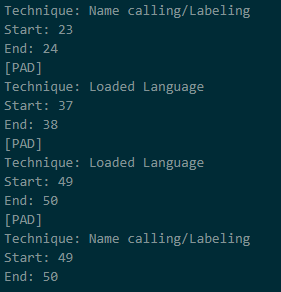

3. The model will sometimes either not predict for a flagged technique. E.g In this example, it does not even make any predictions, despite the flagged techniques.

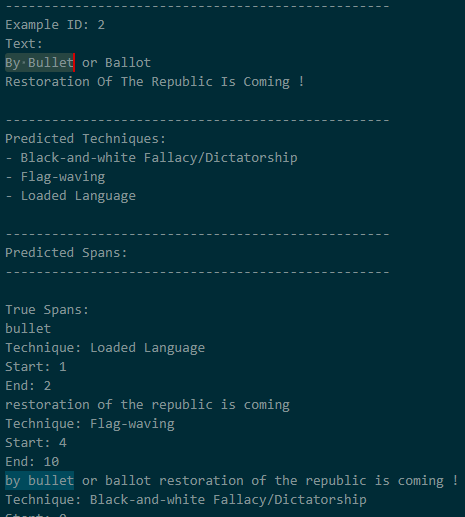

4. Or the model will predict for the wrong technique. E.g In this example, the model repeatedly makes spans for the "Whataboutisms" technique, despite it not being one of the flagged techniques. 

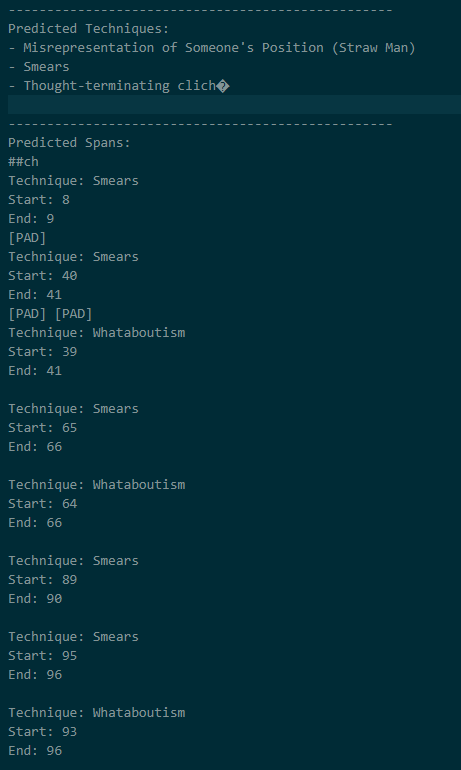
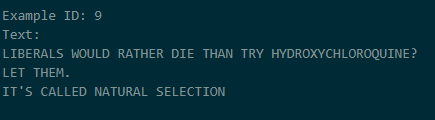

Because of these issues, this classifier head is completely unfit for the task.

In [73]:
metrics, examples = evaluate_task2(test_model, task2_test_loader)

for key in metrics:
    print(f"{key}: {metrics[key] :.3f}")

accuracy: 0.961
precision: 0.255
recall: 0.043
f1: 0.064
loss: 0.127


In [ ]:
write_examples(examples, 
               "baseline.txt", 
               to_console=True, 
               skip_unflagged_labels=True)

--------------------------------------------------
--------------------------------------------------
Example ID: 0
Text:
COWBOY WISDOM
"The water ain't gonna clear up 'til you get the pigs outa the creek!"


--------------------------------------------------
True Techniques:
- Appeal to authority
- Loaded Language

--------------------------------------------------
Spanned Techniques:
--------------------------------------------------
Predicted Spans:
--------------------------------------------------

True Spans:
get the pigs out ##a the creek !
Technique: Loaded Language
Start: 14
End: 22
cowboy wisdom " the water ain ' t gonna clear up ' til you get the pigs out ##a the creek ! "
Technique: Appeal to authority
Start: 0
End: 23
--------------------------------------------------

LABEL: Appeal to authority
Accuracy: 0.817
Precision: 0.000
Recall: 0.000
F1: 0.000

LABEL: Loaded Language
Accuracy: 0.937
Precision: 0.000
Recall: 0.000
F1: 0.000

-----------------------------------------

### Improvement 1: Specialized Classifier Heads

One limitation of our baseline model is the fact that we have one generic classifier head to do spanning for every single technique. The head can then not be able to specialize into spanning for one specific technique, we expect that relying on one of two single weights to completely change how the model reacts. By instead changing the model so that we have multiple classifier heads and can choose which one to use for which technique, each head is able to specialize into its niche, and learning should improve. Furthermore, since we're only using the heads for techniques we predict are in the meme, it means that for other techniques, we will always have a completely empty span vector.

### Modifications to Functions


In [75]:
def evaluate_task2(model, loader, num_examples=1):
    """
    Task 2 equivalent of evaluate_model from Task 1.
    Adapted for Experiments 2, by adjusting the loss function to account for multiple specialized heads.
    """
    
    model.eval()

    total_tp = torch.zeros(len(LABELS)).to(device)
    total_fp = torch.zeros(len(LABELS)).to(device)
    total_fn = torch.zeros(len(LABELS)).to(device)
    total_tn = torch.zeros(len(LABELS)).to(device)
    
    total_loss, total = 0.0, 0
    examples = []

    with torch.inference_mode():
        for batch in loader:

            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            spans = batch['spans'].to(device)
            techniques = batch['labels'].to(device)
            
            # Create a mask which masks out techniques which are not being used
            technique_mask = techniques.unsqueeze(1)

            logits = model(input_ids, attention_mask, techniques)

            # Get rid of the positions for [CLS] and [SEP]
            spans = spans[:, 1:-1, :]
            attention_mask = attention_mask[:, 1:-1]
            
            loss = criterion(logits, spans)

            mask = attention_mask.unsqueeze(-1)
            
            # Combine the technique and attention mask
            combined_mask = mask * technique_mask
            
            # Get the mean loss
            loss = (loss * combined_mask).sum() / combined_mask.expand_as(loss).sum()

            total_loss += loss.item() * input_ids.size(0)
            total += input_ids.size(0)

            # Creates probabilities and converts them to boolean signals
            probabilities = torch.sigmoid(logits)
            predicted_spans = probabilities >= 0.5

            # Calculate Metrics
            metric_mask = mask.bool()

            tp = predicted_spans & (spans == 1) & metric_mask
            fp = predicted_spans & (spans == 0) & metric_mask
            fn = (~predicted_spans) & (spans == 1) & metric_mask
            tn = (~predicted_spans) & (spans == 0) & metric_mask

            # Sum over batch
            total_tp += tp.sum(dim=(0, 1))
            total_fp += fp.sum(dim=(0, 1))
            total_fn += fn.sum(dim=(0, 1))
            total_tn += tn.sum(dim=(0, 1))
        
        # Save examples
        for technique in LABELS:
            # Looks through our set of examples and saves model outputs to a dictionary
            example_set = task2_example_set[technique]
            for i in range(min(num_examples, len(example_set))):
                example = example_set[i]
                
                input_ids = example['input_ids'].unsqueeze(0).to(device)
                attention_mask = example['attention_mask'].unsqueeze(0).to(device)
                spans = example['spans'].unsqueeze(0).to(device)
                techniques = example['labels'].unsqueeze(0).to(device)
                lengths = torch.tensor([example['lengths']]).to(device)
                
                logits = model(input_ids, attention_mask, techniques)

                spans = spans[:, 1:-1, :]
                attention_mask = attention_mask[:, 1:-1]
                
                probabilities = torch.sigmoid(logits)
                predicted_spans = probabilities >= 0.5

                # Convert to lists for easier handling
                predicted_spans_list = predicted_spans.squeeze(0).cpu().numpy().tolist()
                true_spans_list = spans.squeeze(0).cpu().numpy().tolist()

                examples.append({
                    "text": example["text"],
                    "predicted_spans": predicted_spans_list,
                    "true_spans": true_spans_list,
                    "labels": techniques
                })

    # Calculate macro metrics for the model.
    tp = total_tp.cpu().numpy()
    fp = total_fp.cpu().numpy()
    fn = total_fn.cpu().numpy()
    tn = total_tn.cpu().numpy()
    
    precision = np.divide(
        tp, tp + fp,
        out=np.zeros(len(LABELS), dtype=float),
        where=(tp + fp)>0
    )
    
    recall = np.divide(
        tp, tp + fn,
        out=np.zeros(len(LABELS), dtype=float),
        where=(tp + fn)>0
    )
    
    f1 = np.divide(
        2 * precision * recall, precision + recall,
        out=np.zeros(len(LABELS), dtype=float),
        where=(precision + recall)>0
    )
    
    accuracy = np.divide(
        tp + tn, tp + fp + fn + tn,
        out=np.zeros(len(LABELS), dtype=float),
        where=(tp+tn+fp+fn)>0
    )
    
    # Take the mean of all metrics to get the macro metrics
    precision = precision.mean()
    recall = recall.mean()
    f1 = f1.mean()
    accuracy = accuracy.mean()

    metrics = {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "loss": total_loss / total
    }

    return metrics, examples

### Building the Model:

In [76]:

class Task2SpecializedHeads(nn.Module):
    def __init__(self, num_labels, task1_model, hidden_dim=768):
        super().__init__()
        
        self.num_labels = num_labels
        self.distilbert = task1_model.distilbert
        
        for param in self.distilbert.parameters():
            param.requires_grad = False
        
        # Set of specialized heads that we can choose from for each technique. 
        self.heads = nn.ModuleList(
                                    nn.Sequential(
                                        nn.Dropout(0.2),
                                        nn.Linear(hidden_dim, 256),
                                        nn.ReLU(),
                                        nn.Linear(256, 1)
                                    )
            
                                    for label in range(num_labels)
                                )
    
    def forward(self, input_ids, attention_mask, techniques):
        outputs = self.distilbert(input_ids=input_ids, attention_mask=attention_mask)
        
        hidden_states = outputs.last_hidden_state
        
        # Remove [CLS] and [SEP] tokens
        hidden_states = hidden_states[:, 1:-1, :]
        
        # Initialize outputs to be by default negative.
        outputs = torch.full((hidden_states.size(0),
                                hidden_states.size(1),
                                self.num_labels),
                                -1e9).to(device)

        # Only edit the outputs corresponding to a technique we got in the input.
        for technique_index, head in enumerate(self.heads):
            active = techniques[:, technique_index].bool()
            
            if active.any():
                head_output = head(hidden_states[active])
                
                outputs[active, :, technique_index] = head_output.squeeze(-1)
        
        return outputs

  [SpecializedHeads] Epoch 1/20 — Train: 0.0596 | Val: 0.4917
  [SpecializedHeads] Epoch 4/20 — Train: 0.0410 | Val: 0.4446
  [SpecializedHeads] Epoch 8/20 — Train: 0.0332 | Val: 0.4378
  [SpecializedHeads] Epoch 12/20 — Train: 0.0286 | Val: 0.4542
  [SpecializedHeads] Epoch 16/20 — Train: 0.0254 | Val: 0.4690
  [SpecializedHeads] Epoch 20/20 — Train: 0.0226 | Val: 0.4810


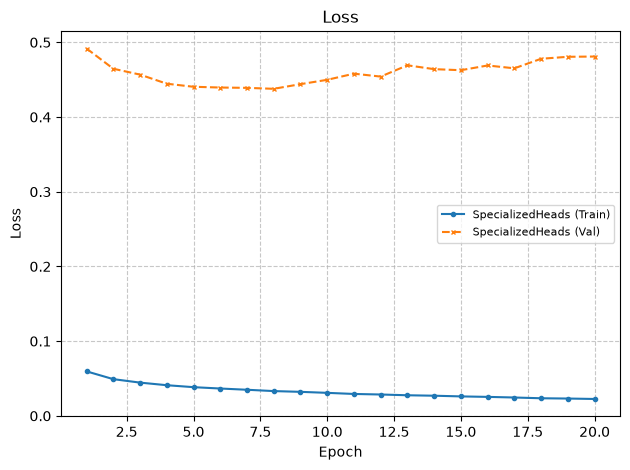

In [77]:
torch.manual_seed(67)
Task2SpecializedHead_Model = Task2SpecializedHeads(num_labels=len(LABELS), task1_model=final_task1_model).to(device)

optimizer = optim.Adam(Task2SpecializedHead_Model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss(reduction='none')
specializedhead_result = {}
specializedhead_result['SpecializedHeads'] = run_experiment_task2(Task2SpecializedHead_Model, optimizer, criterion,
                                                                  task2_train_loader, task2_val_loader,
                                                                  epochs=20, name="SpecializedHeads", load_best_model=False)

plot_experiments(specializedhead_result)

### Evaluating the Model:

The model immediately performs much better than the baseline. Just from its macro metrics, it has a much higher f1-score of 0.703 over the previous 0.230. Recall of 0.688 over 0.140 and precision of X over 0.655. 

Looking at the examples, I can see that we've almost completely solved the previous problems of:
1. One-token length spans. Now, spans are usually more than one token long. The same example of "assault", "war", etc. Gets spanned into "is a complex assault on"

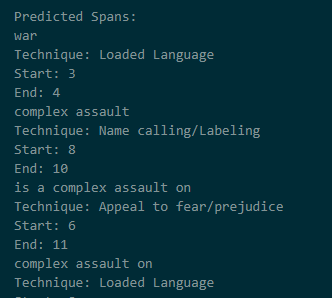

2. Predicting for the wrong technique. Because of our new architecture, it is now impossible for the model to create spanning predictions for techniques that we did not add to our input.

What is remaining are the problems of:

1. The model can still sometimes not span anything for a meme despite a technique being inputted. 

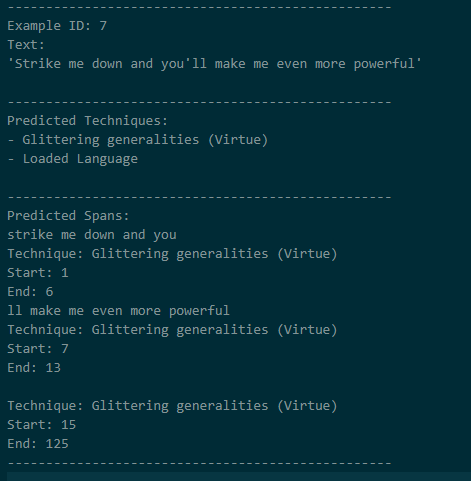

2. The model still spans out of bounds, creating spans in the [PAD] sections.

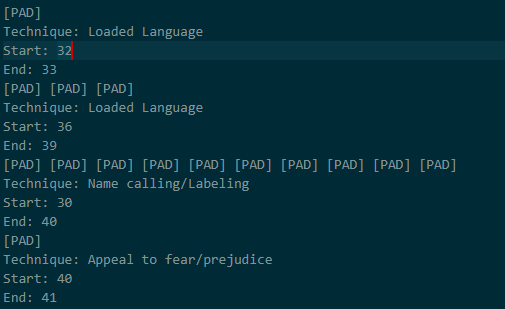

In [78]:
metrics, examples = evaluate_task2(Task2SpecializedHead_Model, task2_test_loader)

for key in metrics:
    print(f"{key}: {metrics[key] :.3f}")

accuracy: 0.977
precision: 0.669
recall: 0.655
f1: 0.625
loss: 0.610


In [79]:
write_examples(examples, 
               "Task2Specialized_Model.txt", 
               to_console=True, 
               skip_unflagged_labels=True)

--------------------------------------------------
--------------------------------------------------
Example ID: 0
Text:
COWBOY WISDOM
"The water ain't gonna clear up 'til you get the pigs outa the creek!"


--------------------------------------------------
True Techniques:
- Appeal to authority
- Loaded Language

--------------------------------------------------
Spanned Techniques:
- Appeal to authority
- Loaded Language
--------------------------------------------------
Predicted Spans:
pigs
Technique: Loaded Language
Start: 16
End: 17
cowboy wisdom " the water ain ' t gonna clear up ' til you get the pigs out ##a the creek ! "
Technique: Appeal to authority
Start: 0
End: 23
[PAD]
Technique: Loaded Language
Start: 45
End: 46
[PAD]
Technique: Loaded Language
Start: 100
End: 101

Technique: Appeal to authority
Start: 24
End: 125
--------------------------------------------------

True Spans:
get the pigs out ##a the creek !
Technique: Loaded Language
Start: 14
End: 22
cowboy wisdom 

### Improvement 2: Masking

The simplest solution that I can think of to solve the out of bounds issue is by simply creating a mask over the lengths of each meme and only allowing logits to be created within those bounds. This should not effect other model metrics, but just get rid of this lingering issue. To do this, I will need to get the length of each meme as an input for our model.

### Adjustments to Methods:

We need to adjust the following methods so that we pass in the length parameter to model when predicting. 

In [80]:
def evaluate_task2(model, loader, num_examples=1):
    """
    Task 2 equivalent of evaluate_model from Task 1.
    Adapted for Experiments 3, by passing new length parameter to model.
    """
    
    model.eval()

    total_tp = torch.zeros(len(LABELS)).to(device)
    total_fp = torch.zeros(len(LABELS)).to(device)
    total_fn = torch.zeros(len(LABELS)).to(device)
    total_tn = torch.zeros(len(LABELS)).to(device)
    
    total_loss, total = 0.0, 0
    examples = []

    with torch.inference_mode():
        for batch in loader:

            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            spans = batch['spans'].to(device)
            techniques = batch['labels'].to(device)
            lengths = batch['lengths'].to(device)
            
            # Create a mask which masks out techniques which are not being used
            technique_mask = techniques.unsqueeze(1)

            logits = model(input_ids, attention_mask, lengths, techniques)

            # Get rid of the positions for [CLS] and [SEP]
            spans = spans[:, 1:-1, :]
            attention_mask = attention_mask[:, 1:-1]
            
            loss = criterion(logits, spans)

            mask = attention_mask.unsqueeze(-1)
            
            # Combine the technique and attention mask
            combined_mask = mask * technique_mask
            
            # Get the mean loss
            loss = (loss * combined_mask).sum() / combined_mask.expand_as(loss).sum()

            total_loss += loss.item() * input_ids.size(0)
            total += input_ids.size(0)

            # Creates probabilities and converts them to boolean signals
            probabilities = torch.sigmoid(logits)
            predicted_spans = probabilities >= 0.5

            # Calculate Metrics
            metric_mask = mask.bool()

            tp = predicted_spans & (spans == 1) & metric_mask
            fp = predicted_spans & (spans == 0) & metric_mask
            fn = (~predicted_spans) & (spans == 1) & metric_mask
            tn = (~predicted_spans) & (spans == 0) & metric_mask

            # Sum over batch
            total_tp += tp.sum(dim=(0, 1))
            total_fp += fp.sum(dim=(0, 1))
            total_fn += fn.sum(dim=(0, 1))
            total_tn += tn.sum(dim=(0, 1))
        
        # Save examples
        for technique in LABELS:
            # Looks through our set of examples and saves model outputs to a dictionary
            example_set = task2_example_set[technique]
            for i in range(min(num_examples, len(example_set))):
                example = example_set[i]
                
                input_ids = example['input_ids'].unsqueeze(0).to(device)
                attention_mask = example['attention_mask'].unsqueeze(0).to(device)
                spans = example['spans'].unsqueeze(0).to(device)
                techniques = example['labels'].unsqueeze(0).to(device)
                lengths = torch.tensor([example['lengths']]).to(device)
                
                logits = model(input_ids, attention_mask, lengths, techniques)

                spans = spans[:, 1:-1, :]
                attention_mask = attention_mask[:, 1:-1]
                
                probabilities = torch.sigmoid(logits)
                predicted_spans = probabilities >= 0.5

                # Convert to lists for easier handling
                predicted_spans_list = predicted_spans.squeeze(0).cpu().numpy().tolist()
                true_spans_list = spans.squeeze(0).cpu().numpy().tolist()

                examples.append({
                    "text": example["text"],
                    "predicted_spans": predicted_spans_list,
                    "true_spans": true_spans_list,
                    "labels": techniques
                })

    # Calculate macro metrics for the model.
    tp = total_tp.cpu().numpy()
    fp = total_fp.cpu().numpy()
    fn = total_fn.cpu().numpy()
    tn = total_tn.cpu().numpy()
    
    precision = np.divide(
        tp, tp + fp,
        out=np.zeros(len(LABELS), dtype=float),
        where=(tp + fp)>0
    )
    
    recall = np.divide(
        tp, tp + fn,
        out=np.zeros(len(LABELS), dtype=float),
        where=(tp + fn)>0
    )
    
    f1 = np.divide(
        2 * precision * recall, precision + recall,
        out=np.zeros(len(LABELS), dtype=float),
        where=(precision + recall)>0
    )
    
    accuracy = np.divide(
        tp + tn, tp + fp + fn + tn,
        out=np.zeros(len(LABELS), dtype=float),
        where=(tp+tn+fp+fn)>0
    )
    
    # Take the mean of all metrics to get the macro metrics
    precision = precision.mean()
    recall = recall.mean()
    f1 = f1.mean()
    accuracy = accuracy.mean()

    metrics = {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "loss": total_loss / total
    }

    return metrics, examples

In [81]:
def train_one_epoch_task2(model, loader, optimizer, criterion):
    """
    Task 2 equivalent of train_one_epoch in Task 1. 
    Adapted for Experiment 3 by passing in the new parameter lengths into model.
    """
    model.train()
    
    total_loss, total = 0.0, 0
    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        spans = batch['spans'].to(device)
        techniques = batch['labels'].to(device)
        lengths = batch['lengths'].to(device)
        
        # Create a mask which masks out techniques which are not being used
        technique_mask = techniques.unsqueeze(1)
        
        optimizer.zero_grad()
        
        logits = model(input_ids, attention_mask, lengths, techniques)
        
        # Get rid of positions for [CLS] and [SEP]
        spans = spans[:, 1:-1, :]
        attention_mask = attention_mask[:, 1:-1]
        
        loss = criterion(logits, spans)
        
        mask = attention_mask.unsqueeze(-1)
        
        # Combines the attention mask and technique mask
        mask = mask * technique_mask
        
        # Get the mean loss
        loss = (loss * mask).sum() / mask.expand_as(loss).sum()
        
        loss.backward()
        
        optimizer.step()
        
        total_loss += loss.item() * input_ids.size(0)
        total += input_ids.size(0)
    
    return total_loss / total

## Building the Model:

Building the model follows almost the exact same steps as before, but we just add the final masking steps by taking the length of each meme and only considering positive samples within the lengths of each meme. If a meme has length 10 tokens, and the model predicts something at positions 13-15, ignore them and just set them negative. 

In [82]:
class Task2SpecializedHeads_WithMasking(nn.Module):
    def __init__(self, num_labels, task1_model, hidden_dim=768):
        super().__init__()
        
        self.num_labels = num_labels
        self.distilbert = task1_model.distilbert
        
        for param in self.distilbert.parameters():
            param.requires_grad = False
        
        # Set of specialized heads that we can choose from for each technique. 
        self.heads = nn.ModuleList(
                                    nn.Sequential(
                                        nn.Dropout(0.2),
                                        nn.Linear(hidden_dim, 256),
                                        nn.ReLU(),
                                        nn.Linear(256, 1)
                                    )
            
                                    for label in range(num_labels)
                                )
    
    def forward(self, input_ids, attention_mask, lengths, techniques):
        outputs = self.distilbert(input_ids=input_ids, attention_mask=attention_mask)
        
        hidden_states = outputs.last_hidden_state
        
        # Remove [CLS] and [SEP] tokens
        hidden_states = hidden_states[:, 1:-1, :]
        
        # Initialize outputs to be by default negative.
        outputs = torch.full((hidden_states.size(0),
                                hidden_states.size(1),
                                self.num_labels),
                                -1e9).to(device)

        # Only edit the outputs corresponding to a technique we got in the input.
        for technique_index, head in enumerate(self.heads):
            active = techniques[:, technique_index].bool()
            
            if active.any():
                head_output = head(hidden_states[active])
                
                outputs[active, :, technique_index] = head_output.squeeze(-1)
        
        # Mask out the tokens which are out of bounds and set their values to be negative.
        token_positions = torch.arange(hidden_states.size(1)).to(device).unsqueeze(0)
        valid_mask = token_positions < lengths.unsqueeze(1)
        
        outputs = outputs.masked_fill(~valid_mask.unsqueeze(-1),
                                      -1e9)
        
        return outputs

### Training the Model:

  [Task2SpecializedHead_Masking] Epoch 1/20 — Train: 0.5649 | Val: 0.4783
  [Task2SpecializedHead_Masking] Epoch 4/20 — Train: 0.3915 | Val: 0.4245
  [Task2SpecializedHead_Masking] Epoch 8/20 — Train: 0.3096 | Val: 0.4314
  [Task2SpecializedHead_Masking] Epoch 12/20 — Train: 0.2652 | Val: 0.4477
  [Task2SpecializedHead_Masking] Epoch 16/20 — Train: 0.2341 | Val: 0.4631
  [Task2SpecializedHead_Masking] Epoch 20/20 — Train: 0.2113 | Val: 0.4752


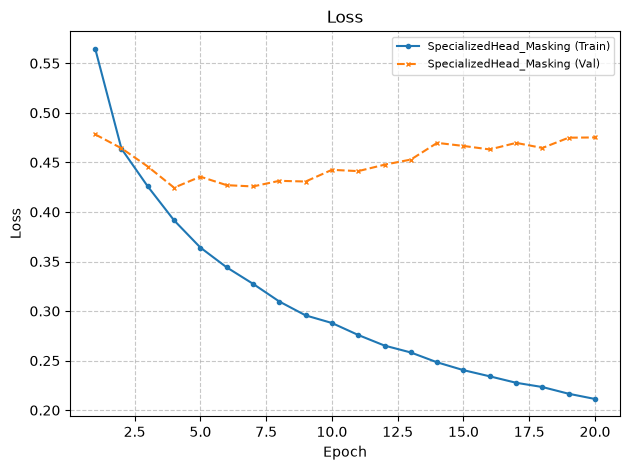

In [83]:
torch.manual_seed(67)
SpecializedHeadMasking = Task2SpecializedHeads_WithMasking(num_labels=len(LABELS), task1_model=final_task1_model).to(device)

optimizer = optim.Adam(SpecializedHeadMasking.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss(reduction='none')

SpecializedHeadMasking_Results = {}
SpecializedHeadMasking_Results['SpecializedHead_Masking'] = run_experiment_task2(SpecializedHeadMasking, optimizer, criterion, 
                                                        task2_train_loader, task2_val_loader, 
                                                        epochs=20, name='Task2SpecializedHead_Masking', load_best_model=False)

plot_experiments(SpecializedHeadMasking_Results, ["SpecializedHead_Masking"])

### Evaluating the Model:

Our overall metrics have not changed much compared to the one without masking. It only has minor improvements of around ~0.01 in precision, recall and f1. This is most likely due to the fact that the spans of [PAD] only make up a small percentage of the spanning predictions even without the masking. Examining the data, we can confirm that we have completely removed out of bound features within the predictions.

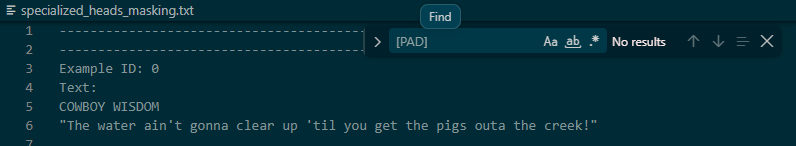

In [84]:
metrics, examples = evaluate_task2(SpecializedHeadMasking, task2_test_loader)

for key in metrics:
    print(f"{key}: {metrics[key] :.3f}")

accuracy: 0.977
precision: 0.669
recall: 0.665
f1: 0.636
loss: 0.602


In [85]:
write_examples(examples, 
               "specialized_heads_masking.txt", 
               to_console=True, 
               skip_unflagged_labels=True)

--------------------------------------------------
--------------------------------------------------
Example ID: 0
Text:
COWBOY WISDOM
"The water ain't gonna clear up 'til you get the pigs outa the creek!"


--------------------------------------------------
True Techniques:
- Appeal to authority
- Loaded Language

--------------------------------------------------
Spanned Techniques:
- Appeal to authority
--------------------------------------------------
Predicted Spans:
cowboy wisdom " the water ain ' t gonna clear up ' til you get the pigs out ##a the creek ! "
Technique: Appeal to authority
Start: 0
End: 23
--------------------------------------------------

True Spans:
get the pigs out ##a the creek !
Technique: Loaded Language
Start: 14
End: 22
cowboy wisdom " the water ain ' t gonna clear up ' til you get the pigs out ##a the creek ! "
Technique: Appeal to authority
Start: 0
End: 23
--------------------------------------------------

LABEL: Appeal to authority
Accuracy: 1.000


### Final Task 2 Classifier Evaluation

I decide that the model previously will be suitable for our Task 2 Classifier.

To clarify our naive benchmarks for the classifier were:

1. The classifier, when told that "X Technique is being used" WILL span a text as being the flagger.

2. The classifier will not span texts for techniques which we do not say are being part of its used techniques. E.g if the model flags a span of text as using technique Y when we tell it that Y is not being used in this meme, it is incorrect.

3. The classifier, given that it was inputted the correct techniques, should span at least one subsection contained within the actual span. E.g if a meme has spanned "This spans Loaded Language", the model should ideally create a span which contains at least some part of this span, like "spans Loaded Language". 

Our final classifier:

1. When told that "X technique is being used" MIGHT sometimes not span any text as being the flagger.

2. Will never span texts for techniques which we did not input it for. E.g if we did not tell the classifier that the meme uses technique Y, it will never create a span for technique Y.

3. Our classifier will most of the time span at least some subsection of the true span.

For benchmark 2, this is simply because of the architecture of how we decided to implement our classifier. Where it physically is unable to create these spans. 

For benchmark 3, a macro recall of 0.736, with a precision of 0.721 supports the contention that our model is able to flag spans of texts which contain at least some subset of the ground truth spans. Specifically, the precision of 0.721 also supports the idea that only some unneccessary sections were included in our spans, ~72% of the tokens within the predicted spans are part of the true spans. We can further confirm this by looking directly in the examples file, where most of the predicted spans in the examples seems to follow the pattern of what a "good" span is. 

For benchmark 1, this is admittedly a limitation of our model. Simply, there might be no way to actually ensure that the model will always create a span for a given technique. One idea that I was initially planning to counteract this was to change the way our model predicts, such that we would instead make the model predict two values, a start and an end position for each technique. This would ensure that we would at least have some span to create, however, with the existence of disjointed spans, i.e Loaded Language having two spans, (0,55), (68, 90). We might not be able to support these cases, which is why I did not choose to continue this.

We can study these examples where the model chooses not to create a span for a technique. 

In [86]:
task2_example_loader = DataLoader(task2_test_ds, batch_size=1, shuffle=False)

missing = []
total_spans = 0

SpecializedHeadMasking.eval()
for batch in task2_example_loader:
    input_ids = batch['input_ids'].to(device)
    attention_mask = batch['attention_mask'].to(device)
    lengths = batch['lengths'].to(device)
    techniques = batch['labels'].to(device)
    texts = batch['text']
    
    with torch.no_grad():
        logits = SpecializedHeadMasking(input_ids, attention_mask, lengths, techniques)
        probabilities = torch.sigmoid(logits)
        predicted_spans = probabilities >= 0.5
    
    technique_present = torch.zeros((1,20))
    
    for technique_index, technique in enumerate(LABELS):
        if techniques[0, technique_index] == 1:
            total_spans += 1
            if not predicted_spans[0, :, technique_index].any().item():
                missing.append({"text": texts[0], "technique": technique})

print(f"Percent Missing: {100.0 * len(missing)/total_spans:.3f}%")

print("Printing example excerpts")
for missing_span in missing[:5]:
    print(f"Text:\n{missing_span['text']}")
    print(f"Missing Technique: {missing_span['technique']}")
    print()

Percent Missing: 8.060%
Printing example excerpts
Text:
I will never concede!

NO WAY IN HELL BIDEN WON!

Missing Technique: Loaded Language

Text:
'Strike me down and you'll make me even more powerful'
Missing Technique: Loaded Language

Text:
THE GOVERNMENT IS CORRUPT ON EVERY LEVEL BUT DON'T WORRY, THE GOVERNMENT WILL INVESTIGATE
ITSELF AND TELL YOU WHAT REALLY HAPPENED.

Missing Technique: Loaded Language

Text:
HAIL JUSTICE AMY CONEY-BARRETT

Missing Technique: Loaded Language

Text:
COWBOY WISDOM
"The water ain't gonna clear up 'til you get the pigs outa the creek!"

Missing Technique: Loaded Language



I believe that an 8% missing span rate is not too horrible for our task. Looking at some of the examples where a span was not able to be created, I as a human, sometimes struggle to create an exact span which is directly responsible for some technique. I believe that this is a fine limitation of our model, and later on in section C, I will continue to address this limitation.

## Whole Model

To create the whole model, I can just create a model which takes both the task 1 model and the task 2 classifier and just stick the former's output into the latter. I just need to remember to truncate the input ids and attention mask for task 1 so that it is of shape 64, rather than 128.

### Building Whole Model

In [87]:
class Task2WholeModel(nn.Module):
    def __init__(self, task1_model, task2_model, thresholds, sep_token_id):
        super().__init__()
        
        self.sep_token_id = sep_token_id
        
        # Freeze all parameters. We are no longer training
        for param in task1_model.parameters():
            param.requires_grad = False
        
        for param in task2_model.parameters():
            param.requires_grad = False
        
        self.task1_model = task1_model
        
        # Take just the specialized heads for task 2. 
        self.task2_heads = task2_model.heads
        
        # Take the thresholds that we computed from Task 1 so we can label each technique as positive or negative.
        self.register_buffer("thresholds", torch.tensor(thresholds, dtype=torch.float32))
    
    def forward(self, input_ids, attention_mask, lengths):
        self.task1_model.eval()
        self.task2_heads.eval()
        
        task1_input_ids = input_ids[:, :64].clone()
        task1_attention_mask = attention_mask[:, :64].clone()
        
        # Restore [SEP] at position 63 for sequences truncated to 64 tokens
        long_sequences = attention_mask.sum(dim=1) > 64

        task1_input_ids[long_sequences, 63] = self.sep_token_id
        task1_attention_mask[long_sequences, 63] = 1
        
        # Pass through task 1.
        with torch.no_grad():
            task1_logits = self.task1_model(input_ids=task1_input_ids, 
                                            attention_mask=task1_attention_mask).logits
        
        # Get the predicted techniques from task 1.
        task1_probabilities = torch.sigmoid(task1_logits)
        techniques = task1_probabilities >= self.thresholds
        
        outputs = self.task1_model.distilbert(input_ids=input_ids,
                                              attention_mask=attention_mask)
        hidden_states = outputs.last_hidden_state
        
        # Remove [CLS] and [SEP] tokens
        hidden_states = hidden_states[:, 1:-1, :]
        
        # Initialize outputs to be negative
        outputs = torch.full((hidden_states.size(0),
                                hidden_states.size(1),
                                len(LABELS)),
                                -1e9).to(device)

        # Only span for techniques we predict to be in the meme
        for technique_index, head in enumerate(self.task2_heads):
            active = techniques[:, technique_index].bool()
            
            if active.any():
                head_output = head(hidden_states[active])
                
                outputs[active, :, technique_index] = head_output.squeeze(-1)
        
        # Mask out all outputs for out of bound tokens.
        token_positions = torch.arange(hidden_states.size(1)).to(device).unsqueeze(0)
        valid_mask = token_positions < lengths.unsqueeze(1)
        
        outputs = outputs.masked_fill(~valid_mask.unsqueeze(-1),
                                      -1e9)
        
        return outputs

### Modify Functions



In [88]:
def evaluate_task2(model, loader, num_examples=1):
    """
    Task 2 equivalent of evaluate_model from Task 1.
    Adapted for the Final Model.
    """
    
    model.eval()

    total_tp = torch.zeros(len(LABELS)).to(device)
    total_fp = torch.zeros(len(LABELS)).to(device)
    total_fn = torch.zeros(len(LABELS)).to(device)
    total_tn = torch.zeros(len(LABELS)).to(device)
    
    total_loss, total = 0.0, 0
    examples = []

    with torch.inference_mode():
        for batch in loader:

            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            spans = batch['spans'].to(device)
            techniques = batch['labels'].to(device)
            lengths = batch['lengths'].to(device)
            
            # Create a mask which masks out techniques which are not being used
            technique_mask = techniques.unsqueeze(1)

            logits = model(input_ids, attention_mask, lengths)

            # Get rid of the positions for [CLS] and [SEP]
            spans = spans[:, 1:-1, :]
            attention_mask = attention_mask[:, 1:-1]
            
            loss = criterion(logits, spans)

            mask = attention_mask.unsqueeze(-1)
            
            # Combine the technique and attention mask
            combined_mask = mask * technique_mask
            
            # Get the mean loss
            loss = (loss * combined_mask).sum() / combined_mask.expand_as(loss).sum()

            total_loss += loss.item() * input_ids.size(0)
            total += input_ids.size(0)

            # Creates probabilities and converts them to boolean signals
            probabilities = torch.sigmoid(logits)
            predicted_spans = probabilities >= 0.5

            # Calculate Metrics
            metric_mask = mask.bool()

            tp = predicted_spans & (spans == 1) & metric_mask
            fp = predicted_spans & (spans == 0) & metric_mask
            fn = (~predicted_spans) & (spans == 1) & metric_mask
            tn = (~predicted_spans) & (spans == 0) & metric_mask

            # Sum over batch
            total_tp += tp.sum(dim=(0, 1))
            total_fp += fp.sum(dim=(0, 1))
            total_fn += fn.sum(dim=(0, 1))
            total_tn += tn.sum(dim=(0, 1))
        
        # Save examples
        for technique in LABELS:
            # Looks through our set of examples and saves model outputs to a dictionary
            example_set = task2_example_set[technique]
            for i in range(min(num_examples, len(example_set))):
                example = example_set[i]
                
                input_ids = example['input_ids'].unsqueeze(0).to(device)
                attention_mask = example['attention_mask'].unsqueeze(0).to(device)
                spans = example['spans'].unsqueeze(0).to(device)
                techniques = example['labels'].unsqueeze(0).to(device)
                lengths = torch.tensor([example['lengths']]).to(device)
                
                logits = model(input_ids, attention_mask, lengths)

                spans = spans[:, 1:-1, :]
                attention_mask = attention_mask[:, 1:-1]
                
                probabilities = torch.sigmoid(logits)
                predicted_spans = probabilities >= 0.5

                # Convert to lists for easier handling
                predicted_spans_list = predicted_spans.squeeze(0).cpu().numpy().tolist()
                true_spans_list = spans.squeeze(0).cpu().numpy().tolist()

                examples.append({
                    "text": example["text"],
                    "predicted_spans": predicted_spans_list,
                    "true_spans": true_spans_list,
                    "labels": techniques
                })

    # Calculate macro metrics for the model.
    tp = total_tp.cpu().numpy()
    fp = total_fp.cpu().numpy()
    fn = total_fn.cpu().numpy()
    tn = total_tn.cpu().numpy()
    
    precision = np.divide(
        tp, tp + fp,
        out=np.zeros(len(LABELS), dtype=float),
        where=(tp + fp)>0
    )
    
    recall = np.divide(
        tp, tp + fn,
        out=np.zeros(len(LABELS), dtype=float),
        where=(tp + fn)>0
    )
    
    f1 = np.divide(
        2 * precision * recall, precision + recall,
        out=np.zeros(len(LABELS), dtype=float),
        where=(precision + recall)>0
    )
    
    accuracy = np.divide(
        tp + tn, tp + fp + fn + tn,
        out=np.zeros(len(LABELS), dtype=float),
        where=(tp+tn+fp+fn)>0
    )
    
    # Take the mean of all metrics to get the macro metrics
    precision = precision.mean()
    recall = recall.mean()
    f1 = f1.mean()
    accuracy = accuracy.mean()

    metrics = {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

    return metrics, examples

### Evaluating the Final Model:

As expected, we see a sharp decrease in all of our evaluation metrics. Unfortunately this is just the effect of having to rely on predicted techniques, rather than having the ground truth techniques being passed in. However, actually looking at the model's outputs for the examples, I notice that a lot of its reasonings are still interpretable despite not being accurate to those of the ground truths. I.e, even though the ground truth says a meme uses technique X, but our model predicts technique Y, the way that it spans for technique Y makes sense and is interpretable for me as a human. This somewhat acts as an example as to my reasoning evaluating the Final Task 1 Model, where I say that "the techniques that a meme uses is an arbitrary label that is purely measured by the interpretation of the users, and that a predicted technique not being listed in the ground truth does not directly mean that 'this technique is definitely not in the meme', its that by some interpretation, it might be."

One very good example of this lies here, although I agree that Doubt is still the most fitting technique to be used for this meme. I can understand why the model predicts Exaggeration/Minimisation, and its spans seems good where it supports that argument.

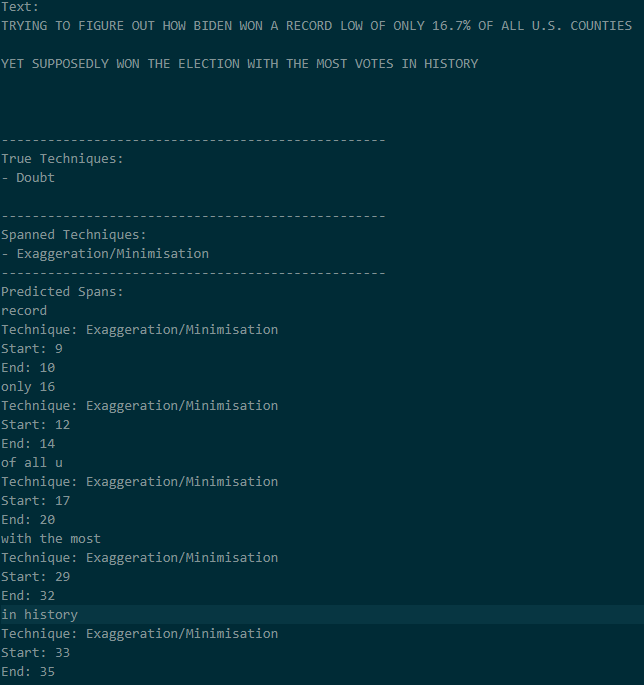

"only", "with the most", "in history" are all good examples of exaggeration/minimisation, and while it doesn't align with the ground truth according to the dataset, it is interpretable for a human. I know that, by itself, the Task 2 Spanner head is adequate for the task. And I know that by itself, I have accepted the performance of the Task 1 labeller, despite its limitations, with my given justifications. Because the whole model heavily relies on the output of the Task 1 model, despite the seemingly low evaluation metrics for the whole model, because I know that the model does adequately set forth the expectations that I had set for the spanner, I can safely accept this as my final model. 

In [89]:
torch.manual_seed(67)
whole_model = Task2WholeModel(final_task1_model,
                                SpecializedHeadMasking,
                                THRESHOLDS, 
                                tokenizer.sep_token_id).to(device)

metrics, examples = evaluate_task2(whole_model, task2_test_loader)

for key in metrics:
    print(f"{key}: {metrics[key] :.3f}")

accuracy: 0.875
precision: 0.158
recall: 0.379
f1: 0.178


In [ ]:
write_examples(examples, 
               "whole.txt",
               to_console=True,
               skip_unflagged_labels=False)

# Task C

## C1. Does it treat all sides the same?

The committee wants to know whether the tool is fair enough, and legible enough, to put in front of a room of teenagers who will test it on the most partisan thing in their feed.

One thing to heavily consider when looking at this model, is bias in the data. The data comes from this paper here: https://arxiv.org/pdf/2105.09284. And it outlines its data collection method by going through 26 public Facebook groups in order to procure its data. It does note that a large majority of these (23/26) come from political groups both US and Canadian with data from both left leaning, right leaning and centered groups. The data comes from a range of around late 2020 to early 2021 (an estimate, as the paper never mentions a direct range but just says they considered old posts, 3 months from when the latest post was made in that group). Nothing about this, so far sounds like a cause for concern for biases in the data. 

Looking through the dataset, however, I immediately notice that there seems to be a larger concentration of right-leaning samples in the data. With only few examples of left-leaning or centered data. One simple method I used to try to further examine this distribution was by passing training_set_task1.txt as a one-shot prompt into an LLM, ChatGPT GPT-6, in order to see the it's interpretation and rough distribution of the data. These are the prompt, and results for that prompt:

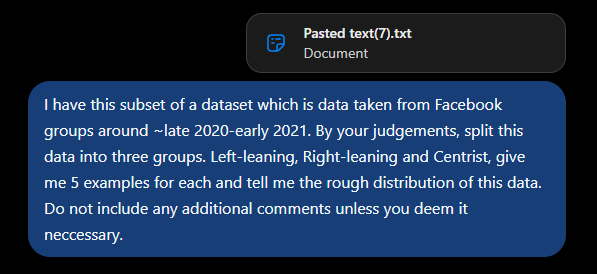
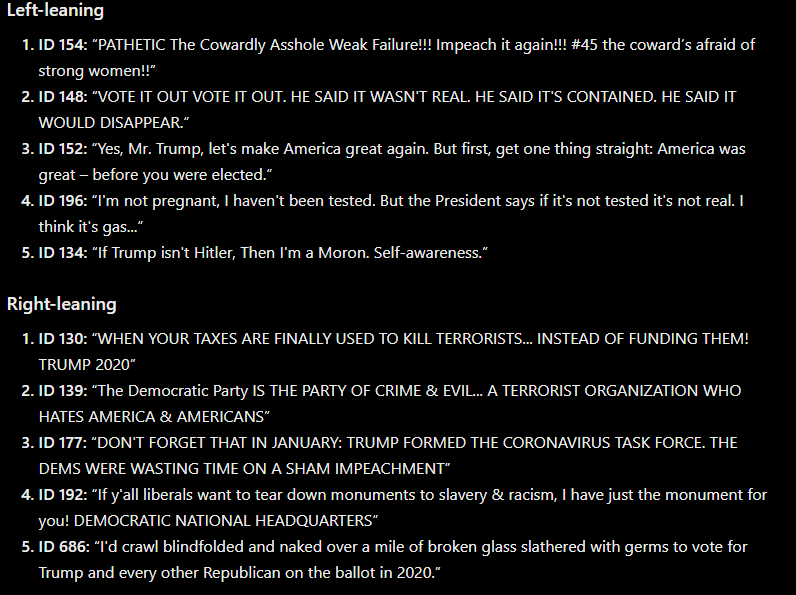
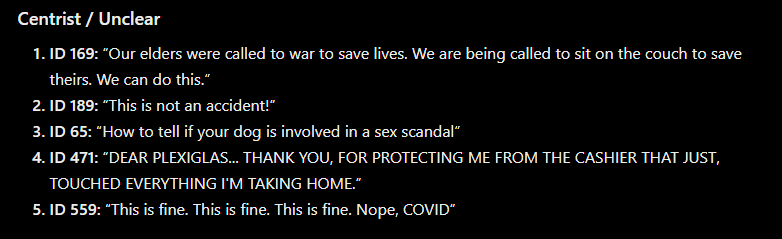
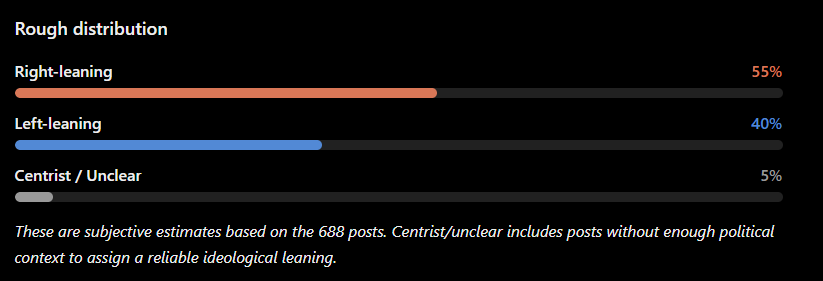

What is key to also understand is that this approach has faults with it, LLMs such as GPT-6 may have their own biases which may mean that the true distribution might be somewhat inconsistent to that of a regular human. This is simply done as a simple test for a rough understanding of the data distribution.

The data shows that there is a slightly increased share of right-leaning samples over left-leaning samples. With a 15% difference between the two alignments. Part of this could be due to a bias within the population that the paper samples, Facebook, which in a self-reported survey done by Katharina Bucholz and Statista in 2025 here: https://www.statista.com/chart/29395/political-preference-social-media/, seems to habor more right-leaning users. 

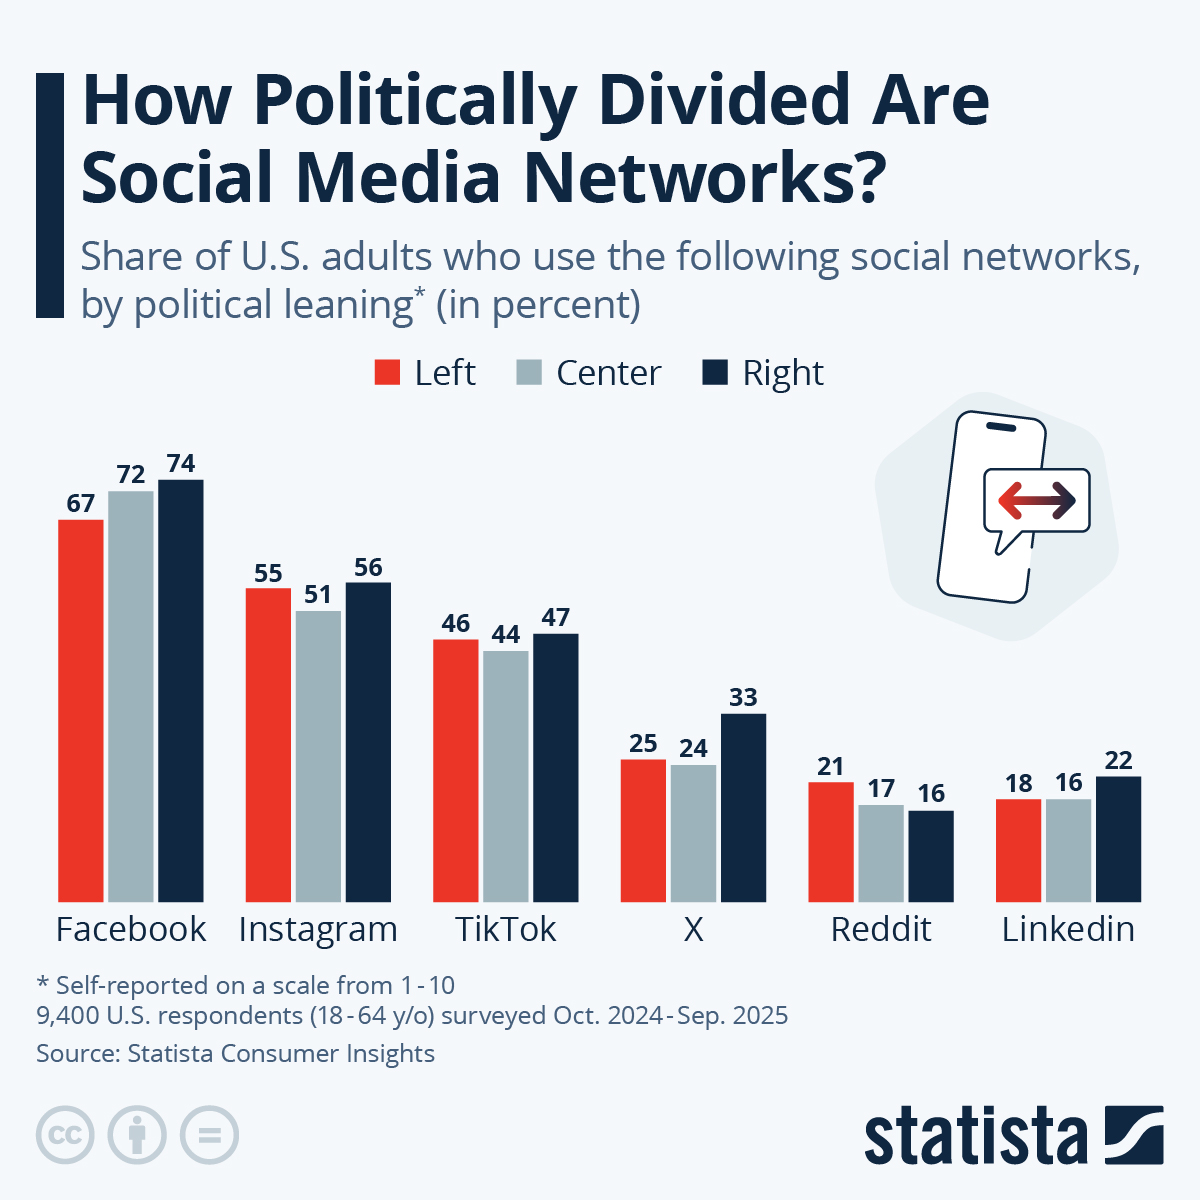

Another factor to consider is a bias due to world events, during late 2020 and early 2021, Republican leader Donald Trump lost his reelection bid against the Democratic leader Joe Biden. This may have caused an uptick in right-leaning posts and memes, talking about the election loss. We can see this reflected in the various samples in the data talking about the election loss, such as: "There is no voter fraud, we won fair and square\n\nThen you should have nothing to worry about\n\n"

What this could possibly indicate is that the model may be more tuned to right-leaning memes, it may be more critical with these memes, and might be more lenient with left-leaning memes. We can test this by checking the model's predicted logits across several left-leaning and right-leaning terms. Below, I take a sample of 5 left-leaning and right-leaning memes, and create a heatmap based on the model's probabilities for each label. Just as a reminder, below is the mapping of index to label.

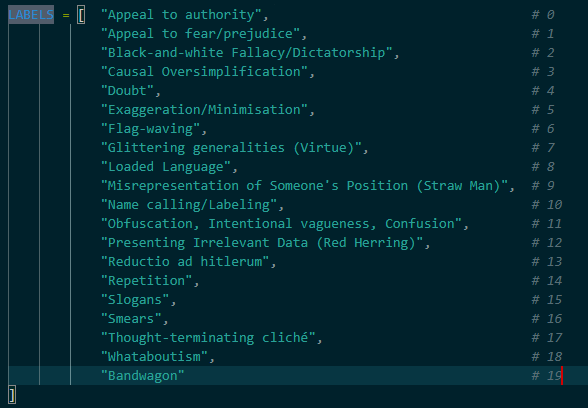

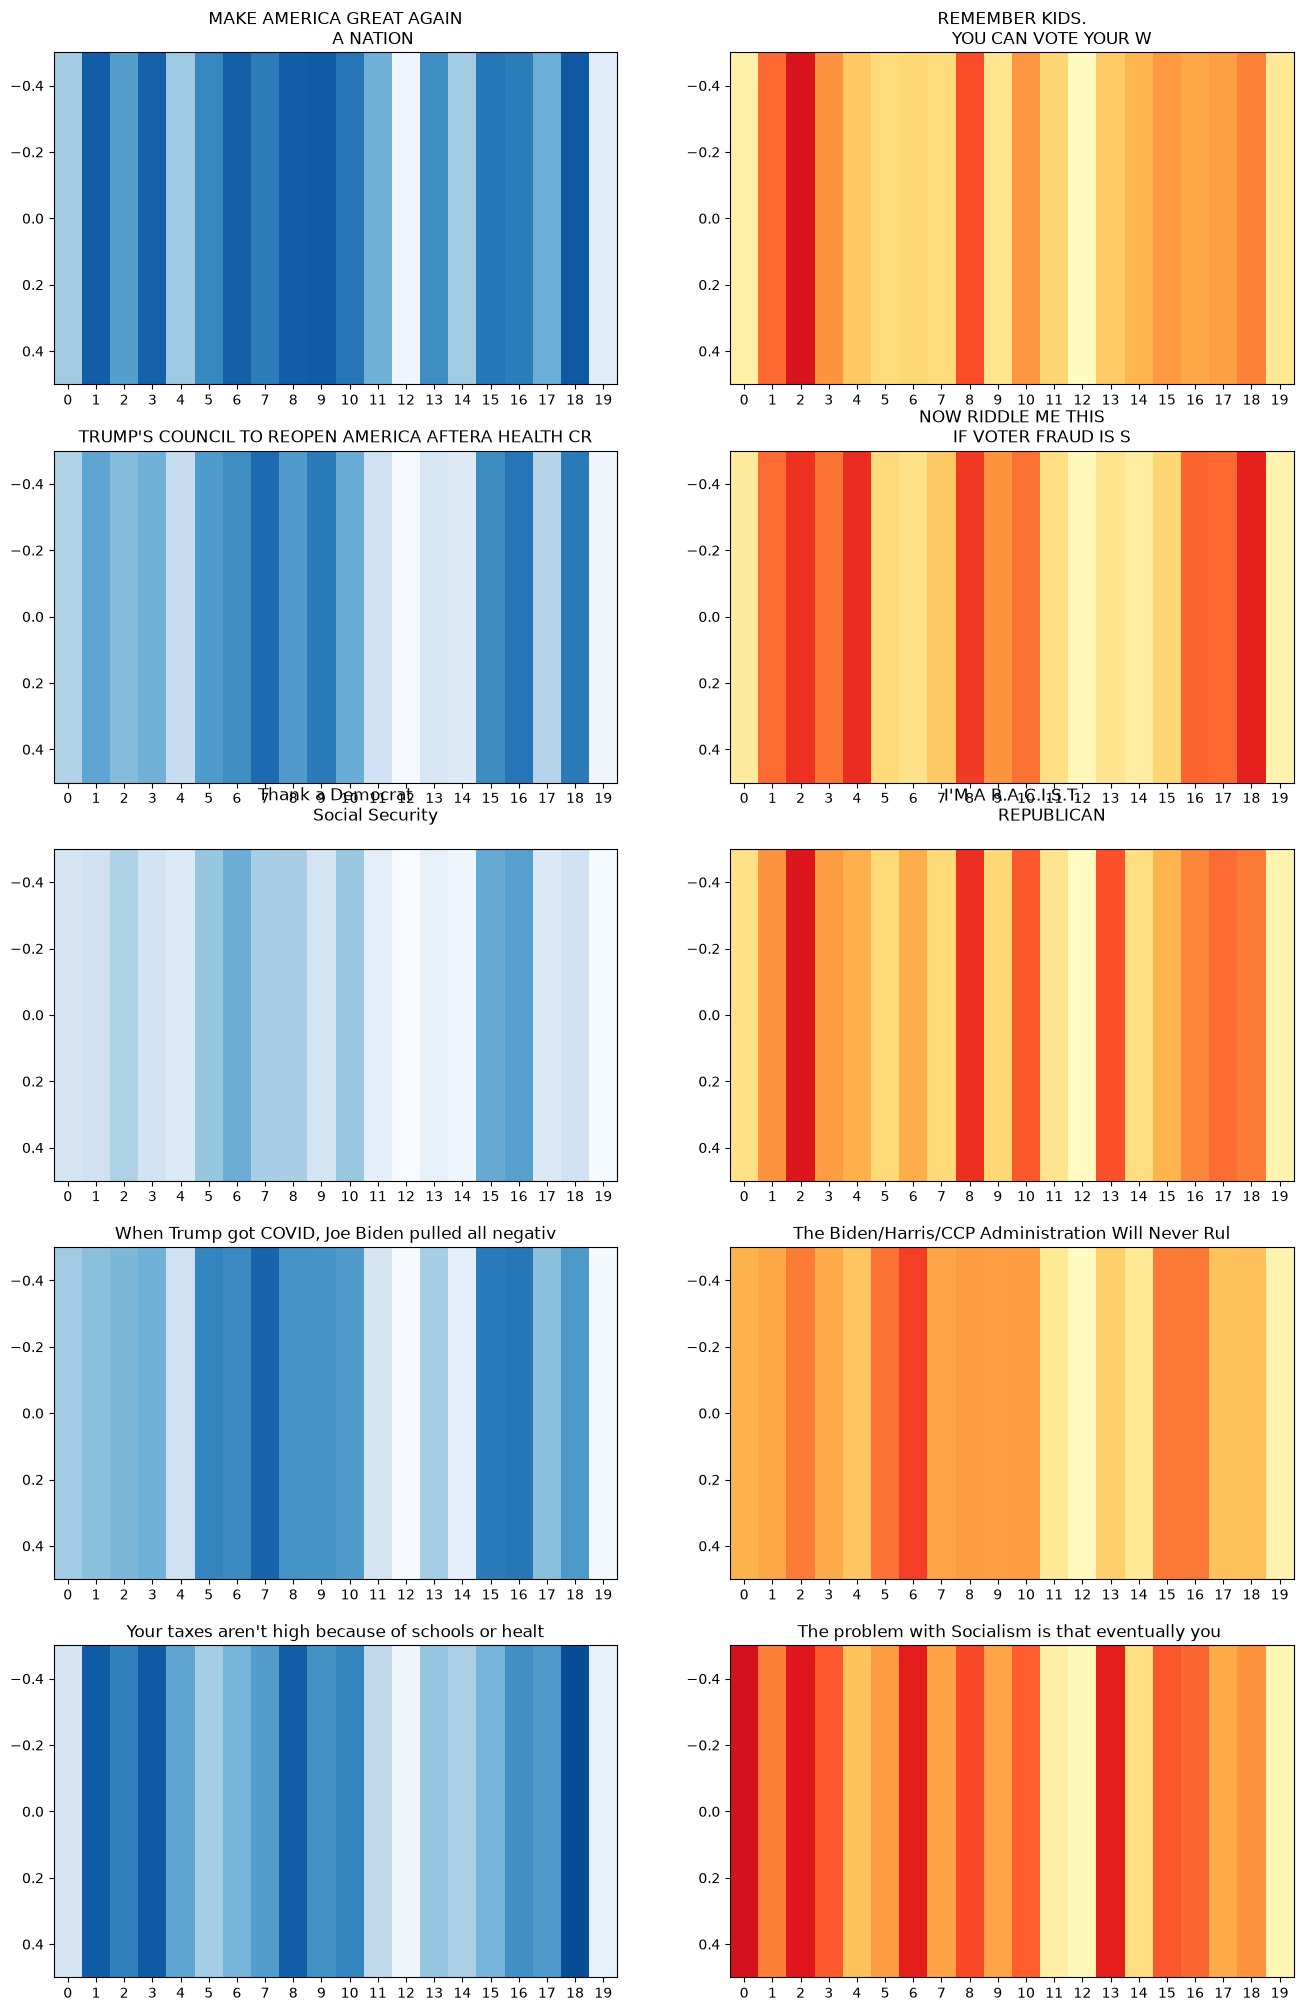

In [91]:
examples = ["""MAKE AMERICA GREAT AGAIN
                A NATION WHOSE HEALTHCARE WORKERS DON'T HAVE MASKS TO KEEP THEM FROM GETTING SICK, ATTENDING TO PATIENTS WHO CAN'T GET VENTILATORS TO KEEP THEM ALIVE, SURROUNDED BY SICK PEOPLE WHO CAN'T GET TESTED, ISN'T GREAT
                IT'S A DAMN DISGRACE.""",
            """TRUMP'S COUNCIL TO REOPEN AMERICA AFTERA HEALTH CRISIS.
                NOT ONE DOCTOR OR PUBLIC HEALTH SPECIALIST IN THE GROUP.
                BECAUSE TRUMP DOESN'T WANT ADVICE, HE WANTS AGREEMENT.""",
            """Thank a Democrat
                Social Security
                Medicare
                Veterans Administration
                Civil Rights
                Women's Suffrage
                Affordable Care Act
                Peace Corps
                Minimum Wage
                Unemployment""",
            """When Trump got COVID, Joe Biden pulled all negative ads, out of respect and basic human decency.
                When Hillary Clinton got pneumonia in 2016, Trump mercilessly MOCKED and ATTACKED her for it, saying "she can't even walk 15 feet to her car!" as his rally crowd cheered.
                SEE THE DIFFERENCE?""",
            """Your taxes aren't high because of schools or healthcare or food stamps.
                They are high because of rich assholes like Trump who game the system so they don't have to pay their fair share.""",
            """REMEMBER KIDS.
                YOU CAN VOTE YOUR WAY INTO SOCIALISM.
                BUT YOU HAVE TO SHOOT YOUR WAY OUT.""",
            """NOW RIDDLE ME THIS
            IF VOTER FRAUD IS SO LOW, WHY DO LIBERALS THROW A TEMPER TANTRUM WHENEVER ANYBODY BOTHERS TO CHECK?""",
            """I'M A R.A.C.I.S.T.
                REPUBLICAN
                AGAINST
                COMMUNIST
                INSANE
                SOCIALIST
                TERRORISM
                ARE YOU A R.A.C.I.S.T. TOO?""",
            """The Biden/Harris/CCP Administration Will Never Rule Over The United States of America""",
            """The problem with Socialism is that eventually you run out of other people's money.
                — Margaret Thatcher"""]

alignment_test_data = HFDataset(examples,
                                [0 for i in range(20)],
                                tokenizer=tokenizer,
                                max_length=64)

fig, axes = plt.subplots(5, 2, figsize=(16, 25))

final_task1_model.eval()
with torch.inference_mode():
    for i in range(10):
        example = alignment_test_data[i]
        input_ids = example['input_ids'].unsqueeze(0).to(device)
        attention_mask = example['attention_mask'].unsqueeze(0).to(device)
        
        logits = final_task1_model(input_ids=input_ids, 
                                   attention_mask=attention_mask, 
                                   lengths=lengths).logits
        
        probabilities = torch.sigmoid(logits).squeeze(0).cpu().numpy()
        
        heatmap = probabilities.reshape(1, -1)
        
        row = i if i < 5 else i - 5
        col = 0 if i < 5 else 1
        ax = axes[row, col]
        
        if col:
            im = ax.imshow(
                heatmap,
                cmap="YlOrRd",
                aspect="auto",
                vmin=0,
                vmax=1
            )
        else:
            im = ax.imshow(
                heatmap,
                cmap="Blues",
                aspect="auto",
                vmin=0,
                vmax=1
            )

        ax.set_xticks(range(len(LABELS)))
        ax.set_title(examples[i][:50])

Some new information was brought to light over this, however, (though its validity may be up in the air because of the small subset). It appears that the model tends to predict left-leaning memes as having a fairly distribution prediction scores for almost every technique, whereas right-leaning memes then to focus on several key techniques. The right-leaning memes seemt to especially use "Black and White Fallacy" (position 2), to a higher degree than the left-leaning memes. Left-leaning memes seem to have a high concentration on on the technique "Whataboutism" (position 18) which the right-leaning memes do not as much. However, this does not directly imply that "Left-leaning = Use this technique" or "Right-leaning = Use this technique". One experiment I came up with is to retry the evaluation using the exact same examples, however, swap the core partisan terms. For example "TRUMP 2024" becomes "BIDEN 2024". If there is a bias in the data, it should show by yielding different predictions. 

As a note: Some of the samples, I believed are unable to be swapped due to their associations relying more on subtext rather than actual key terms. As such I removed them from the next experiment.

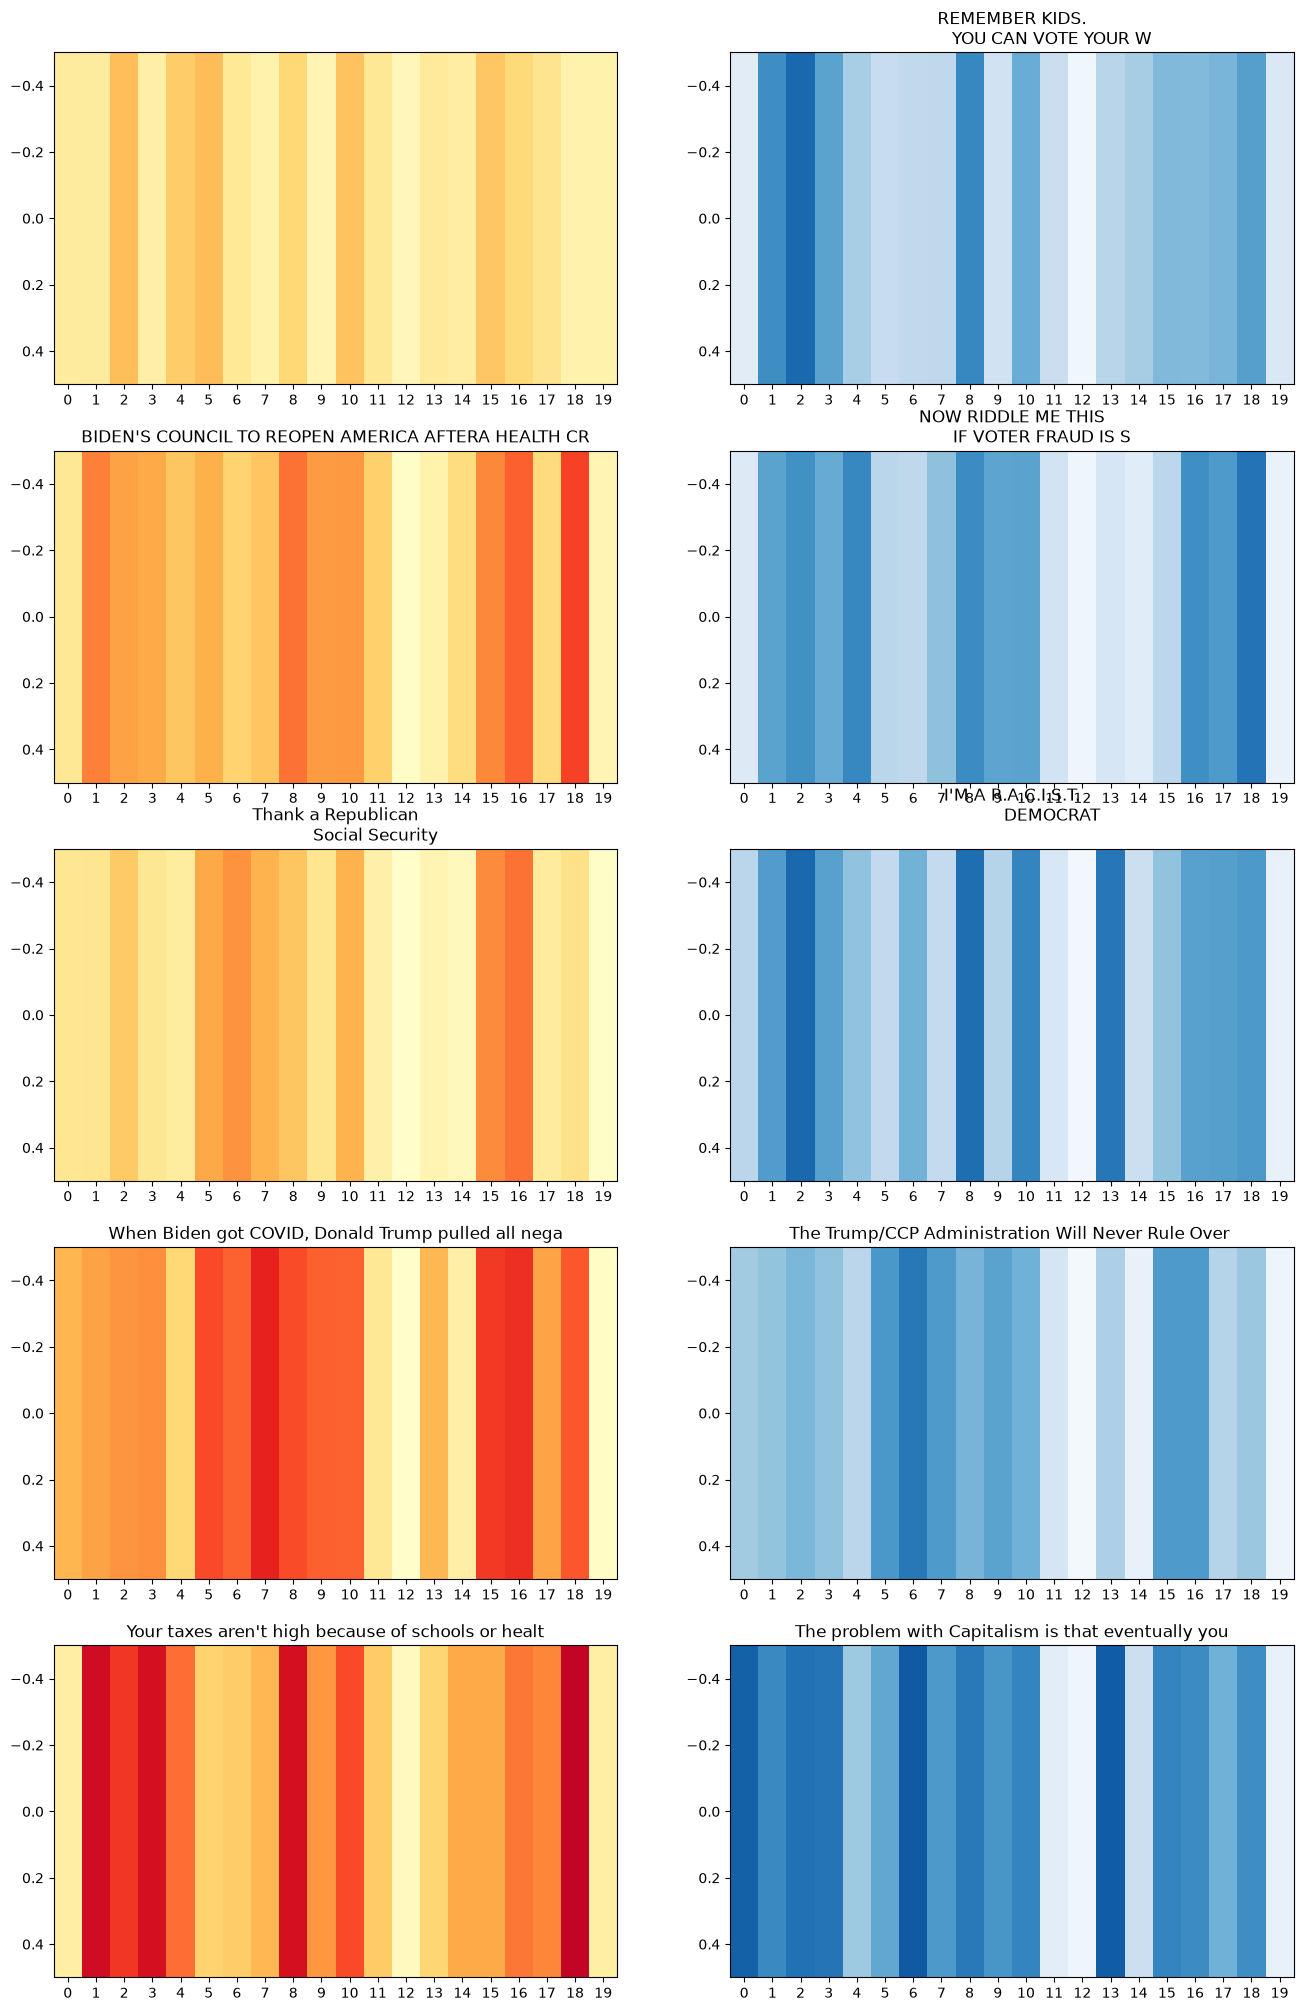

In [92]:
examples = ["""""",
            """BIDEN'S COUNCIL TO REOPEN AMERICA AFTERA HEALTH CRISIS.
                NOT ONE DOCTOR OR PUBLIC HEALTH SPECIALIST IN THE GROUP.
                BECAUSE BIDEN DOESN'T WANT ADVICE, HE WANTS AGREEMENT.""",
            """Thank a Republican
                Social Security
                Medicare
                Veterans Administration
                Civil Rights
                Women's Suffrage
                Affordable Care Act
                Peace Corps
                Minimum Wage
                Unemployment""",
            """When Biden got COVID, Donald Trump pulled all negative ads, out of respect and basic human decency.
                When Donald Trump got pneumonia in 2016, Hillary Clinton mercilessly MOCKED and ATTACKED him for it, saying "he can't even walk 15 feet to his car!" as his rally crowd cheered.
                SEE THE DIFFERENCE?""",
            """Your taxes aren't high because of schools or healthcare or food stamps.
                They are high because of rich assholes like Biden who game the system so they don't have to pay their fair share.""",
            """REMEMBER KIDS.
                YOU CAN VOTE YOUR WAY INTO CAPITALISM.
                BUT YOU HAVE TO SHOOT YOUR WAY OUT.""",
            """NOW RIDDLE ME THIS
            IF VOTER FRAUD IS SO LOW, WHY DO REPUBLICANS THROW A TEMPER TANTRUM WHENEVER ANYBODY BOTHERS TO CHECK?""",
            """I'M A R.A.C.I.S.T.
                DEMOCRAT
                AGAINST
                FASCIST
                INSANE
                CAPITALIST
                TERRORISM
                ARE YOU A R.A.C.I.S.T. TOO?""",
            """The Trump/CCP Administration Will Never Rule Over The United States of America""",
            """The problem with Capitalism is that eventually you run out of other people's money.
                — Ronald Reagan"""]
alignment_test_data = HFDataset(examples,
                                [0 for i in range(20)],
                                tokenizer=tokenizer,
                                max_length=64)

fig, axes = plt.subplots(5, 2, figsize=(16, 25))

final_task1_model.eval()
with torch.inference_mode():
    for i in range(10):
        example = alignment_test_data[i]
        input_ids = example['input_ids'].unsqueeze(0).to(device)
        attention_mask = example['attention_mask'].unsqueeze(0).to(device)
        
        logits = final_task1_model(input_ids=input_ids, 
                                   attention_mask=attention_mask, 
                                   lengths=lengths).logits
        
        probabilities = torch.sigmoid(logits).squeeze(0).cpu().numpy()
        
        heatmap = probabilities.reshape(1, -1)
        
        row = i if i < 5 else i - 5
        col = 0 if i < 5 else 1
        ax = axes[row, col]
        
        if col:
            im = ax.imshow(
                heatmap,
                cmap="Blues",
                aspect="auto",
                vmin=0,
                vmax=1
            )
        else:
            im = ax.imshow(
                heatmap,
                cmap="YlOrRd",
                aspect="auto",
                vmin=0,
                vmax=1
            )

        ax.set_xticks(range(len(LABELS)))
        ax.set_title(examples[i][:50])

Putting the two graphs side by side, we can see that there does not seem to be too much of a difference. The overall per-label predictions stay nearly identical, one of the big differences I noticed was in the "The problem with Socialism is..." where although the overall prediction shape stays the same, the concentration for some of the techniques were diluted by swapping the terms to be left-leaning. Although, I admit this might be because the original meme hinged on a Margaret Thatcher quote, who I was unable to find a perfect one-to-one equivalent for. 

"NOW RIDDLE ME THIS..." is another sample which seemed to decrease in probability concentrations after the swap to left-leaning. The only word that I swapped over was the use of the word "liberals" to "Democrats", so they are almost an exact mirror of each other. This might be the only sample which shows a legitimate possible proof of model bias. However, although concentrations drop, the overall shape remains the same, and the concentration decrease is not too extreme.

Although we can never truly confirm a model to be bias free, based on the subset of data that we tested here. I can not confidently report that the model is overtly biased in one way or another. The model seems to prioritize the patterns/shapes of a meme such as "[PERSON] is a terrible leader" -> Loaded Language, vs recognizing specific terms like "Donald Trump" -> Smear. 

## C2. Defend the system you built.

Someone on the committee has read that general-purpose AI does this with no training at all, and wants to know why the department is paying for something you built.

We can do some testing with a generic general-purpose AI to compare our outputs. To do this, I create a representative example set of our example data from Task 2, and then pass it through to ChatGPT GPT-6 and ask it to do the same task, unfortunately, with ChatGPT specifically, settings such as model temperature are not displayed so I am unable to record it. Below is a copy of the exact prompt I gave it. 

### Prompt:

"Your task is to label and span each "meme" as using one of 20 techniques as listed here:

LABELS = [  "Appeal to authority",                                  # 0
            "Appeal to fear/prejudice",                             # 1
            "Black-and-white Fallacy/Dictatorship",                 # 2
            "Causal Oversimplification",                            # 3
            "Doubt",                                                # 4
            "Exaggeration/Minimisation",                            # 5
            "Flag-waving",                                          # 6
            "Glittering generalities (Virtue)",                     # 7
            "Loaded Language",                                      # 8
            "Misrepresentation of Someone's Position (Straw Man)",  # 9
            "Name calling/Labeling",                                # 10
            "Obfuscation, Intentional vagueness, Confusion",        # 11
            "Presenting Irrelevant Data (Red Herring)",             # 12
            "Reductio ad hitlerum",                                 # 13
            "Repetition",                                           # 14
            "Slogans",                                              # 15
            "Smears",                                               # 16
            "Thought-terminating cliché",                           # 17
            "Whataboutism",                                         # 18
            "Bandwagon"                                             # 19
]

Each meme can use one, multiple, or none of the techniques. Once you've labelled the meme, create a "span" which is a multi-character sequence within the meme which employs one of the techniques. A meme may contain multiple spans for the same technique, i.e "This is a span of text" -> "This is a" (Technique A), "of text" (Technique B). 

For each meme return a dictionary, in this format
{"text": TEXT,
"labels": [
{
"start": CHARACTER POSITION IN STRING
"end": CHARACTER POSITION IN STRING
"technique": One of the allowed LABELS
"text_fragment": Span of text created by start and end.
}
]
}

ONLY RETURN THE DICTIONARY FOR EACH MEME, DO NOT DO ANY FURTHER EXPLAINING OR ANY OTHER OUTPUT. 

The next prompt will be the data, follow all of these guidelines for the data."

[LATER]

Each meme will be seperated by [SEP] do not consider the [SEP] string when making your judgements.

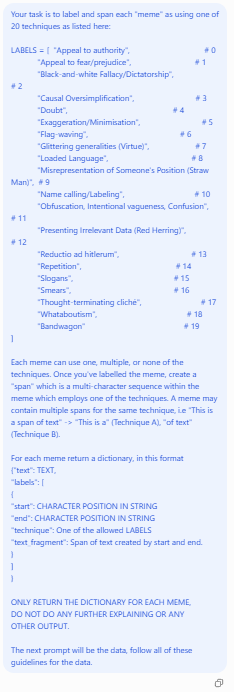

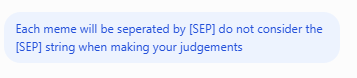

### Output:

In [93]:
representative_example_set = []
texts = []

for label in LABELS:
    example = task2_example_set[label][0]
    if example["text"] in texts:
        continue
    
    representative_example_set.append(task2_example_set[label][0])
    texts.append(example["text"])

In [94]:
Representative_Texts = [row["text"] for row in representative_example_set]
Representative_Labels = [row["spans"] for row in representative_example_set]

In [95]:
CHATGPT_OUTPUT = [
{
"text": "COWBOY WISDOM\n\"The water ain't gonna clear up 'til you get the pigs outa the creek!\" ",
"labels": [
{
"start": 0,
"end": 13,
"technique": "Appeal to authority",
"text_fragment": "COWBOY WISDOM"
},
{
"start": 15,
"end": 70,
"technique": "Obfuscation, Intentional vagueness, Confusion",
"text_fragment": "\"The water ain't gonna clear up 'til you get the pigs outa the creek!\""
}
]
},
{
"text": "WE ARE AT WAR!\n\nThere is a complex assault on our presidential election\nwith all the multifaceted tentacles of a terrorist organization and operation\n\n2020\nTERRORISM ",
"labels": [
{
"start": 1,
"end": 24,
"technique": "Appeal to fear/prejudice",
"text_fragment": "Appeal to fear/prejudice"
},
{
"start": 25,
"end": 38,
"technique": "Flag-waving",
"text_fragment": "WE ARE AT WAR!"
},
{
"start": 68,
"end": 91,
"technique": "Appeal to fear/prejudice",
"text_fragment": "complex assault on our"
},
{
"start": 68,
"end": 92,
"technique": "Loaded Language",
"text_fragment": "complex assault on our "
},
{
"start": 118,
"end": 179,
"technique": "Appeal to fear/prejudice",
"text_fragment": "the multifaceted tentacles of a terrorist organization and operation"
},
{
"start": 118,
"end": 179,
"technique": "Loaded Language",
"text_fragment": "the multifaceted tentacles of a terrorist organization and operation"
},
{
"start": 189,
"end": 198,
"technique": "Appeal to fear/prejudice",
"text_fragment": "TERRORISM"
},
{
"start": 189,
"end": 198,
"technique": "Loaded Language",
"text_fragment": "TERRORISM"
}
]
},
{
"text": "\nBy Bullet or Ballot\nRestoration Of The Republic Is Coming ! ",
"labels": [
{
"start": 1,
"end": 20,
"technique": "Slogans",
"text_fragment": "By Bullet or Ballot"
},
{
"start": 1,
"end": 20,
"technique": "Appeal to fear/prejudice",
"text_fragment": "By Bullet or Ballot"
},
{
"start": 21,
"end": 59,
"technique": "Flag-waving",
"text_fragment": "Restoration Of The Republic Is Coming !"
},
{
"start": 21,
"end": 59,
"technique": "Slogans",
"text_fragment": "Restoration Of The Republic Is Coming !"
}
]
},
{
"text": "\nTRUMP'S COUNCIL TO REOPEN AMERICA AFTERA HEALTH CRISIS.\n\nNOT ONE DOCTOR OR PUBLIC HEALTH SPECIALIST IN THE GROUP.\n\nBECAUSE TRUMP DOESN'T WANT ADVICE, HE WANTS AGREEMENT. ",
"labels": [
{
"start": 1,
"end": 56,
"technique": "Appeal to authority",
"text_fragment": "TRUMP'S COUNCIL TO REOPEN AMERICA AFTERA HEALTH CRISIS."
},
{
"start": 58,
"end": 116,
"technique": "Doubt",
"text_fragment": "NOT ONE DOCTOR OR PUBLIC HEALTH SPECIALIST IN THE GROUP."
},
{
"start": 118,
"end": 166,
"technique": "Causal Oversimplification",
"text_fragment": "BECAUSE TRUMP DOESN'T WANT ADVICE, HE WANTS AGREEMENT."
},
{
"start": 125,
"end": 166,
"technique": "Smears",
"text_fragment": "TRUMP DOESN'T WANT ADVICE, HE WANTS AGREEMENT."
}
]
},
{
"text": "\nTRYING TO FIGURE OUT HOW BIDEN WON A RECORD LOW OF ONLY 16.7% OF ALL U.S. COUNTIES\n\nYET SUPPOSEDLY WON THE ELECTION WITH THE MOST VOTES IN HISTORY ",
"labels": [
{
"start": 1,
"end": 81,
"technique": "Doubt",
"text_fragment": "TRYING TO FIGURE OUT HOW BIDEN WON A RECORD LOW OF ONLY 16.7% OF ALL U.S. COUNTIES"
},
{
"start": 1,
"end": 81,
"technique": "Exaggeration/Minimisation",
"text_fragment": "TRYING TO FIGURE OUT HOW BIDEN WON A RECORD LOW OF ONLY 16.7% OF ALL U.S. COUNTIES"
},
{
"start": 83,
"end": 145,
"technique": "Doubt",
"text_fragment": "YET SUPPOSEDLY WON THE ELECTION WITH THE MOST VOTES IN HISTORY"
},
{
"start": 83,
"end": 145,
"technique": "Exaggeration/Minimisation",
"text_fragment": "YET SUPPOSEDLY WON THE ELECTION WITH THE MOST VOTES IN HISTORY"
}
]
},
{
"text": "\nI will never concede!\n\nNO WAY IN HELL BIDEN WON! ",
"labels": [
{
"start": 1,
"end": 22,
"technique": "Thought-terminating cliché",
"text_fragment": "I will never concede!"
},
{
"start": 24,
"end": 47,
"technique": "Doubt",
"text_fragment": "NO WAY IN HELL BIDEN WON!"
},
{
"start": 24,
"end": 47,
"technique": "Loaded Language",
"text_fragment": "NO WAY IN HELL BIDEN WON!"
}
]
},
{
"text": "\n'Strike me down and you'll make me even more powerful' ",
"labels": [
{
"start": 1,
"end": 53,
"technique": "Exaggeration/Minimisation",
"text_fragment": "'Strike me down and you'll make me even more powerful'"
}
]
},
{
"text": "\nLIBERALS WOULD RATHER DIE THAN TRY HYDROXYCHLOROQUINE?\nLET THEM. \nIT'S CALLED NATURAL SELECTION ",
"labels": [
{
"start": 1,
"end": 55,
"technique": "Appeal to fear/prejudice",
"text_fragment": "LIBERALS WOULD RATHER DIE THAN TRY HYDROXYCHLOROQUINE?"
},
{
"start": 1,
"end": 55,
"technique": "Misrepresentation of Someone's Position (Straw Man)",
"text_fragment": "LIBERALS WOULD RATHER DIE THAN TRY HYDROXYCHLOROQUINE?"
},
{
"start": 56,
"end": 65,
"technique": "Exaggeration/Minimisation",
"text_fragment": "LET THEM."
},
{
"start": 66,
"end": 91,
"technique": "Loaded Language",
"text_fragment": "IT'S CALLED NATURAL SELECTION"
},
{
"start": 66,
"end": 91,
"technique": "Name calling/Labeling",
"text_fragment": "IT'S CALLED NATURAL SELECTION"
}
]
},
{
"text": "\nThe Democrats New America ",
"labels": []
},
{
"text": "\n\"We put together I think the most extensive and inclusive voter fraud organization in the history of American politics.\"\n-Joe Biden ",
"labels": [
{
"start": 1,
"end": 114,
"technique": "Appeal to authority",
"text_fragment": "\"We put together I think the most extensive and inclusive voter fraud organization in the history of American politics.\""
},
{
"start": 59,
"end": 114,
"technique": "Exaggeration/Minimisation",
"text_fragment": "voter fraud organization in the history of American politics."
},
{
"start": 1,
"end": 114,
"technique": "Doubt",
"text_fragment": "\"We put together I think the most extensive and inclusive voter fraud organization in the history of American politics.\""
}
]
},
{
"text": "\nIF THEY ARE SO SURE THEY WON WHY HASNT KAMALA RESIGNED HER SENATE SEAT? ",
"labels": [
{
"start": 1,
"end": 70,
"technique": "Doubt",
"text_fragment": "IF THEY ARE SO SURE THEY WON WHY HASNT KAMALA RESIGNED HER SENATE SEAT?"
},
{
"start": 1,
"end": 70,
"technique": "Causal Oversimplification",
"text_fragment": "IF THEY ARE SO SURE THEY WON WHY HASNT KAMALA RESIGNED HER SENATE SEAT?"
}
]
},
{
"text": "\nPeople are so quick to forget.\n\nWedding bands that were removed from Holocaust victims prior to being executed, 1945. \nEach ring represents a destroyed family. \nNever forget, Nazis tore down statues.\nBanned free speech.\nBlamed economic hardships on one group of people. Instituted gun control.\nSound Familiar? ",
"labels": [
{
"start": 1,
"end": 30,
"technique": "Thought-terminating cliché",
"text_fragment": "People are so quick to forget."
},
{
"start": 32,
"end": 109,
"technique": "Appeal to fear/prejudice",
"text_fragment": "Wedding bands that were removed from Holocaust victims prior to being executed, 1945."
},
{
"start": 111,
"end": 146,
"technique": "Appeal to fear/prejudice",
"text_fragment": "Each ring represents a destroyed family."
},
{
"start": 148,
"end": 159,
"technique": "Thought-terminating cliché",
"text_fragment": "Never forget"
},
{
"start": 161,
"end": 187,
"technique": "Reductio ad hitlerum",
"text_fragment": "Nazis tore down statues."
},
{
"start": 188,
"end": 208,
"technique": "Reductio ad hitlerum",
"text_fragment": "Banned free speech."
},
{
"start": 209,
"end": 264,
"technique": "Reductio ad hitlerum",
"text_fragment": "Blamed economic hardships on one group of people. Instituted gun control."
},
{
"start": 265,
"end": 279,
"technique": "Appeal to fear/prejudice",
"text_fragment": "Sound Familiar?"
},
{
"start": 265,
"end": 279,
"technique": "Reductio ad hitlerum",
"text_fragment": "Sound Familiar?"
}
]
},
{
"text": "\n9-11 NEVER FORGET\n\n11-3 NEVER FORGET ",
"labels": [
{
"start": 1,
"end": 18,
"technique": "Thought-terminating cliché",
"text_fragment": "9-11 NEVER FORGET"
},
{
"start": 1,
"end": 18,
"technique": "Slogans",
"text_fragment": "9-11 NEVER FORGET"
},
{
"start": 20,
"end": 37,
"technique": "Repetition",
"text_fragment": "11-3 NEVER FORGET"
},
{
"start": 20,
"end": 37,
"technique": "Slogans",
"text_fragment": "11-3 NEVER FORGET"
}
]
},
{
  "text": "\nHYPOCRISY MUCH?!\nMacy's Thanksgiving Day Parade to March On Despite Pandemic\n\nBusinesses Are Closing Permanently, People Are Losing Everything!\nLet's Have A Parade! ",
  "labels": [
    {
      "start": 1,
      "end": 16,
      "technique": "Doubt",
      "text_fragment": "HYPOCRISY MUCH?"
    },
    {
      "start": 18,
      "end": 69,
      "technique": "Doubt",
      "text_fragment": "Macy's Thanksgiving Day Parade to March On Despite Pandemic"
    },
    {
      "start": 71,
      "end": 128,
      "technique": "Appeal to fear/prejudice",
      "text_fragment": "Businesses Are Closing Permanently, People Are Losing Everything!"
    },
    {
      "start": 71,
      "end": 128,
      "technique": "Exaggeration/Minimisation",
      "text_fragment": "Businesses Are Closing Permanently, People Are Losing Everything!"
    }
  ]
},
{
"text": "\nHe's been telling us for months about election fraud...\nDo you really believe he hasn't been preparing for this moment???\n3..2.. 1 ....Checkmate!! ",
"labels": [
{
"start": 1,
"end": 54,
"technique": "Doubt",
"text_fragment": "He's been telling us for months about election fraud..."
},
{
"start": 55,
"end": 122,
"technique": "Doubt",
"text_fragment": "Do you really believe he hasn't been preparing for this moment???"
},
{
"start": 123,
"end": 145,
"technique": "Exaggeration/Minimisation",
"text_fragment": "3..2.. 1 ....Checkmate!!"
},
{
"start": 123,
"end": 145,
"technique": "Obfuscation, Intentional vagueness, Confusion",
"text_fragment": "3..2.. 1 ....Checkmate!!"
}
]
},
{
"text": "\nWhat do AOC, Pelosi, McConnell, and Pence all have in common?\nThey know the COVID vaccine is safe and effective. ",
"labels": [
{
"start": 1,
"end": 60,
"technique": "Doubt",
"text_fragment": "What do AOC, Pelosi, McConnell, and Pence all have in common?"
},
{
"start": 61,
"end": 109,
"technique": "Appeal to authority",
"text_fragment": "They know the COVID vaccine is safe and effective."
}
]
}
]

In [96]:
CHATGPT_OUTPUT = np.array(CHATGPT_OUTPUT)

CHATGPT_Texts = [row["text"] for row in CHATGPT_OUTPUT]
CHATGPT_Labels = [row["labels"] for row in CHATGPT_OUTPUT]

CHATGPT_ds = Task2Dataset(CHATGPT_Texts, CHATGPT_Labels, tokenizer)

In [97]:
y_true = np.asarray(Representative_Labels)
y_pred = np.stack([
    x.detach().cpu().numpy() for x in CHATGPT_ds.span_labels
])

print("ChatGPT Metrics")
print(f"Accuracy: {np.mean(y_true.reshape(len(y_true), -1) == y_pred.reshape(len(y_pred), -1)):.3f}")

print(f"Precision: {precision_score(y_true.reshape(len(y_true), -1), y_pred.reshape(len(y_pred), -1), average='macro'):.3f}")

print(f"Recall: {recall_score(y_true.reshape(len(y_true), -1), y_pred.reshape(len(y_pred), -1), average='macro'): .3f}")

ChatGPT Metrics
Accuracy: 0.983
Precision: 0.047
Recall:  0.056


c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [98]:
whole_model.eval()

with torch.inference_mode():
    predicted_spans = []
    for example in representative_example_set:
        predicted_span = whole_model(example["input_ids"].unsqueeze(0).to(device),
                                     example["attention_mask"].unsqueeze(0).to(device), 
                                     torch.tensor([example["lengths"]]).to(device))
        
        predicted_span = torch.sigmoid(predicted_span)
        predicted_span = predicted_span >= 0.5
        
        predicted_spans.append(predicted_span)
        
predicted_spans = torch.cat(predicted_spans, dim=0).to(device)

In [99]:
y_pred = predicted_spans.detach().cpu().numpy()
y_true = y_true[:, 1:-1, :]
y_true_flat = y_true.reshape(len(y_true), -1)
y_pred_flat = y_pred.reshape(len(y_pred), -1)

print("Whole Model Metrics: ")
print(f"Accuracy:  {np.mean(y_true_flat == y_pred_flat):.3f}")
print(f"Precision: {precision_score(y_true_flat, y_pred_flat, average='macro', zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_true_flat, y_pred_flat, average='macro', zero_division=0):.3f}")

Whole Model Metrics: 
Accuracy:  0.965
Precision: 0.042
Recall:    0.064


From an initial pass through, both the custom model and the generic mode perform similarly, and the commitee member is correct with their assertion. Why might our model be preferable to a generic LLM then? By using an off the shelf model like ChatGPT, we are relying on a complete black box and are completely reliant on the supplier to ensure that the model has no underlying issues. Issues such as the kind of data that it was trained on might subtly introduce biases when doing the predicting, and since we are reliant on the LLM's supplier, we will not know those issues, until we already start using the tool. With our model, we have control and knowledge of every aspect, such as the source of the transformer models we use, the source for our dataset, and can do testing to check for things such as model bias, etc. 

Furthermore, one major constraint of the task is that "Students upload memes from their own feeds and most of them are minors, so nothing a student enters may leave the device", many free to use LLMs such as ChatGPT will require an online connection to upload our data to the web. Self-hosted offline LLMs such as Ollama might be suitable, but it still does not solve the previous issue of it being a complete black box. 

## C3. Does the label head agree with the span head?

When the model says Name Calling and the tagger underlines nothing, the teacher has a label with nothing to point at. Measure how often your two heads disagree, per technique and overall, and say what the tool should put on screen when they do.

Due to the architecture of our model, our label head is unable to "disagree with the span head". Techniques predicted by the label head are the only techniques that the spanner head is able to predict for. However, this does not mean that the model will always create a span for every predicted technique. A model can predict that a meme "This meme uses technique X" uses technique X, but there are times where the spanner is unable to detect a specific instance in the meme. 

We can measure this first by isolating the spanner head and predicting spans for each technique. Then we can see how often the spanner head does not create a span for a given technique in a meme, if it is given the ground truth techniques.

In [100]:
SpecializedHeadMasking.eval()

total_spans, empty_spans = 0, 0

per_label_total_spans = {label: 0 for label in LABELS}
per_label_empty_spans = {label: 0 for label in LABELS}

missing_examples = []

with torch.inference_mode():
    for batch in task2_test_loader:
        techniques = batch['labels'].to(device)
        lengths = batch['lengths'].to(device)
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        texts = batch['text']
        
        logits = SpecializedHeadMasking(input_ids,
                                        attention_mask,
                                        lengths,
                                        techniques)
        
        probabilities = torch.sigmoid(logits)
        predicted_spans = probabilities >= 0.5
        
        valid_tokens = attention_mask.bool()
        technique_mask = techniques.bool()
        
        has_spans = predicted_spans.any(dim=1)
        total_spans += technique_mask.sum().item()
        
        missing = technique_mask & ~has_spans
        
        empty_spans += missing.sum().item()
        
        for i, label in enumerate(LABELS):
            per_label_total_spans[label] += technique_mask[:, i].sum().item()
            per_label_empty_spans[label] += missing[:, i].sum().item()
        
        for i in range(len(texts)):
            missing_labels = []
            
            if missing[i].any():
                missing_labels = [
                    LABELS[j]
                    for j in range(techniques.shape[1])
                    if missing[i, j].item()
                ]

            if missing_labels:
                missing_examples.append((texts[i], missing_labels))

print(f"Total Techniques Presented: {total_spans}")
print(f"Empty Spans for: {empty_spans}")
print(f"For a percentage of {100.0 * empty_spans/total_spans :.3f}%")
print()

for label in LABELS:
    total = per_label_total_spans[label]
    missing = per_label_empty_spans[label]
    print(f"{label} missing: {missing} / {total} ({100.0 * missing/total if total > 0 else 0:.3f}%)")

Total Techniques Presented: 335
Empty Spans for: 27
For a percentage of 8.060%

Appeal to authority missing: 0 / 7 (0.000%)
Appeal to fear/prejudice missing: 1 / 10 (10.000%)
Black-and-white Fallacy/Dictatorship missing: 0 / 7 (0.000%)
Causal Oversimplification missing: 0 / 3 (0.000%)
Doubt missing: 0 / 28 (0.000%)
Exaggeration/Minimisation missing: 1 / 19 (5.263%)
Flag-waving missing: 0 / 6 (0.000%)
Glittering generalities (Virtue) missing: 0 / 11 (0.000%)
Loaded Language missing: 19 / 100 (19.000%)
Misrepresentation of Someone's Position (Straw Man) missing: 0 / 1 (0.000%)
Name calling/Labeling missing: 5 / 53 (9.434%)
Obfuscation, Intentional vagueness, Confusion missing: 0 / 1 (0.000%)
Presenting Irrelevant Data (Red Herring) missing: 0 / 4 (0.000%)
Reductio ad hitlerum missing: 0 / 3 (0.000%)
Repetition missing: 1 / 1 (100.000%)
Slogans missing: 0 / 19 (0.000%)
Smears missing: 0 / 45 (0.000%)
Thought-terminating cliché missing: 0 / 6 (0.000%)
Whataboutism missing: 0 / 10 (0.000%)


This method tells us that given the ground truth techniques, we seem to be unable to create a span overall about 8% of the time. The per label missing criteria seem to all be quite low, the largest percentage being Repetitions, with 1/1 missing (although this is an extreme case, since we only have one sample), Loaded Language with 19% and Name Calling with 10%. We can do another test to see whether, given the techniques from the label head, will that change? 

In [101]:
SpecializedHeadMasking.eval()
final_task1_model.eval()

total_spans, empty_spans = 0, 0
thresholds = torch.tensor(THRESHOLDS).to(device)

per_label_total_spans = {label: 0 for label in LABELS}
per_label_empty_spans = {label: 0 for label in LABELS}

with torch.inference_mode():
    for batch in task2_test_loader:
        lengths = batch['lengths'].to(device)
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        
        # Truncate to length 64
        label_input_ids = input_ids[:, :64].clone()
        label_attention_mask = attention_mask[:, :64].clone()
        
        # Restore [SEP]
        long_sequences = attention_mask.sum(dim=1) > 64
        
        label_input_ids[long_sequences, 63] = tokenizer.sep_token_id
        label_attention_mask[long_sequences, 63] = 1
        
        label_logits = final_task1_model(input_ids,
                                         attention_mask).logits
        
        label_probabilities = torch.sigmoid(label_logits)
        techniques = label_probabilities >= thresholds
        
        logits = SpecializedHeadMasking(input_ids,
                                        attention_mask,
                                        lengths,
                                        techniques)
        
        probabilities = torch.sigmoid(logits)
        predicted_spans = probabilities >= 0.5
        
        valid_tokens = attention_mask.bool()
        technique_mask = techniques.bool()
        
        has_spans = predicted_spans.any(dim=1)
        total_spans += technique_mask.sum().item()
        
        missing = technique_mask & ~has_spans
        
        empty_spans += missing.sum().item()
        
        for i, label in enumerate(LABELS):
            per_label_total_spans[label] += technique_mask[:, i].sum().item()
            per_label_empty_spans[label] += missing[:, i].sum().item()
        
        for i in range(len(texts)):
            missing_labels = []
            
            if missing[i].any():
                missing_labels = [
                    LABELS[j]
                    for j in range(techniques.shape[1])
                    if missing[i, j].item()
                ]

            if missing_labels:
                missing_examples.append((texts[i], missing_labels))
        
        

print(f"Total Techniques Presented: {total_spans}")
print(f"Empty Spans for: {empty_spans}")
print(f"For a percentage of {100.0 * empty_spans/total_spans :.3f}%")
print()

for label in LABELS:
    total = per_label_total_spans[label]
    missing = per_label_empty_spans[label]
    print(f"{label} missing: {missing} / {total} ({100.0 * missing/total if total > 0 else 0 :.3f}%)")

Total Techniques Presented: 715
Empty Spans for: 88
For a percentage of 12.308%

Appeal to authority missing: 0 / 7 (0.000%)
Appeal to fear/prejudice missing: 2 / 27 (7.407%)
Black-and-white Fallacy/Dictatorship missing: 0 / 86 (0.000%)
Causal Oversimplification missing: 0 / 41 (0.000%)
Doubt missing: 0 / 33 (0.000%)
Exaggeration/Minimisation missing: 4 / 48 (8.333%)
Flag-waving missing: 13 / 30 (43.333%)
Glittering generalities (Virtue) missing: 0 / 27 (0.000%)
Loaded Language missing: 28 / 98 (28.571%)
Misrepresentation of Someone's Position (Straw Man) missing: 0 / 29 (0.000%)
Name calling/Labeling missing: 16 / 48 (33.333%)
Obfuscation, Intentional vagueness, Confusion missing: 1 / 2 (50.000%)
Presenting Irrelevant Data (Red Herring) missing: 0 / 0 (0.000%)
Reductio ad hitlerum missing: 2 / 16 (12.500%)
Repetition missing: 5 / 10 (50.000%)
Slogans missing: 10 / 46 (21.739%)
Smears missing: 0 / 89 (0.000%)
Thought-terminating cliché missing: 7 / 25 (28.000%)
Whataboutism missing: 0 

With the whole model, we see a similar level of overall missing spans, although this one is slightly higher by 2 percentage points. However, more interesting is the per-label missing spans which has substantially increased across several labels. We need to understand that, with the previous experiment, we know that the techniques passed in can make no mistakes since they're taken from the ground truths, and as such will have a "good" span for that technique. In this experiment, the techniques predicted by the first part of the model may not be correct, and as if an "incorrect" technique is passed, the model may have a hard time figuring out a "good" span for it, the closest thing to what a "disagreement betweent the label head and spanner head" can be within our architecture. The model's spanning capabilities is extremely limited by the "goodness" of the label head. 

However, it is key to remember that, as explained at the end of Task 2. That a technique not being part of the ground truth for a meme, does not make it inherently wrong. We need to always consider that "technique" is a vague label that people with different interpretations can apply to different memes. Hence why the empty span percentage is not much higher, if a model sees a meme and predicts technique X even though it is not part of the ground truth, the spanner head, might be able to "understand" its reasoning and still create a span on its own. 

Next, we should look at the examples of missing spans coming from the spanner head with ground truths passed in, as this will give us a better understanding of why some spans will not appear even with ground truths. 

In [102]:
for example in missing_examples[:15]:
    print("------------------------------------------------")
    print(example[0])
    print(example[1])
    print("------------------------------------------------")
    

------------------------------------------------
I will never concede!

NO WAY IN HELL BIDEN WON!

['Loaded Language']
------------------------------------------------
------------------------------------------------
'Strike me down and you'll make me even more powerful'
['Loaded Language']
------------------------------------------------
------------------------------------------------
THE GOVERNMENT IS CORRUPT ON EVERY LEVEL BUT DON'T WORRY, THE GOVERNMENT WILL INVESTIGATE
ITSELF AND TELL YOU WHAT REALLY HAPPENED.

['Loaded Language']
------------------------------------------------
------------------------------------------------
HAIL JUSTICE AMY CONEY-BARRETT

['Loaded Language']
------------------------------------------------
------------------------------------------------
COWBOY WISDOM
"The water ain't gonna clear up 'til you get the pigs outa the creek!"

['Loaded Language']
------------------------------------------------
------------------------------------------------
RIP F

I do notice some errors which I believe the model should have gotten by itself. Items such as:

"I will never concede!

NO WAY IN HELL BIDEN WON!"

is very much a case of Loaded Language where the spanned text "NO WAY IN HELL" should be easily interpretable by the model. However, there are a few examples in which I believe the model, with its limitations, will have a very hard time creating a span for. For the item "HAIL JUSTICE AMY CONEY-BARRETT", specifically, although the ground truth says it is a piece of Loaded Language, it is extremely difficult, even for a human like me, to know which part of the text specifically illicits this technique. This is because much of the knowledge of the meme comes from knowledge of who "Amy Coney Barrett" is. Although it could be assumed that she may be a part of the transformer's training data (as distilbert-base-uncased was trained on wikipedia data from before 2024), it might not have truly understood what the name is. A human interpretation of the meme could be something like: "Justice Amy Coney Barrett is a conservative Supreme Court justice and has become a concern for Democrats after her appointment gave conservatives a 6-3 majority. 'HAIL JUSTICE AMY CONEY BARRET' uses Loaded Language because it is a gloating of a victory". A model which might not have that information, will not be able to make that distinction. 

A model like ours, which does not have the benefit of knowing up to date information, trends, people, etc. When memes fundamentally uses up-to-date information, references, etc. Our model which does not have these information, will not be able to confidently create a span.

However, a human is able to. Because our final goal is to utilize this as a teaching tool, where teachers use our model as a teaching apparatus to analyze a meme, they are able to fill in the blanks that our model is unable to fulfill. They, who know the up-to-date references, people, news and trends, will be able to better explain why one part of a meme may illicit a certain technique that the model is unable to explain. Instead of creating an empty span, the model can instead print out a list of predicted labels, so that if a span is missing, an operator is able to either fill in those blanks, or discard it based on their judgements. 

## C4. Will it work here? 

The corpus was not collected here, not recently, and not from teenagers. Your classrooms are Australian, the year is 2026, and the memes come out of a Year 10 student's own feed that week.

There are two main mismatches within our dataset when compared to our aimed practical environment. That being time and location. Since the dataset was procured from 2020-2021 posts, our data is quite old so it might not be able to pick up on the trends and techniques that modern day memes will use. To complicate things further, we aim to use this model here, in Australian schools, whereas the data previously was procured from the USA. Although it can be argued that these US memes may reach wide and far enough that the average Australian teenager will come across and engage with some of them, memes that target Australian specific issues / topics will most likely struggle with the model.

I want to test this, so I decided to take a set of 5 memes, focused on Australia from Facebook, the same source as the original training dataset. Below are 5 memes I have procured and their links, I tried to find memes which, explicitly target Australian issues / are for an Australian audience, are within the months of September / October, and contain textual information that we can use for testing our model.

### Meme 1:
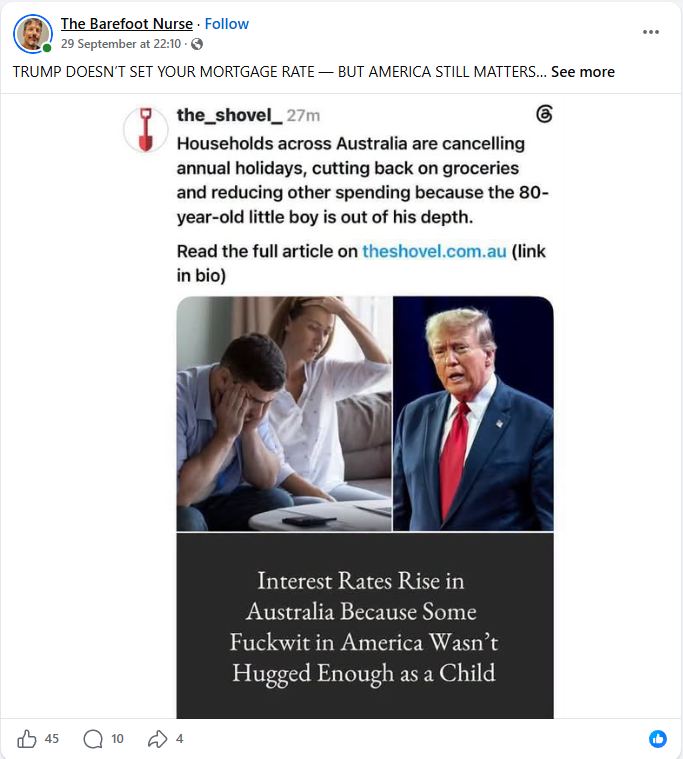
https://www.facebook.com/share/p/19VKYTXq7u/

### Meme 2:
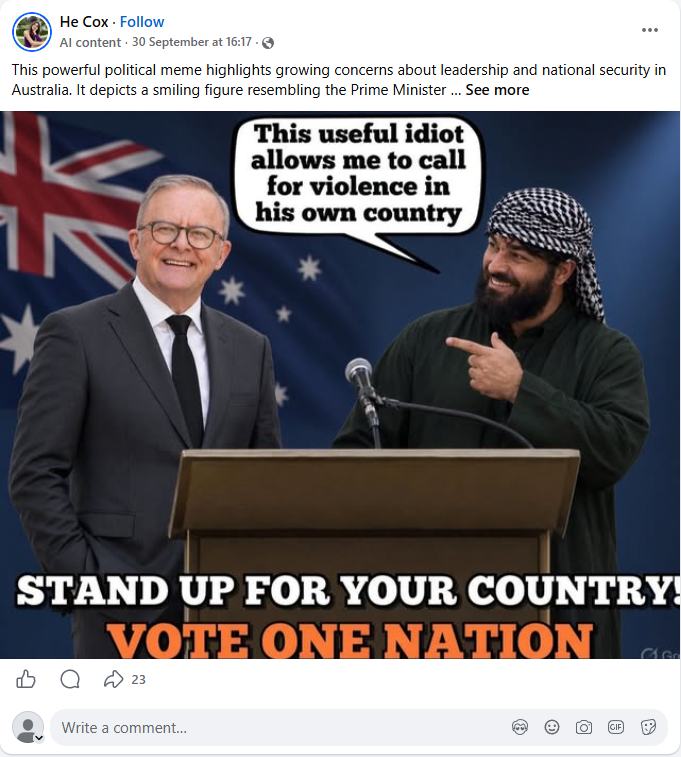
https://www.facebook.com/share/p/1Dr1JNsdvM/

### Meme 3:
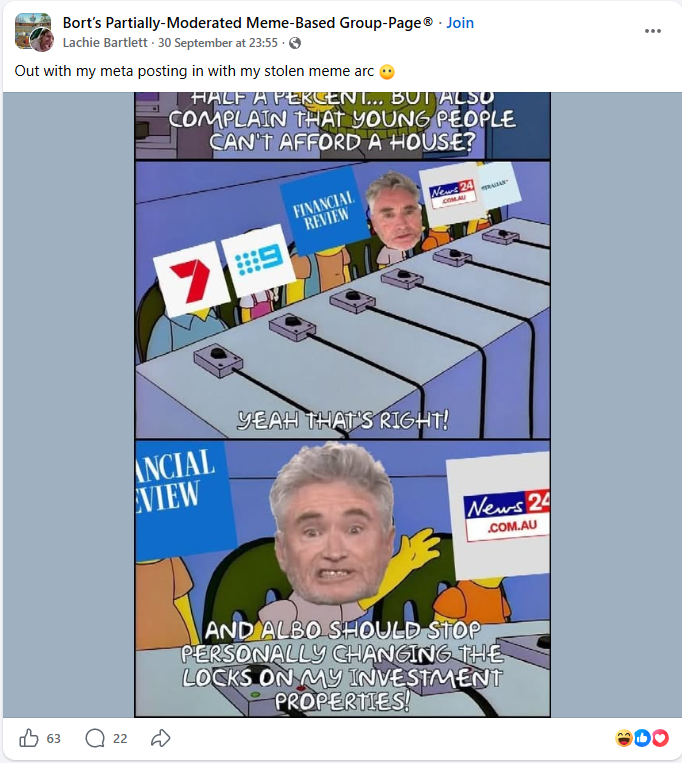
https://www.facebook.com/share/p/1en41eM7jV/

### Meme 4:
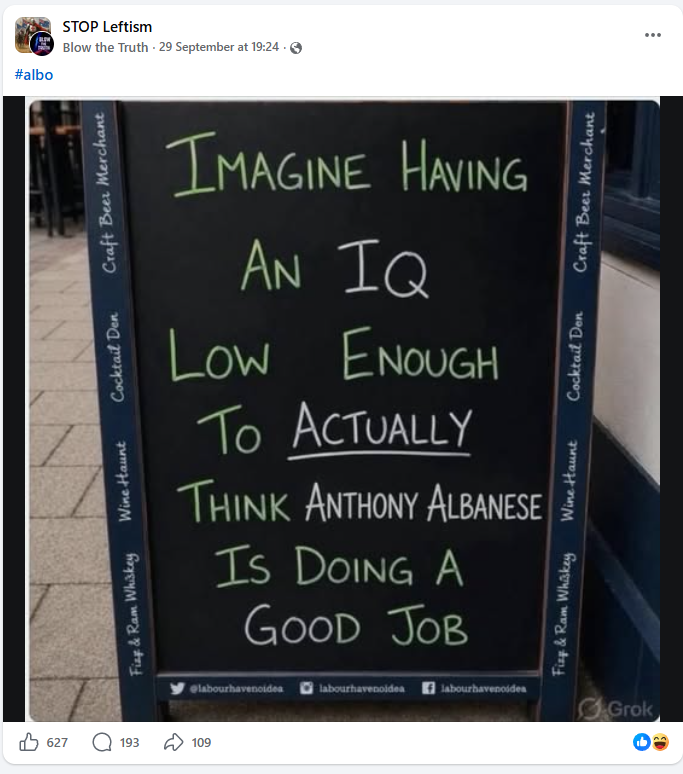
https://www.facebook.com/share/p/1GZPM2tCDx/

### Meme 5:
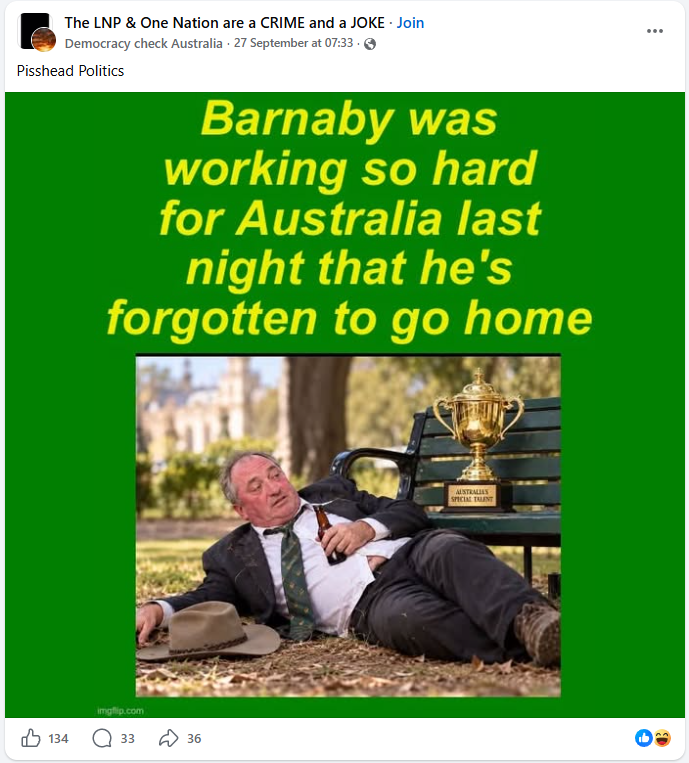
https://www.facebook.com/share/p/1FLHEg8iRJ/

In [ ]:
examples = ["""Interest Rates Rise in Australia Because Some Fuckwite in America Wasn't Hugged Enough as a Child""",
            """This useful idiot allows me to call for violence in his own country
            STAND UP FOR YOUR COUNTRY! VOTE ONE NATION""",
            """So you want to create mass panic when house prices drop half a percent... but also complain that young people can't afford a house?
            Yeah that's right!
            And Albo should stop personally changing the locks on my investment properties""",
            """Imagine having an iq low enough to actually think Anthony Albanese is doing a good job""",
            """Barnaby was working so hard for Australia last night that he's forgotten to go home"""]

australian_test_data = HFDataset(examples,
                                 [0 for i in range(20)],
                                 tokenizer=tokenizer,
                                 max_length=64)

final_task1_model.eval()
with torch.inference_mode():
    for i in range(5):
        print("--------------------------------------")
        example = australian_test_data[i]
        input_ids = example['input_ids'].unsqueeze(0).to(device)
        attention_mask = example['attention_mask'].unsqueeze(0).to(device)
                
        logits = final_task1_model(input_ids=input_ids, 
                                    attention_mask=attention_mask, 
                                    lengths=lengths).logits
        
        probabilities = torch.sigmoid(logits).squeeze(0).cpu().numpy()
        
        predicted_indices = [j for j, probability in enumerate(probabilities)
                             if probability >= THRESHOLDS[j]]        
        
        print(f"Text: {examples[i][:50]}")
        print(f"Predicted Labels:")
        
        if len(predicted_indices) == 0:
            print("None")
        
        for index in predicted_indices:
            print(f"- {LABELS[index]}")
        
        print("--------------------------------------")
        

--------------------------------------
Text: Interest Rates Rise in Australia Because Some Fuck
Predicted Labels:
- Loaded Language
- Smears
--------------------------------------
--------------------------------------
Text: This useful idiot allows me to call for violence i
Predicted Labels:
- Black-and-white Fallacy/Dictatorship
- Exaggeration/Minimisation
- Flag-waving
- Loaded Language
- Name calling/Labeling
- Slogans
- Smears
--------------------------------------
--------------------------------------
Text: So you want to create mass panic when house prices
Predicted Labels:
- Appeal to fear/prejudice
- Black-and-white Fallacy/Dictatorship
- Causal Oversimplification
- Doubt
- Loaded Language
- Name calling/Labeling
- Smears
- Thought-terminating cliché
- Whataboutism
--------------------------------------
--------------------------------------
Text: Imagine having an iq low enough to actually think 
Predicted Labels:
None
--------------------------------------
-----------------

: 

### The Modelling Gap:

Looking at the predicted labels for each sample meme, it appears that the model does somewhat still work with the modern Australian memes. In particular "Interest rates rise..." predicts techniques Loaded Language and Smears, which I as an independent human believe is an accurate assessment based on the provided meme, using loaded language such as "fuckwit" and "because some fuckwit in America wasn't hugged enough as a child" with a smear aimed towards "the fuckwit in America".

In the second example, "This useful idiot allows me..." is another very good example of somewhat good labelling. Black-and-White Fallacy/Dictatorship seems to be correctly attributed as the meme uses the idea of "If you don't vote for One Nation, then you will have people entering the country wreaking violence". Exaggeration is being used to exemplify the consequences of "not voting for One Nation". Whataboutism can be said to be used for "this is the future if you don't vote for One Nation", etc. This same "has good predicted techniques" also follows for meme 3.

The final two memes unfortunately has no predicted techniques for each. I notice that the first 3 memes follow a very generic pattern which requires no internal knowledge to understand the memes. For example, the first meme does not require a reader to understand "what are the reasons for interest rates increasing in Australia" or "who is the 'fuckwit in America' referring to'", all a reader needs to know is that we are smearing a specific individual. Similarly, meme 2 requires no real understanding of "what is the One Nation party?" all a reader must know is that "if I don't want this future, I have to vote for them". Meme 4 specifically calls out Anthony Albanese, the Australian PM, and although it can be said that the model, like in Meme 2, should just care that "only a very low iq person would think [Person] is doing a good job", full understanding of Albanese's standing in the modern Australian viewpoint, would enhance a reader's understanding of the meme. Meme 5 is the strongest example of this phenomenon, where, on its own, the sentence "[PERSON] was working so hard for Australia last night that he's forgotten to go home" does not, by itself does not illicit any form of malice. It is with the added context that the subject is Barnaby, who is a prominent Australian figure and his role as a politician, that the meme gains its weight. 

The model, which was not trained on Australian data, will struggle to understand these Australian specific jokes/references, but will do fine when it comes to generic patterns like "[PERSON] is a fuckwit". 

### The User Gap:

Another thing we need to consider is how this model may effect a learning environment in our Australian classrooms. Even if considering our model will predict well and attaches some labels to a student's meme, we need to consider the way to approach explaining the labels and why they are being used for some meme. If we were to assume that a classroom would independently put forth memes and just get the model's output, with no operator like a teacher to guide interpretting the model's outputs, what would happen is a reinforcement of "What this AI labels a meme as, is concrete proof. If the AI says this model utilizes smear tactics and loaded language, or creates red herrings and tries to obfuscate the truth, then it MUST be true". We need to consider that, although our model may think that, firstly, it is liable to make mistakes and secondly, we need a safe way of approaching its output and explaining why it does certain things. 

For example, in a classroom, if a child's family has a political view supporting One Nation, and Meme 2 is being used as an input for the model. The model will give forth its labelled techniques, which although from an objective standpoint might seem accurate, taking it as face value would hurt that child. It is imperative that a teacher is able to safely engage the topic of "why this model thinks this specific sequence illicits this behavour" while trying to maintain the safety of all the children. Furthermore, that operator role also gives the teacher the ability to discard certain techniques that a model may predict, if it is unneccessary or inaccurate. Or explain possible biases that the model may have. As well as the ability to explain why a model might not be able to create a span for a specific meme. 